# Extreme energy events under climate change — main-text figures

Consolidated results notebook drawing from the three analysis notebooks
(`extremes.ipynb`, `extremes_seasonal.ipynb`, `extremes_duration_clusters.ipynb`).
It produces the eight main-text figures plus the seasonal driver-anomaly
box-strips, on the common configuration: **RCP8.5**, demand `DE/2050`, supply
`HIGH/2040`, reservoir + battery (utility + prosumer) flexibility, **TAILS**
thresholds calibrated on **CERRA** (1991–2020), **SPA** event detection, GWL
windows **+1.5 / +2.0 / +3.0 °C**, 6 TYNDP zones, 9 GCM–RCM chains.

**Figure list**
1. Residual-load distributional shift (KDE by zone × season)
2. Zone × season % change in event count, both duration classes, with sign-agreement stippling (B1b)
3. Duration-class breakdown of annual events (sub_daily / multi_day)
4. Diurnal profile of events + PV context
5. Seasonal-conditional event frequency (Iberian rise vs Central-Eastern decline)
6. Seasonal flexibility attenuation grid
7. **G2** — compound zone-pair co-occurrence: all events (annual), then sub_daily vs multi_day (with sign-agreement marks on the change-vs-+1.5 °C panels)
8. Robustness — Wilcoxon signed-rank & ensemble agreement (n_events, per duration class)

Plus: seasonal driver-anomaly box-strips.

**Threshold integrity.** Thresholds are floored at genuine deficit (RL > 0) and
zones with a deficit fraction below 5 % are flagged *degenerate* (Nordic, a
hydro-rich net-surplus zone). Flagged zones are excluded from cross-zone tail
comparisons; see the coverage diagnostic below.

## 0 · Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy_analysis.extreme_value import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
    resolve_gwl_period_definitions,
    compute_seasonal_evt_metrics,
    compute_zone_pair_cooccurrence,
    compute_unserved_energy_fraction,
    compute_flexibility_attenuation_metrics,
    flex_metric_columns,
)
from cordex2energy_analysis.extremes_analysis import (
    extract_event_diurnal_profiles,
    compute_duration_stratified_metrics,
    compute_seasonal_duration_stratified_metrics,
    compute_zone_pair_cooccurrence_by_duration,
)
from cordex2energy_analysis.extremes_thresholds import (
    compute_active_threshold,
    calibrate_seasonal_active_thresholds,
    diagnose_threshold_coverage,
)
from cordex2energy_analysis.extremes_events import DEFAULT_DURATION_BINS
from cordex2energy_analysis.plotting_extremes import (
    resolve_model_periods,
    plot_residual_load_kde,
    plot_seasonal_conditional_metrics,
    plot_event_diurnal_profile,
    plot_zone_cooccurrence_heatmaps,
    plot_seasonal_component_anomaly_distributions,
    plot_component_anomaly_distributions,
    spread_qpair,
    SPREAD_LABEL,
    model_spread_bounds,
)
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/c2e-analysis/share/proj failed


In [3]:
paths = json.load(open("../paths.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_extremes  = path_data_processed / "extremes"
path_residual_load  = path_data_extremes / "residual_load"

# ── Common configuration (identical across the three source notebooks) ──────
climate_scenario = "rcp85"
demand_scenario  = "DE"
demand_year      = 2050
supply_scenario  = "LOW"
supply_year      = 2050
rolling_window_residual_load = 1
use_reservoir_hydro    = True
use_batteries          = True
use_prosumer_batteries = True
# Utility batteries only (prosumer is always heuristic + country-level):
flexibility_scheme = "system"         # "market" (per-asset market operation) | "system" (lumped, annual QP)
battery_dispatch_method = "optimal"   # "heuristic" | "optimal" (rolling day-ahead QP)  [market only]
utility_dispatch_level  = "country"      # "zone" (pooled over the 6 balancing zones) | "country"  [market only]

run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"
if rolling_window_residual_load and rolling_window_residual_load > 1:
    run_tag += f"_rlsmooth_{rolling_window_residual_load}"
if use_reservoir_hydro:
    run_tag += "_reservoirdispatch"
if use_batteries:
    run_tag += "_batteries"
    if use_prosumer_batteries:
        run_tag += "_prosumer"
    if flexibility_scheme == "system":
        run_tag += "_sysflex"
    else:
        if battery_dispatch_method == "optimal":
            run_tag += "_optbatt"
        if utility_dispatch_level == "country":
            run_tag += "_utilcountry"

THRESHOLD_METHOD       = "PERCENTILE"   # "TAILS" | "EVT" | "PERCENTILE"
# Percentile (0-100) of the positive residual-load distribution used when
# THRESHOLD_METHOD == "PERCENTILE" (ignored otherwise).
THRESHOLD_PERCENTILE   = 95.0
USE_CERRA_THRESHOLDS   = True
USE_WARMING_LEVELS     = True
WARMING_LEVELS         = [1.5, 2.0, 3.0]
EVENT_DETECTION_METHOD = "spa"

# Two-regime duration split (≤24 h diurnal vs >24 h synoptic)
DURATION_BINS = {"sub_daily": (0, 24), "multi_day": (24, float("inf"))}
DURATION_CLASS_ORDER = list(DURATION_BINS.keys())
duration_palette = {"sub_daily": "#3182bd", "multi_day": "#e6550d"}

# Co-occurrence dilation window: ±72 h (24 steps at 3 h) — spans the synoptic
# blocking timescale, consistent with the source notebooks.
COOC_WINDOW_STEPS = 8

# Robustness fraction: fraction of models that must agree on the presence of an event for it to be considered robust.
ROBUSTNESS_FRACTION = 2/3
# Inter-model spread shown in figures (bands / whiskers / heatmap [lo-hi]):
#   "iqr" -> P25-P75 (robust; recommended for n=9)  |  "minmax" -> full ensemble range
SPREAD = "iqr"
print(f"run_tag = {run_tag}")

run_tag = DE_2050_LOW_2050_reservoirdispatch_batteries_prosumer_sysflex


In [4]:
ds_residual_load_zonal = []
ds_components_zonal    = []
for folder in sorted(path_residual_load.glob("*")):
    if not folder.is_dir() or folder.name == "cerra":
        continue
    run_dir = folder / run_tag
    if not run_dir.exists():
        print(f"  Skipping {folder.name}: no '{run_tag}' subfolder")
        continue
    model_name = "_".join(folder.name.split("_")[:-1])
    ds_residual_load_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(dim={"model": [model_name]})
    )
    ds_components_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(dim={"model": [model_name]})
    )
ds_residual_load_zonal = xr.concat(ds_residual_load_zonal, dim="model", join="outer")
ds_components_zonal    = xr.concat(ds_components_zonal,    dim="model", join="outer")
print(f"Loaded {len(ds_residual_load_zonal.model)} models for run '{run_tag}'")

Loaded 9 models for run 'DE_2050_LOW_2050_reservoirdispatch_batteries_prosumer_sysflex'


In [5]:
# ── Constants, palettes, period definitions ─────────────────────────────────
season_map = {
    3: "MAM", 4: "MAM", 5: "MAM", 6: "JJA", 7: "JJA", 8: "JJA",
    9: "SON", 10: "SON", 11: "SON", 12: "DJF", 1: "DJF", 2: "DJF",
}
season_order  = ["DJF", "MAM", "JJA", "SON"]
season_months = {s: [m for m, ss in season_map.items() if ss == s] for s in season_order}

period_defs = {
    "Reference":   (REFERENCE_PERIOD[0],   REFERENCE_PERIOD[1]),
    "Mid-Century": (MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]),
    "End-Century": (END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1]),
}
PERIOD_LABEL  = {"Reference": "1_Reference", "Mid-Century": "2_Mid-Century", "End-Century": "3_End-Century"}
period_colors = {"Reference": "#4A90E2", "Mid-Century": "#F5A623", "End-Century": "#E24A4A"}

driver_palette = {
    "Demand": "#D95F02", "PV": "#E6AB02", "Wind Onshore": "#7570B3",
    "Wind Offshore": "#1B7C3D", "Hydro RoR": "#3182BD",
    "Reservoir Hydro": "#08519C", "Battery": "#8B5A2B",
}
driver_cols = {
    "Demand": "Demand_Driven_Share_%", "PV": "PV_Driven_Share_%",
    "Wind Onshore": "Wind_Onshore_Driven_Share_%", "Wind Offshore": "Wind_Offshore_Driven_Share_%",
    "Hydro RoR": "Hydro_RoR_Driven_Share_%", "Reservoir Hydro": "Reservoir_Hydro_Driven_Share_%",
    "Battery": "Battery_Driven_Share_%",
}
anomaly_component_cols = {
    "Demand": "Avg_Demand_Anomaly_GWh", "PV": "Avg_PV_Anomaly_GWh",
    "Wind Onshore": "Avg_Wind_Onshore_Anomaly_GWh", "Wind Offshore": "Avg_Wind_Offshore_Anomaly_GWh",
    "Hydro RoR": "Avg_Hydro_RoR_Anomaly_GWh", "Reservoir Hydro": "Avg_Reservoir_Anomaly_GWh",
    "Battery": "Avg_Battery_Anomaly_GWh",
}

zones    = ds_residual_load_zonal["zone"].values
models   = ds_residual_load_zonal["model"].values
n_models = len(models)
ROBUSTNESS_THRESHOLD = int(np.ceil(n_models * ROBUSTNESS_FRACTION))
print(f"Zones  : {list(zones)}")
print(f"Models : {n_models}")
print(f"Robustness Threshold : {ROBUSTNESS_THRESHOLD}")

Zones  : [np.str_('British_Isles'), np.str_('Central_Eastern'), np.str_('Central_Western'), np.str_('Iberian_Peninsula'), np.str_('Nordic'), np.str_('South_East')]
Models : 9
Robustness Threshold : 6


In [6]:
# ── GWL period resolution (per-model 20-year windows centred on crossings) ──
if USE_WARMING_LEVELS:
    period_defs, PERIOD_LABEL, period_colors = resolve_gwl_period_definitions(
        warming_levels=WARMING_LEVELS,
        models=models,
        chain_meta_path="../models.json",
        gwl_yaml_path=path_data_processed / "cmip5_warming_levels_all_ens_1861_1900.yml",
        climate_scenario=climate_scenario,
    )
    PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}
    print("GWL periods:", list(period_defs.keys()))
    for label, windows in period_defs.items():
        print(f"  {label}: {len(windows)}/{len(models)} models")
period_names = list(period_defs.keys())

GWL periods: ['+1.5°C', '+2.0°C', '+3.0°C']
  +1.5°C: 9/9 models
  +2.0°C: 9/9 models
  +3.0°C: 9/9 models


In [7]:
# ── CERRA threshold calibration (annual + seasonal), floored + gated ────────
import time
_cerra_run_dir = path_residual_load / "cerra" / run_tag
_ds_rl_c   = xr.open_dataset(_cerra_run_dir / "residual_load_zonal.nc")
_ds_comp_c = xr.open_dataset(_cerra_run_dir / "components_zonal.nc")
_common_c  = np.intersect1d(_ds_rl_c.time.values, _ds_comp_c.time.values)
_ds_rl_c   = _ds_rl_c.sel(time=_common_c)
_ds_comp_c = _ds_comp_c.sel(time=_common_c)
_ds_clim_c = calculate_climatological_baseline(_ds_comp_c)
_ds_met_c  = compute_continuous_system_metrics(_ds_rl_c, _ds_comp_c, _ds_clim_c)
_da_rl_c   = _ds_met_c["residual_load"].where(_ds_met_c["residual_load"] > 0)

_t0 = time.perf_counter()
da_cerra_threshold = compute_active_threshold(
    _da_rl_c, THRESHOLD_METHOD, percentile=THRESHOLD_PERCENTILE
)
cerra_season_thresholds, _ = calibrate_seasonal_active_thresholds(
    _da_rl_c, zones, season_order, season_months, THRESHOLD_METHOD,
    percentile=THRESHOLD_PERCENTILE,
)
print(f"CERRA {THRESHOLD_METHOD} annual thresholds (GWh, floored):")
for z in zones:
    print(f"  {str(z):<18} {float(da_cerra_threshold.sel(zone=z)):>8.1f}")
print(f"[{time.perf_counter() - _t0:.1f}s]")

DEGENERATE_ZONES = list(da_cerra_threshold.attrs.get("degenerate_zones", []))
ANALYSIS_ZONES   = [z for z in zones if str(z) not in DEGENERATE_ZONES]
print(f"\nDegenerate (excluded from cross-zone tail comparison): {DEGENERATE_ZONES}")
print(f"Analysis zones: {[str(z) for z in ANALYSIS_ZONES]}")

CERRA PERCENTILE annual thresholds (GWh, floored):
  British_Isles         168.4
  Central_Eastern       190.6
  Central_Western       475.8
  Iberian_Peninsula      82.4
  Nordic                 74.4
  South_East            137.1
[0.1s]

Degenerate (excluded from cross-zone tail comparison): []
Analysis zones: ['British_Isles', 'Central_Eastern', 'Central_Western', 'Iberian_Peninsula', 'Nordic', 'South_East']


In [8]:
# ── Coverage diagnostic: deficit fraction + threshold degeneracy ────────────
cov_annual = diagnose_threshold_coverage(_da_rl_c, thresholds=da_cerra_threshold)
print("Annual coverage:")
print(cov_annual.to_string(index=False))
cov_seasonal = diagnose_threshold_coverage(
    _da_rl_c, thresholds=cerra_season_thresholds,
    season_map=season_map, season_order=season_order,
)
print("\nDegenerate (zone, season) cells:")
print(cov_seasonal[cov_seasonal["degenerate"]].to_string(index=False))

Annual coverage:
             zone season  positive_fraction  threshold_gwh  threshold_floored_gwh  degenerate
    British_Isles    ALL                1.0     168.371185             168.371185       False
  Central_Eastern    ALL                1.0     190.640379             190.640379       False
  Central_Western    ALL                1.0     475.760944             475.760944       False
Iberian_Peninsula    ALL                1.0      82.440097              82.440097       False
           Nordic    ALL                1.0      74.367451              74.367451       False
       South_East    ALL                1.0     137.100462             137.100462       False

Degenerate (zone, season) cells:
Empty DataFrame
Columns: [zone, season, positive_fraction, threshold_gwh, threshold_floored_gwh, degenerate]
Index: []


In [9]:
# ── Per-model caches + thresholds (single CERRA threshold applied to all) ────
_cache_rl, _cache_comp, _cache_clim = {}, {}, {}
active_thresholds, season_active_thresholds = {}, {}

for model in models:
    ds_rl_m = (ds_residual_load_zonal.sel(model=model)
               .drop_vars("model", errors="ignore").dropna("time", how="all"))
    ds_comp_m = (ds_components_zonal.sel(model=model)
                 .drop_vars("model", errors="ignore").dropna("time", how="all"))
    _common = np.intersect1d(ds_rl_m.time.values, ds_comp_m.time.values)
    ds_rl_m, ds_comp_m = ds_rl_m.sel(time=_common), ds_comp_m.sel(time=_common)
    ds_clim = calculate_climatological_baseline(ds_comp_m.sel(time=slice(*REFERENCE_PERIOD)))

    active_thresholds[model]        = da_cerra_threshold
    season_active_thresholds[model] = cerra_season_thresholds
    _cache_rl[model], _cache_comp[model], _cache_clim[model] = ds_rl_m, ds_comp_m, ds_clim

# Full-period continuous metrics (used by the duration-stratified functions)
_cache_met = {
    m: compute_continuous_system_metrics(_cache_rl[m], _cache_comp[m], _cache_clim[m])
    for m in models
}
print(f"Caches built for {len(models)} models.")

Caches built for 9 models.


## 1 · Build analysis DataFrames

In [10]:
# Seasonal-conditional EVT metrics (season-specific thresholds) + USE + flexibility
all_rows = []
for model in models:
    resolved = {k: v for k, v in resolve_model_periods(period_defs, model).items() if v is not None}
    for period_name_, (t0, t1) in resolved.items():
        ds_rl_p   = _cache_rl[model].sel(time=slice(t0, t1))
        ds_comp_p = _cache_comp[model].sel(time=slice(t0, t1))
        ds_met_p  = compute_continuous_system_metrics(ds_rl_p, ds_comp_p, _cache_clim[model])
        all_rows += compute_seasonal_evt_metrics(
            ds_rl_p, ds_met_p, season_order, season_months,
            season_active_thresholds[model], model, period_name_, zones,
            method=EVENT_DETECTION_METHOD,
        )
df_seasonal_evt = pd.DataFrame(all_rows)

# Unserved-energy fraction (seasonal)
_use = compute_unserved_energy_fraction(_cache_rl, _cache_comp, period_defs, models, zones, season_map=season_map)
_use = (_use.groupby(["model", "period", "zone", "season"])["use_fraction"]
        .agg(Mean_USE_pct="mean", Max_USE_pct="max").reset_index())
_use["Mean_USE_pct"] *= 100; _use["Max_USE_pct"] *= 100
_use = _use.rename(columns={"period": "Period"})
df_seasonal_evt = df_seasonal_evt.merge(_use, on=["model", "Period", "zone", "season"], how="left")

# Flexibility attenuation (seasonal). Marginal (leave-one-out) *_attenuation_pct
# can sum to >100% where battery + reservoir act on the same deficits; the
# *_attenuation_share_pct columns are the additive Shapley split that sums to
# combined_attenuation_pct.
_flex = compute_flexibility_attenuation_metrics(
    _cache_rl, _cache_comp, season_active_thresholds, period_defs, models, zones,
    season_map=season_map, method=EVENT_DETECTION_METHOD,
).rename(columns={"period": "Period"})
# How battery dispatch is disaggregated in this run: 'split' | 'partial' | 'lumped'.
# Under the lumped 'system' flexibility scheme prosumer/utility metrics do not exist,
# so pick the metric columns that actually carry data rather than hardcoding them.
BATTERY_MODE = _flex["battery_mode"].iloc[0]
_flex_keys = ["model", "Period", "zone", "season"]
_flex_cols = flex_metric_columns(_flex, "attenuation") + flex_metric_columns(_flex, "share")
df_seasonal_evt = df_seasonal_evt.merge(
    _flex[_flex_keys + ["battery_mode"] + _flex_cols],
    on=_flex_keys, how="left",
)
print(f"df_seasonal_evt: {df_seasonal_evt.shape[0]} rows × {df_seasonal_evt.shape[1]} cols "
      f"| battery_mode={BATTERY_MODE}")
print(f"flexibility metrics available: {_flex_cols}")

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np

df_seasonal_evt: 648 rows × 37 cols | battery_mode=lumped
flexibility metrics available: ['battery_attenuation_pct', 'reservoir_attenuation_pct', 'combined_attenuation_pct', 'battery_attenuation_share_pct', 'reservoir_attenuation_share_pct']


/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np

In [11]:
# Duration-stratified metrics — annual and seasonal
df_annual = compute_duration_stratified_metrics(
    _cache_rl, _cache_met, active_thresholds, period_defs, models, zones,
    method=EVENT_DETECTION_METHOD, duration_bins=DURATION_BINS,
)
df_annual["Period"] = df_annual["period"]; df_annual["Zone"] = df_annual["zone"]

df_seasonal_dc = compute_seasonal_duration_stratified_metrics(
    _cache_rl, _cache_met, season_active_thresholds, period_defs, models, zones,
    season_order, season_months, method=EVENT_DETECTION_METHOD, duration_bins=DURATION_BINS,
)
df_seasonal_dc["Period"] = df_seasonal_dc["period"]; df_seasonal_dc["Frequency"] = df_seasonal_dc["n_events"]
print(f"df_annual: {df_annual.shape[0]} rows | df_seasonal_dc: {df_seasonal_dc.shape[0]} rows")

df_annual: 324 rows | df_seasonal_dc: 1296 rows


In [12]:
# Diurnal profiles of extreme events (season-specific thresholds)
df_diurnal = extract_event_diurnal_profiles(
    _cache_rl, _cache_comp, season_active_thresholds, period_defs, models, zones,
    season_order, season_months, cache_clim=_cache_clim, method=EVENT_DETECTION_METHOD,
)
print(f"df_diurnal: {df_diurnal.shape[0]} rows × {df_diurnal.shape[1]} cols")

df_diurnal: 5184 rows × 13 cols


## Figure 1 · Residual-load distributional shift

Ensemble-median KDE (bold) with the inter-model 10–90th-percentile band, one
panel per season, per zone. The x-axis is shared across periods so the
warming-driven shift of the residual-load distribution is directly visible.

**Key result —** the distribution shifts toward negative (surplus) values with warming and its positive (shortfall) tail fattens most in the Iberian summer, while northern winters barely move.

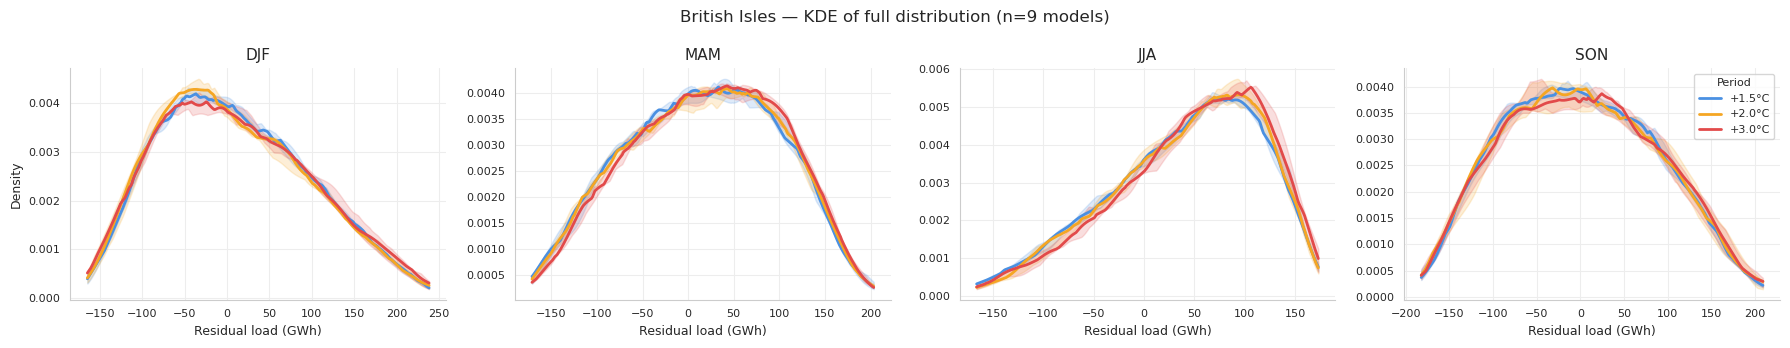

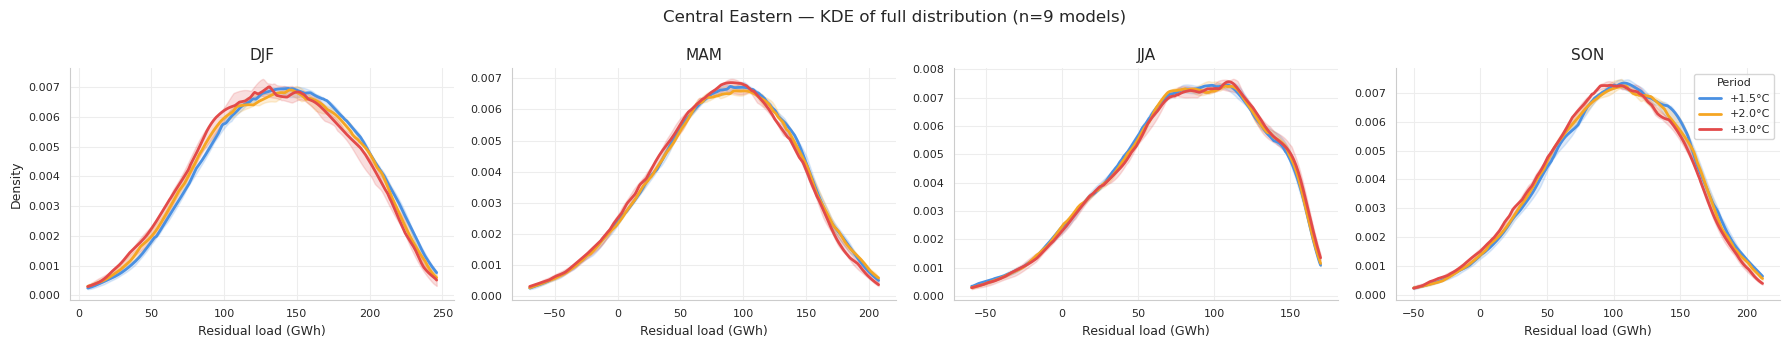

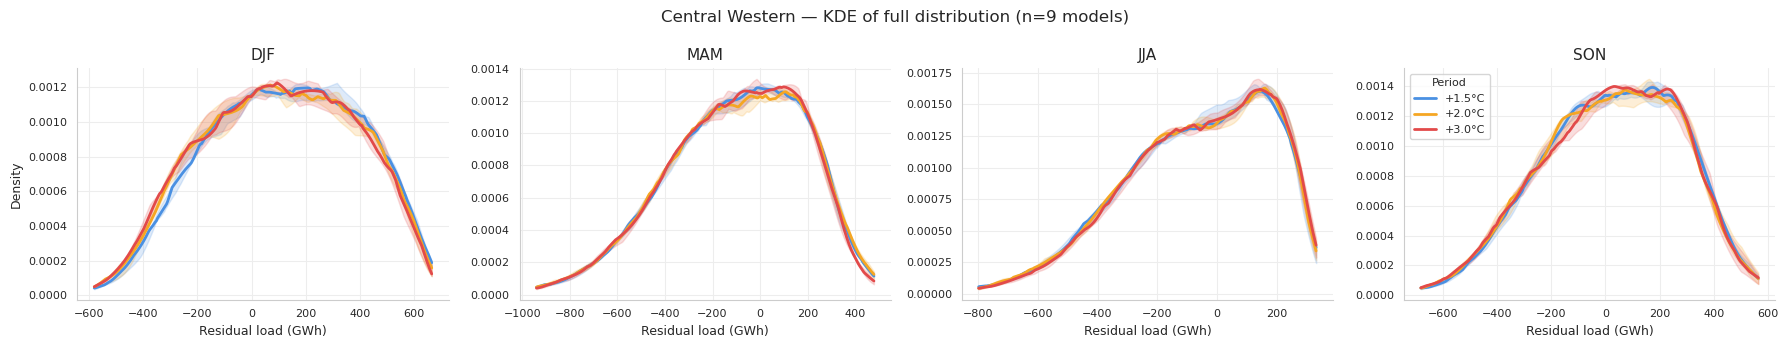

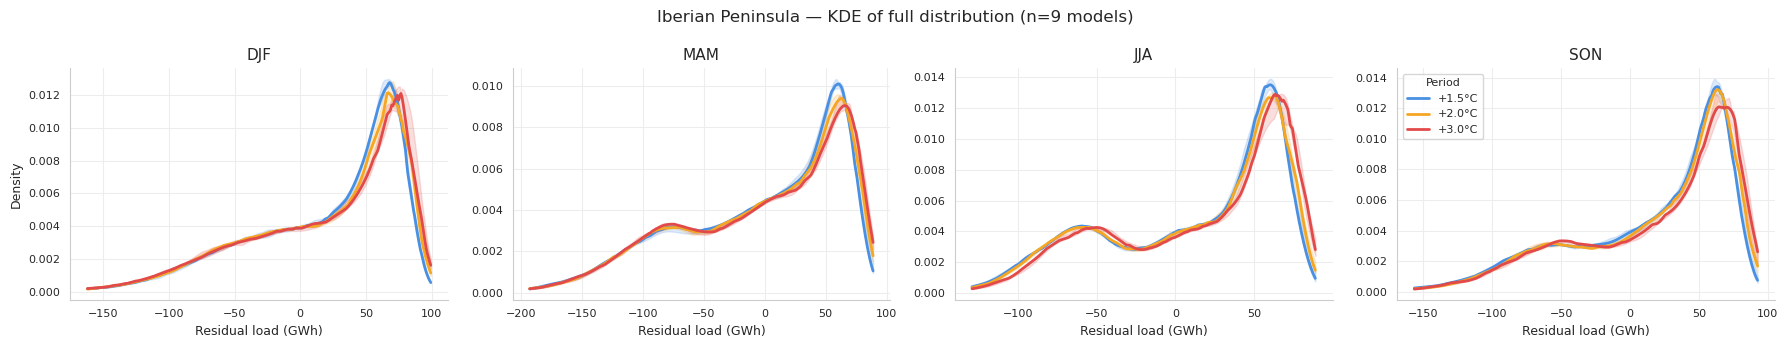

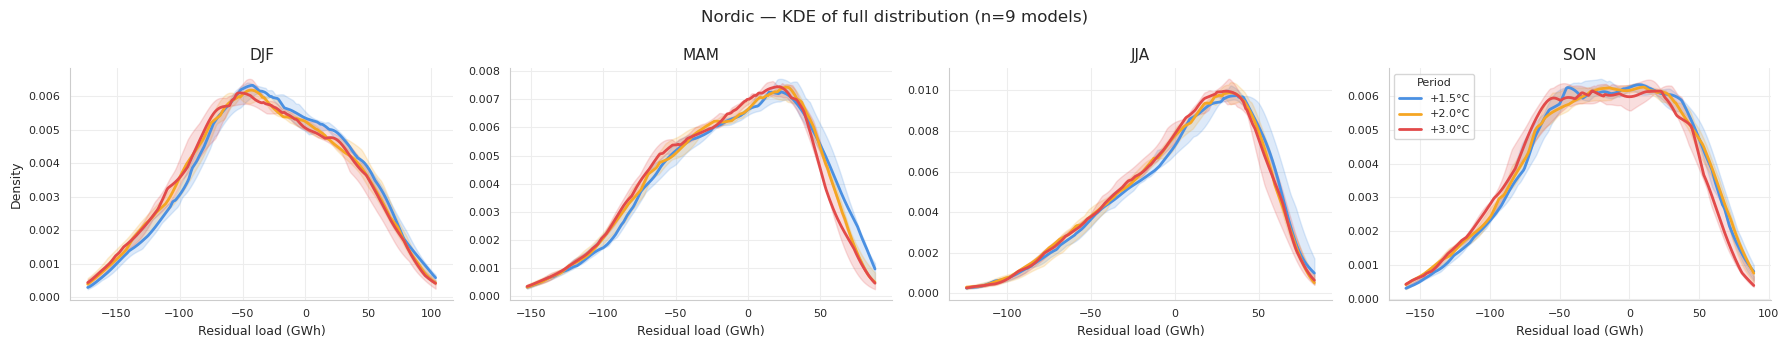

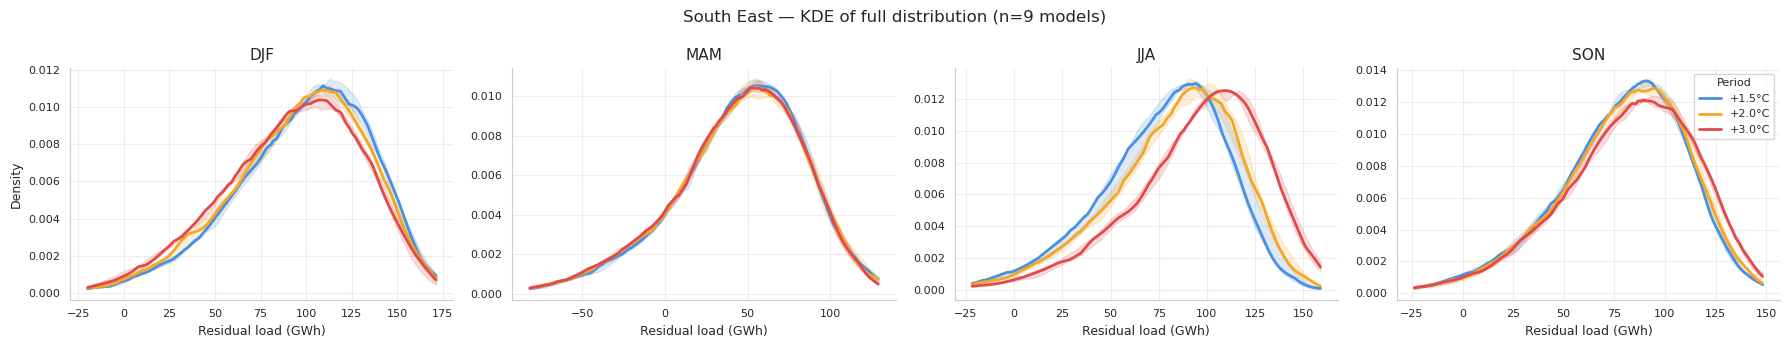

In [13]:
plot_residual_load_kde(
    ds_residual_load_zonal, zones=zones, period_defs=period_defs,
    period_colors=period_colors, models=models,
    season_map=season_map, season_order=season_order, threshold=None, spread=SPREAD,
)

## Figure 2 · Zone × season % change in event count (B1b)

For each duration class, the ensemble-median % change in seasonal event count
relative to the +1.5 °C baseline. **×** marks cells where fewer than 6/9 models
agree on the sign of change (signal not robust).

**Key result —** Iberian summer/spring counts rise steeply with robust model agreement and Central-Eastern winter counts fall; most multi_day changes outside the wind zones are non-robust (heavily stippled).

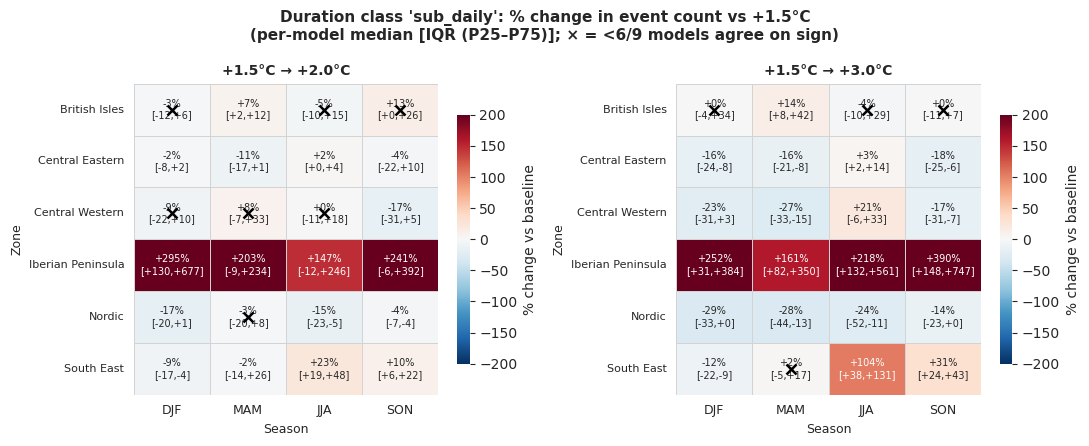

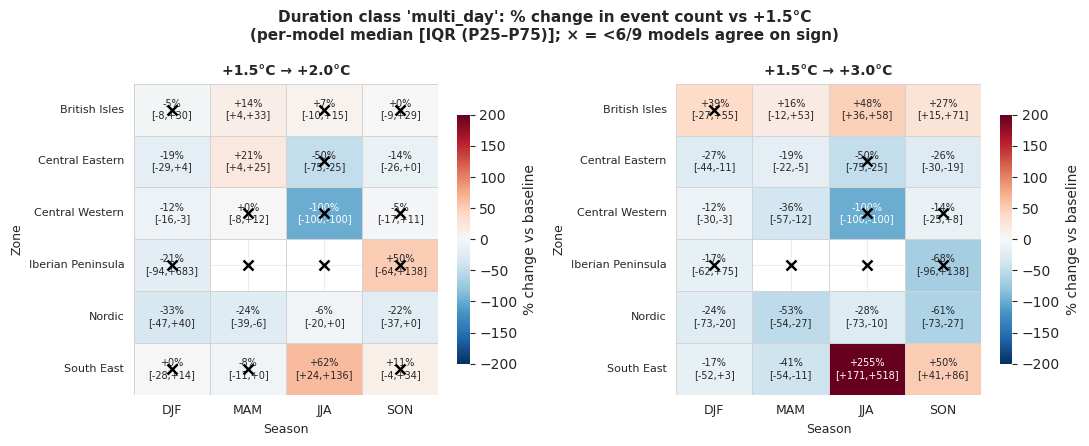

In [14]:
_period_names    = list(period_defs.keys())
_ref_period      = _period_names[0]
_compare_periods = [p for p in _period_names if p != _ref_period]
_n_comp          = len(_compare_periods)
_zone_labels     = [str(z) for z in zones]
_qlo, _qhi = spread_qpair(SPREAD)

def _per_model_pct(df_dc, ref, comp, z, s):
    """Per-model % change in n_events for one (zone, season), over common models."""
    r = (df_dc[(df_dc["zone"] == z) & (df_dc["season"] == s) & (df_dc["period"] == ref)]
         .set_index("model")["n_events"])
    c = (df_dc[(df_dc["zone"] == z) & (df_dc["season"] == s) & (df_dc["period"] == comp)]
         .set_index("model")["n_events"])
    common = r.index.intersection(c.index)
    vals = [(c.loc[m] - r.loc[m]) / r.loc[m] * 100 for m in common if r.loc[m] > 0]
    return np.array(vals, dtype=float)

for dc in DURATION_CLASS_ORDER:
    df_dc = df_seasonal_dc[df_seasonal_dc["duration_class"] == dc]

    med_maps, annot_maps, agree_maps = {}, {}, {}
    for comp in _compare_periods:
        med   = pd.DataFrame(np.nan, index=_zone_labels, columns=season_order)
        annot = pd.DataFrame("",     index=_zone_labels, columns=season_order, dtype=object)
        agree = pd.DataFrame(np.nan, index=_zone_labels, columns=season_order)
        for z in _zone_labels:
            for s in season_order:
                arr = _per_model_pct(df_dc, _ref_period, comp, z, s)
                if arr.size == 0:
                    annot.loc[z, s] = "—"
                    continue
                m  = float(np.median(arr))
                lo = float(np.percentile(arr, _qlo)); hi = float(np.percentile(arr, _qhi))
                med.loc[z, s]   = m
                annot.loc[z, s] = f"{m:+.0f}%\n[{lo:+.0f},{hi:+.0f}]"
                agree.loc[z, s] = float(max(int((arr > 0).sum()), int((arr < 0).sum())))
        med_maps[comp], annot_maps[comp], agree_maps[comp] = med, annot, agree

    _allf = np.concatenate([m.values[np.isfinite(m.values)] for m in med_maps.values()])
    vlim  = min(max(float(np.max(np.abs(_allf))), 10), 200) if _allf.size else 50

    fig, axes = plt.subplots(1, _n_comp, figsize=(5.5 * _n_comp, 4.5))
    if _n_comp == 1:
        axes = [axes]
    fig.suptitle(
        f"Duration class '{dc}': % change in event count vs {_ref_period}\n"
        f"(per-model median [{SPREAD_LABEL[SPREAD]}]; "
        f"× = <{ROBUSTNESS_THRESHOLD}/{len(models)} models agree on sign)",
        fontsize=11, fontweight="bold",
    )
    for ax, comp in zip(axes, _compare_periods):
        med, annot, agree = med_maps[comp], annot_maps[comp], agree_maps[comp]
        sns.heatmap(med.astype(float), ax=ax, annot=annot, fmt="", cmap="RdBu_r", center=0,
                    vmin=-vlim, vmax=vlim, cbar_kws={"label": "% change vs baseline", "shrink": 0.8},
                    linewidths=0.5, linecolor="lightgray", annot_kws={"size": 7})
        for i, z in enumerate(_zone_labels):
            for j, s in enumerate(season_order):
                na = agree.loc[z, s]
                if not np.isfinite(na) or na < ROBUSTNESS_THRESHOLD:
                    ax.plot(j + 0.5, i + 0.5, "x", color="black", markersize=7, markeredgewidth=1.8, zorder=5)
        ax.set_title(f"{_ref_period} → {comp}", fontsize=10, fontweight="bold")
        ax.set_xlabel("Season", fontsize=9); ax.set_ylabel("Zone", fontsize=9)
        ax.set_yticklabels([z.replace("_", " ") for z in _zone_labels], rotation=0, fontsize=8)
        ax.set_xticklabels(season_order, rotation=0, fontsize=9)
    plt.tight_layout(); plt.show()


## Figure 3 · Duration-class breakdown of annual events

Per-model distribution (boxplots) of event frequency by duration class and warming
level, one box per warming level (box = IQR, whiskers = inter-model spread). Multi-day (synoptic) events concentrate in the wind/winter zones
(British Isles, Central-Western, Nordic) and are near-absent in the Mediterranean.

**Key result —** multi_day events occur almost only in British Isles, Central-Western and Nordic, and British Isles multi_day events grow with warming (~38→56); the Mediterranean is overwhelmingly sub_daily.

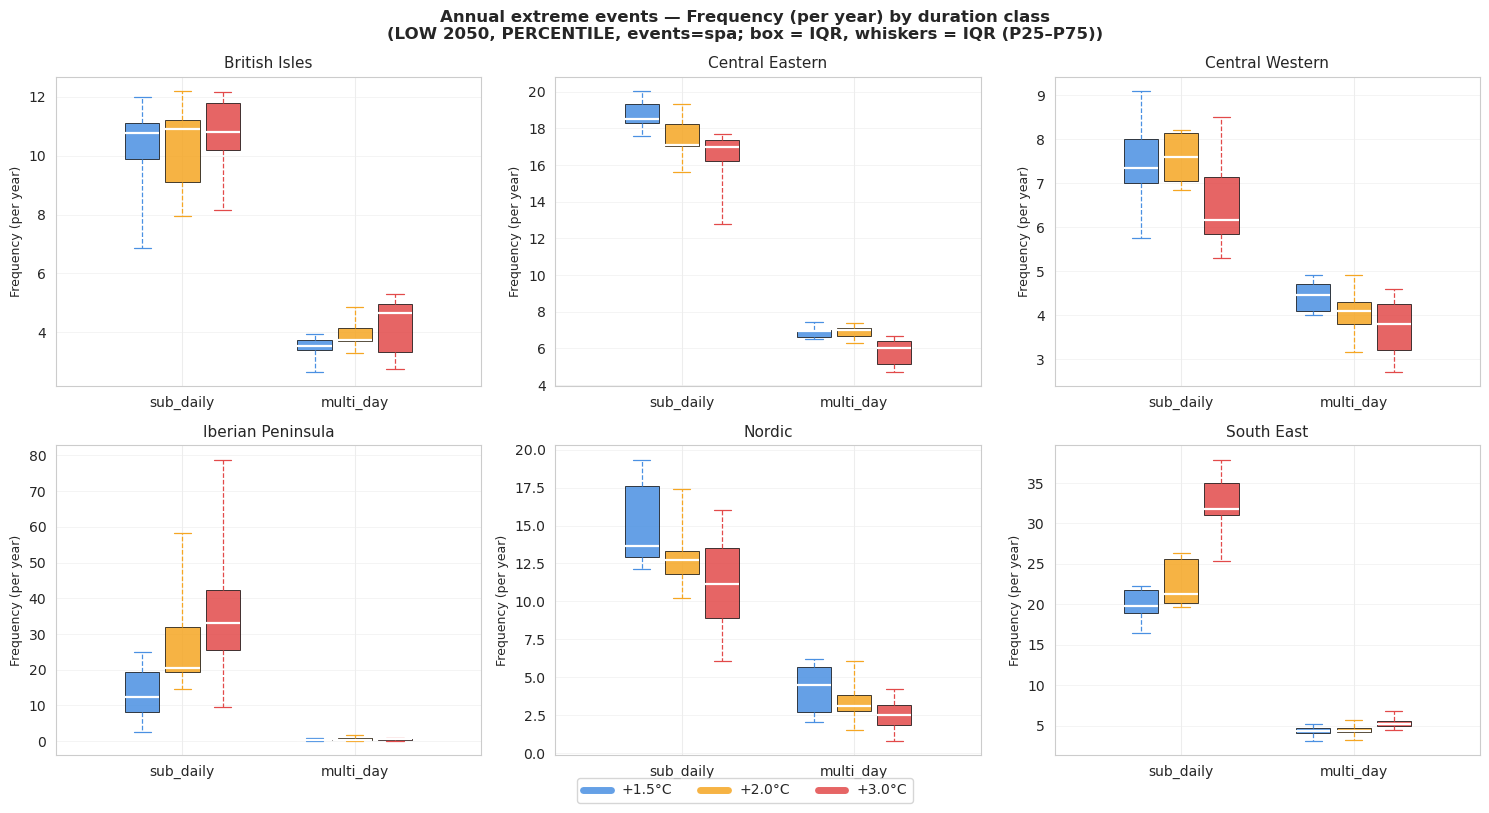

In [15]:
# var_name = "n_events"
# var_label = "Event count (whole period)"
var_name = "freq_per_year"
var_label = "Frequency (per year)"

# Grouped boxplots: x = duration class, one box per warming level, coloured by
# period; box = IQR, whiskers = SPREAD (mirrors the other boxplots in this nb).
_whis         = list(spread_qpair("minmax"))
_period_names = list(period_defs.keys())
_n_periods    = len(_period_names)
_dc_x         = np.arange(len(DURATION_CLASS_ORDER))
_box_w        = 0.7 / _n_periods

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
fig.suptitle(
    f"Annual extreme events — {var_label} by duration class\n"
    f"({supply_scenario} {supply_year}, {THRESHOLD_METHOD}, events={EVENT_DETECTION_METHOD}; "
    f"box = IQR, whiskers = {SPREAD_LABEL[SPREAD]})",
    fontsize=12, fontweight="bold",
)
for ax, zone in zip(axes.flat, zones):
    df_z = df_annual[df_annual["zone"] == str(zone)]
    for pi, period_name in enumerate(_period_names):
        color   = period_colors[period_name]
        offsets = _dc_x + (pi - _n_periods / 2 + 0.5) * _box_w
        data, pos = [], []
        for di, dc in enumerate(DURATION_CLASS_ORDER):
            vals = (df_z[(df_z["period"] == period_name) & (df_z["duration_class"] == dc)]
                    [var_name].dropna().values)
            if vals.size:
                data.append(vals); pos.append(offsets[di])
        if data:
            ax.boxplot(
                data, positions=pos, widths=_box_w * 0.85,
                patch_artist=True, whis=_whis, showfliers=False,
                medianprops=dict(color="white", linewidth=1.6),
                boxprops=dict(facecolor=color, alpha=0.85, linewidth=0.6),
                whiskerprops=dict(color=color, linewidth=0.9, linestyle="--"),
                capprops=dict(color=color, linewidth=0.9),
            )
        ax.plot([], [], color=color, linewidth=5, alpha=0.85, label=period_name)

    ax.set_title(str(zone).replace("_", " "), fontsize=11)
    ax.set_xticks(_dc_x)
    ax.set_xticklabels(DURATION_CLASS_ORDER)
    ax.set_ylabel(var_label, fontsize=9)
    ax.grid(axis="y", linewidth=0.4)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=_n_periods, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(); plt.show()


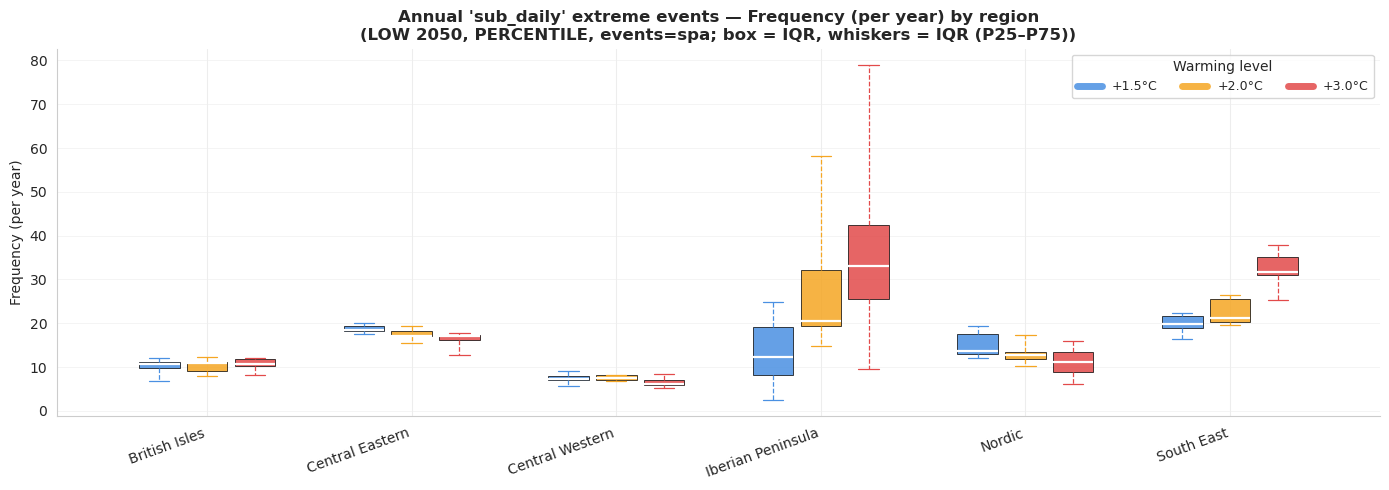

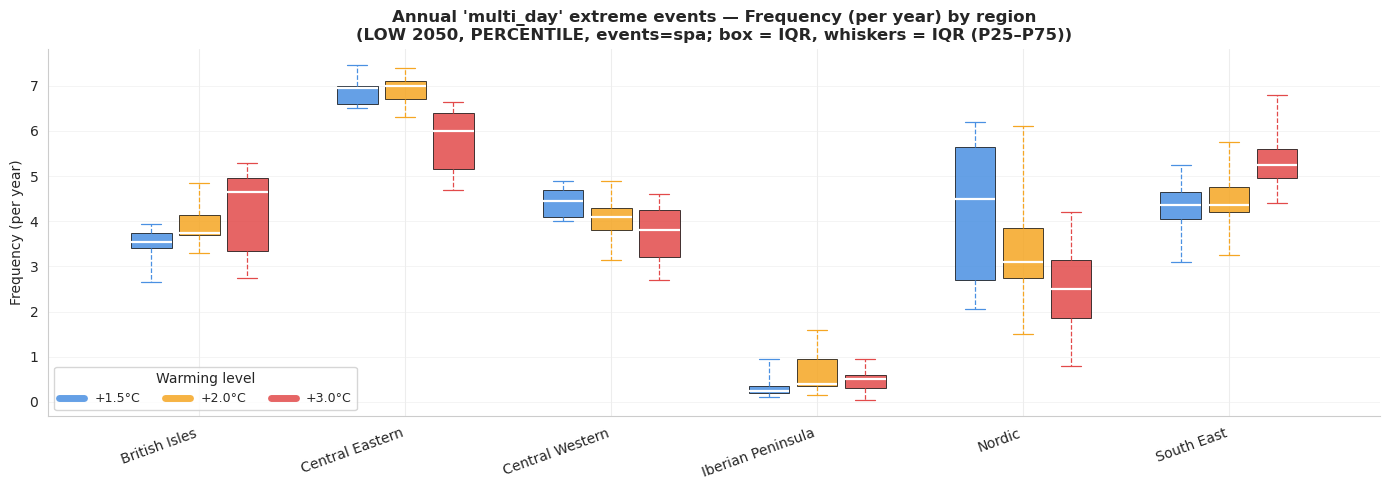

In [16]:
# Alternative layout — one figure per duration class, x-axis = region.
# Within each region, one box per warming level (box = IQR, whiskers = SPREAD).
var_name  = "freq_per_year"
var_label = "Frequency (per year)"

_whis         = list(spread_qpair("minmax"))
_period_names = list(period_defs.keys())
_n_periods    = len(_period_names)
_zone_labels  = [str(z) for z in zones]
_zx           = np.arange(len(_zone_labels))
_box_w        = 0.7 / _n_periods

for dc in DURATION_CLASS_ORDER:
    df_dc = df_annual[df_annual["duration_class"] == dc]
    fig, ax = plt.subplots(figsize=(14, 5))
    for pi, period_name in enumerate(_period_names):
        color   = period_colors[period_name]
        offsets = _zx + (pi - _n_periods / 2 + 0.5) * _box_w
        data, pos = [], []
        for zi, z in enumerate(_zone_labels):
            vals = (df_dc[(df_dc["period"] == period_name) & (df_dc["zone"] == z)]
                    [var_name].dropna().values)
            if vals.size:
                data.append(vals); pos.append(offsets[zi])
        if data:
            ax.boxplot(
                data, positions=pos, widths=_box_w * 0.85,
                patch_artist=True, whis=_whis, showfliers=False,
                medianprops=dict(color="white", linewidth=1.6),
                boxprops=dict(facecolor=color, alpha=0.85, linewidth=0.6),
                whiskerprops=dict(color=color, linewidth=0.9, linestyle="--"),
                capprops=dict(color=color, linewidth=0.9),
            )
        ax.plot([], [], color=color, linewidth=5, alpha=0.85, label=period_name)

    ax.set_title(
        f"Annual '{dc}' extreme events — {var_label} by region\n"
        f"({supply_scenario} {supply_year}, {THRESHOLD_METHOD}, events={EVENT_DETECTION_METHOD}; "
        f"box = IQR, whiskers = {SPREAD_LABEL[SPREAD]})",
        fontsize=12, fontweight="bold",
    )
    ax.set_xticks(_zx)
    ax.set_xticklabels([z.replace("_", " ") for z in _zone_labels], rotation=20, ha="right")
    ax.set_ylabel(var_label, fontsize=10)
    ax.grid(axis="y", linewidth=0.4)
    ax.legend(title="Warming level", ncol=_n_periods, fontsize=9)
    sns.despine(ax=ax)
    plt.tight_layout(); plt.show()


### Why the sub-daily / multi-day split shifts

The boxplots above show a robust asymmetry across warming levels: **sub-daily
(≤ 24 h) events become more frequent, while multi-day (> 24 h) events stay flat or
decline**. Because the fixed-percentile threshold samples the *same* part of the
distribution (95th–100th percentile of positive residual load) in every zone, this
is a genuine change in the temporal **structure** of deficit stress, not a threshold
artefact.

The diagnostic below tests a simple explanation — a **reallocation of the deficit
budget from the synoptic (multi-day) to the diurnal (sub-daily) timescale** — with
three views: **(a)** how annual deficit-hours split between the two timescales at each
GWL; **(b)** which zones drive the change; and **(c)** the diurnal shape of residual
load on stressed days (RL ÷ zone threshold), which sets *why* new deficits are short.

In [17]:
# ── Timescale reallocation: split the deficit budget between sub-daily & multi-day ──
# For each (model, GWL, zone): annual event counts and deficit-hours per timescale,
# plus the diurnal shape of residual load on stressed days (RL normalised by the
# zone threshold). Independent of the boxplots above; uses the CERRA thresholds.
from cordex2energy_analysis.extremes_events import detect_events

_degen_str = [str(z) for z in DEGENERATE_ZONES]
_frag_rows, _diurnal = [], {p: [] for p in period_defs}
for _m in models:
    _ds  = _cache_rl[_m]
    _res = {k: v for k, v in resolve_model_periods(period_defs, _m).items() if v is not None}
    for _p, (_t0, _t1) in _res.items():
        _dsp  = _ds.sel(time=slice(_t0, _t1))
        _nyr  = len(np.unique(_dsp["time"].dt.year.values))
        _hour = _dsp["time"].dt.hour.values
        _day  = _dsp["time"].dt.floor("D").values
        for _z in zones:
            _thr = float(active_thresholds[_m].sel(zone=_z).values)
            _rl  = _dsp["residual_load"].sel(zone=_z).values
            _exc = _rl > _thr
            _evs = detect_events(_rl, _thr, method=EVENT_DETECTION_METHOD)
            _d   = np.array([e["duration_h"] for e in _evs]) if _evs else np.array([])
            _subm, _mulm = (_d > 0) & (_d <= 24), _d > 24
            # Diurnal RL/threshold on stressed days (calendar days with >=1 exceedance)
            _dfz = pd.DataFrame({"day": _day, "hour": _hour, "rl": _rl, "exc": _exc})
            _sd  = _dfz[_dfz.groupby("day")["exc"].transform("any")]
            if len(_sd) and str(_z) not in _degen_str:
                _diurnal[_p].append(_sd.groupby("hour")["rl"].mean() / _thr)
            _frag_rows.append(dict(
                model=_m, period=_p, zone=str(_z),
                sub_events_yr=int(_subm.sum()) / _nyr, multi_events_yr=int(_mulm.sum()) / _nyr,
                sub_hours_yr=float(_d[_subm].sum()) / _nyr, multi_hours_yr=float(_d[_mulm].sum()) / _nyr,
            ))

df_frag = pd.DataFrame(_frag_rows)
df_frag = df_frag[~df_frag.zone.isin(_degen_str)]
_frag_periods = list(period_defs.keys())

# Ensemble median per (period, zone), then averaged across analysis zones.
frag_agg = (df_frag.groupby(["period", "zone"]).median(numeric_only=True)
                    .groupby("period").mean(numeric_only=True).reindex(_frag_periods))
_c, _w = _frag_periods[0], _frag_periods[-1]
print("Deficit budget by timescale (ensemble median, mean over analysis zones):")
print(frag_agg[["sub_events_yr", "multi_events_yr", "sub_hours_yr", "multi_hours_yr"]].round(1))
print(f"\n{_c} \u2192 {_w}:")
print(f"  sub-daily : {frag_agg.loc[_c,'sub_events_yr']:.0f}\u2192{frag_agg.loc[_w,'sub_events_yr']:.0f} events/yr, "
      f"{frag_agg.loc[_c,'sub_hours_yr']:.0f}\u2192{frag_agg.loc[_w,'sub_hours_yr']:.0f} h/yr")
print(f"  multi-day : {frag_agg.loc[_c,'multi_events_yr']:.1f}\u2192{frag_agg.loc[_w,'multi_events_yr']:.1f} events/yr, "
      f"{frag_agg.loc[_c,'multi_hours_yr']:.0f}\u2192{frag_agg.loc[_w,'multi_hours_yr']:.0f} h/yr")

Deficit budget by timescale (ensemble median, mean over analysis zones):
        sub_events_yr  multi_events_yr  sub_hours_yr  multi_hours_yr
period                                                              
+1.5°C           13.7              4.0         145.0           312.5
+2.0°C           15.0              3.8         162.9           282.6
+3.0°C           18.3              3.8         200.2           294.2

+1.5°C → +3.0°C:
  sub-daily : 14→18 events/yr, 145→200 h/yr
  multi-day : 4.0→3.8 events/yr, 312→294 h/yr


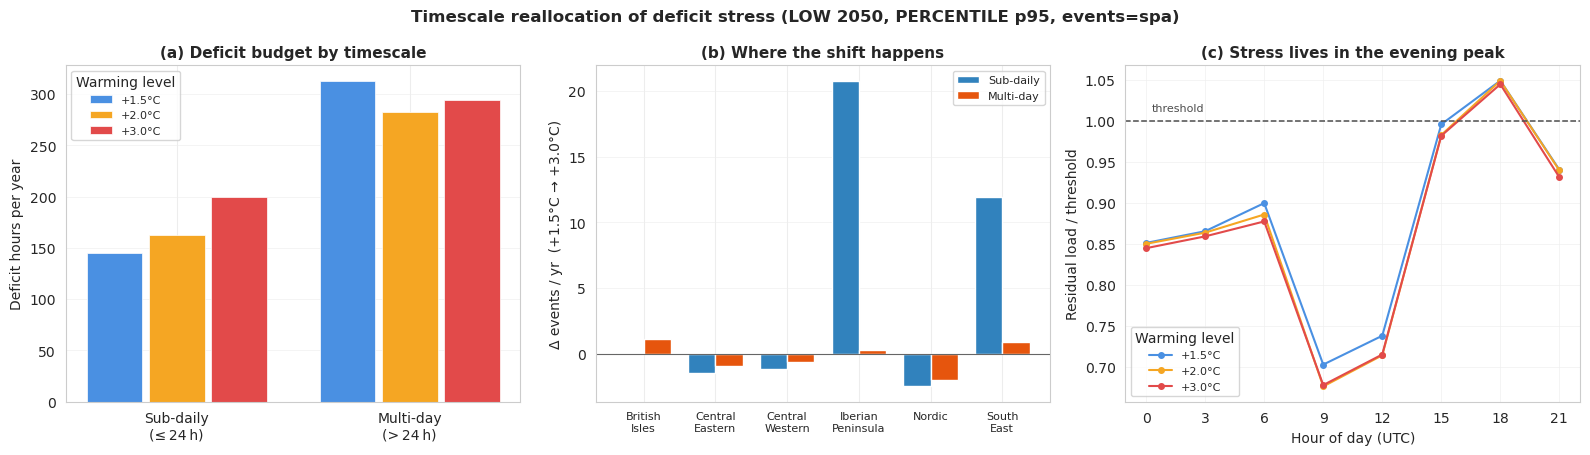

In [18]:
# Timescale-reallocation figure: (a) deficit budget by timescale x GWL,
# (b) per-zone change in event frequency, (c) diurnal RL/threshold on stressed days.
_zmed     = df_frag.groupby(["period", "zone"]).median(numeric_only=True)
_hours_ax = [0, 3, 6, 9, 12, 15, 18, 21]
_thr_tag  = (f"{THRESHOLD_METHOD} p{THRESHOLD_PERCENTILE:.0f}"
             if THRESHOLD_METHOD == "PERCENTILE" else THRESHOLD_METHOD)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) deficit-hours by timescale, grouped by warming level
ax = axes[0]
_ts, _tslab = ["sub_hours_yr", "multi_hours_yr"], ["Sub-daily\n(≤ 24 h)", "Multi-day\n(> 24 h)"]
_x, _bw = np.arange(len(_ts)), 0.8 / len(_frag_periods)
for _i, _p in enumerate(_frag_periods):
    _off = _x + (_i - len(_frag_periods) / 2 + 0.5) * _bw
    ax.bar(_off, [frag_agg.loc[_p, c] for c in _ts], width=_bw * 0.9,
           color=period_colors[_p], label=_p, edgecolor="white", linewidth=0.5)
ax.set_xticks(_x); ax.set_xticklabels(_tslab)
ax.set_ylabel("Deficit hours per year")
ax.set_title("(a) Deficit budget by timescale", fontsize=11, fontweight="bold")
ax.legend(title="Warming level", fontsize=8); ax.grid(axis="y", lw=0.4)

# (b) per-zone change in event frequency, coldest -> warmest GWL
ax = axes[1]
_zl, _dsub, _dmul = sorted(df_frag.zone.unique()), [], []
for _z in _zl:
    _s = _zmed.xs(_z, level="zone").reindex(_frag_periods)
    _dsub.append(_s["sub_events_yr"].iloc[-1] - _s["sub_events_yr"].iloc[0])
    _dmul.append(_s["multi_events_yr"].iloc[-1] - _s["multi_events_yr"].iloc[0])
_xz, _w2 = np.arange(len(_zl)), 0.38
ax.bar(_xz - _w2 / 2, _dsub, _w2, color="#3182bd", label="Sub-daily")
ax.bar(_xz + _w2 / 2, _dmul, _w2, color="#e6550d", label="Multi-day")
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xticks(_xz); ax.set_xticklabels([z.replace("_", "\n") for z in _zl], fontsize=8)
ax.set_ylabel(f"Δ events / yr  ({_frag_periods[0]} → {_frag_periods[-1]})")
ax.set_title("(b) Where the shift happens", fontsize=11, fontweight="bold")
ax.legend(fontsize=8); ax.grid(axis="y", lw=0.4)

# (c) diurnal RL/threshold on stressed days (mean over models & analysis zones)
ax = axes[2]
for _p in _frag_periods:
    if not _diurnal[_p]:
        continue
    _cyc = pd.concat(_diurnal[_p], axis=1).reindex(_hours_ax).mean(axis=1)
    ax.plot(_cyc.index, _cyc.values, "-o", ms=4, color=period_colors[_p], label=_p)
ax.axhline(1.0, color="0.3", ls="--", lw=1.1)
ax.text(0.3, 1.01, "threshold", color="0.3", fontsize=8, va="bottom")
ax.set_xticks(_hours_ax); ax.set_xlabel("Hour of day (UTC)")
ax.set_ylabel("Residual load / threshold")
ax.set_title("(c) Stress lives in the evening peak", fontsize=11, fontweight="bold")
ax.legend(title="Warming level", fontsize=8); ax.grid(lw=0.4)

fig.suptitle(f"Timescale reallocation of deficit stress "
             f"({supply_scenario} {supply_year}, {_thr_tag}, events={EVENT_DETECTION_METHOD})",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

**What the data shows.**

- **(a) The deficit budget moves to shorter timescales.** From the coldest to the
  warmest level, sub-daily deficit-hours grow strongly (≈ +50 %) while multi-day
  deficit-hours shrink (≈ −15 %). Mean event duration is essentially unchanged, so
  this is *not* long events being chopped up — it is a net transfer of deficit hours
  from the multi-day to the sub-daily band, together with the genesis of many new
  short events.

- **(b) Two regimes sum to the ensemble signal.** The sub-daily rise is dominated by
  the solar-rich southern zones (Iberian Peninsula, South-East), where sub-daily
  events roughly double. The multi-day decline is concentrated in the northern /
  continental zones (Nordic, Central-Eastern), where warmer winters weaken the
  persistent low-renewable (Dunkelflaute-type) spells. The aggregate "sub-daily up,
  multi-day flat/down" is the sum of these two distinct mechanisms.

- **(c) The diurnal shape explains why new stress is sub-daily.** On stressed days the
  residual load is strongly solar-shaped: it troughs around midday (well below the
  threshold — solar covers the load) and peaks in the evening (15–21 h), the only
  window that crosses the threshold. This shape is fixed across warming levels, so as
  demand-driven stress grows (rising cooling load, no PV at the evening peak) it can
  only surface as **more short evening-peak deficits** — i.e. sub-daily events —
  while the weather-persistence-driven multi-day deficits ease as the climate warms.

### What drives the increase — demand or a renewable deficit?

The panels above show *when* deficits grow (the evening peak) and *where* (the southern
zones), but not *why*. Residual load decomposes **exactly** as

$$\mathrm{RL} = \mathrm{demand} - \mathrm{PV} - \mathrm{wind_{on}} - \mathrm{wind_{off}} - \mathrm{hydro_{RoR}} - \mathrm{reservoir} - \mathrm{battery},$$

so we can attribute the change in the mean **evening-peak (15–21 UTC)** residual load between
the coldest and warmest warming levels to each component. A **positive** contribution *raises*
RL — i.e. deepens the deficit — and comes either from **rising demand** or from **falling
generation / storage**. Splitting the demand term by season then exposes the warming fingerprint.

In [19]:
# ── Attribution: demand vs renewables behind the evening-peak RL change ───────
# Mean of each component at evening-peak hours (15–21 UTC), per (model, GWL, zone,
# season). Contributions to Δ(evening RL) between the coldest and warmest GWL:
# demand enters with +sign, generation/storage with −sign (a drop raises RL).
_comp_map = {"total_demand": "Demand", "gen_pv": "PV", "gen_wind_on": "Wind Onshore",
             "gen_wind_off": "Wind Offshore", "gen_hydro_ror": "Hydro RoR",
             "reservoir_dispatch_gwh": "Reservoir Hydro", "battery_dispatch_gwh": "Battery"}
_EVE_HOURS = [15, 18, 21]
_attr_rows = []
for _m in models:
    _rlm, _com = _cache_rl[_m], _cache_comp[_m]
    _res = {k: v for k, v in resolve_model_periods(period_defs, _m).items() if v is not None}
    for _p, (_t0, _t1) in _res.items():
        _rlp = _rlm.sel(time=slice(_t0, _t1))
        _cop = _com.sel(time=slice(_t0, _t1))
        _hh  = _rlp["time"].dt.hour.values
        _ss  = np.array([season_map[int(x)] for x in _rlp["time"].dt.month.values])
        _eve = np.isin(_hh, _EVE_HOURS)
        for _z in zones:
            _rl = _rlp["residual_load"].sel(zone=_z).values
            _cv = {v: _cop[v].sel(zone=_z).values for v in _comp_map}
            for _sm, _sl in [(np.ones_like(_eve, bool), "ALL"), (_ss == "DJF", "DJF"), (_ss == "JJA", "JJA")]:
                _mm = _eve & _sm
                if _mm.sum() == 0:
                    continue
                _r = dict(model=_m, period=_p, zone=str(_z), season=_sl, RL=float(_rl[_mm].mean()))
                for _v, _a in _cv.items():
                    _r[_comp_map[_v]] = float(_a[_mm].mean())
                _attr_rows.append(_r)

df_attr = pd.DataFrame(_attr_rows)
_attr_periods = list(period_defs.keys())
_attr_gm = df_attr.groupby(["period", "zone", "season"]).median(numeric_only=True)
_DRIVERS = ["Demand", "PV", "Wind Onshore", "Wind Offshore", "Hydro RoR", "Reservoir Hydro", "Battery"]

def evening_rl_attribution(zone, season="ALL"):
    """Component contributions (GWh/3 h) to Δ mean evening-peak RL, coldest→warmest GWL."""
    _d = _attr_gm.xs((_attr_periods[-1], zone, season)) - _attr_gm.xs((_attr_periods[0], zone, season))
    _out = {"Demand": float(_d["Demand"])}
    for _k in _DRIVERS[1:]:
        _out[_k] = -float(_d[_k])          # a drop in generation/storage raises RL
    _out["net"] = float(_d["RL"])
    return _out

print(f"Δ evening-peak RL by driver (GWh/3 h, ensemble median), {_attr_periods[0]} → {_attr_periods[-1]}:")
for _z in [str(zz) for zz in zones]:
    _c = evening_rl_attribution(_z)
    print(f"  {_z:17s} net {_c['net']:+6.1f} | demand {_c['Demand']:+6.1f}  "
          f"wind_off {_c['Wind Offshore']:+5.1f}  wind_on {_c['Wind Onshore']:+5.1f}  "
          f"reservoir {_c['Reservoir Hydro']:+5.1f}")

Δ evening-peak RL by driver (GWh/3 h, ensemble median), +1.5°C → +3.0°C:
  British_Isles     net   +4.9 | demand   -2.4  wind_off  +6.8  wind_on  +0.8  reservoir  -0.0
  Central_Eastern   net   -2.8 | demand   -2.1  wind_off  -0.3  wind_on  -0.1  reservoir  -0.2
  Central_Western   net   -5.0 | demand  -11.3  wind_off  +6.1  wind_on  +1.7  reservoir  -0.4
  Iberian_Peninsula net   +5.1 | demand   +1.1  wind_off  +0.1  wind_on  +1.7  reservoir  +2.4
  Nordic            net   -6.5 | demand   -2.9  wind_off  +0.6  wind_on  +0.5  reservoir  -3.9
  South_East        net   +4.6 | demand   +5.0  wind_off  +0.2  wind_on  -0.0  reservoir  +0.1


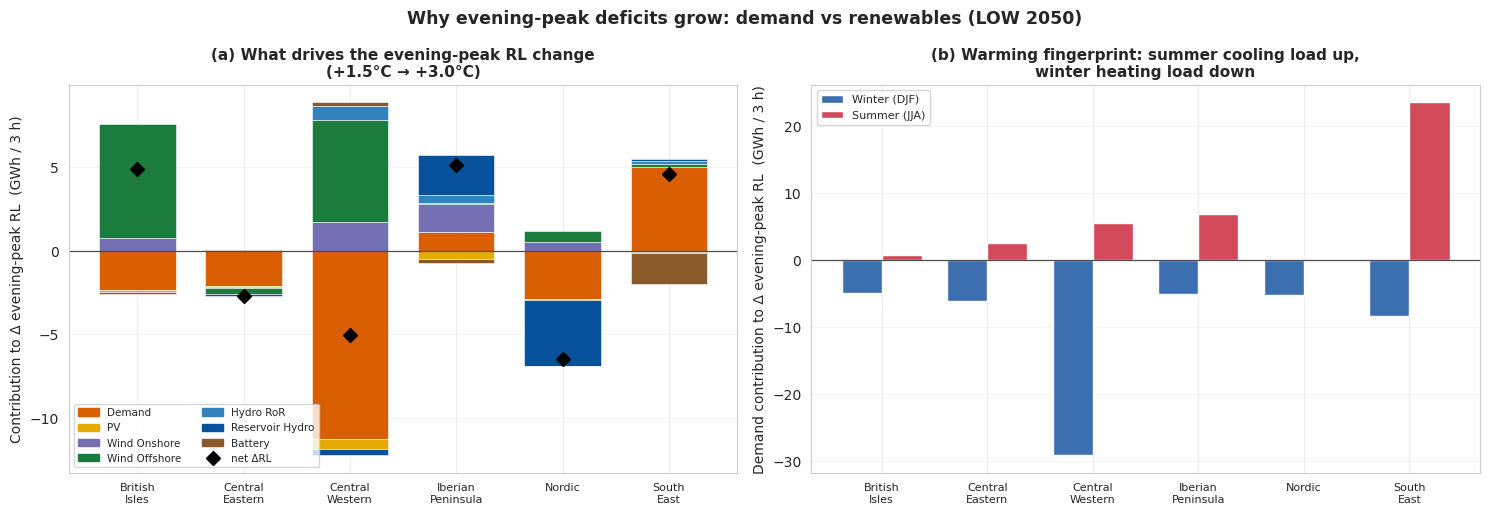

In [20]:
# Attribution figure: (a) driver decomposition of Δ(evening-peak RL) per zone,
# (b) the demand term split by season (summer cooling vs winter heating).
_zl = [str(z) for z in zones]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# (a) driver attribution — diverging stacked bars, net ΔRL as a marker
ax = axes[0]; _x = np.arange(len(_zl))
for _zi, _z in enumerate(_zl):
    _c = evening_rl_attribution(_z); _pb = _nb = 0.0
    for _dr in _DRIVERS:
        _v = _c[_dr]
        if abs(_v) < 1e-9:
            continue
        _bot = _pb if _v >= 0 else _nb
        ax.bar(_zi, _v, bottom=_bot, width=0.72, color=driver_palette[_dr],
               edgecolor="white", linewidth=0.4, zorder=2)
        if _v >= 0:
            _pb += _v
        else:
            _nb += _v
    ax.plot(_zi, _c["net"], "D", color="k", ms=7, zorder=4)
ax.axhline(0, color="0.3", lw=0.9)
ax.set_xticks(_x); ax.set_xticklabels([z.replace("_", "\n") for z in _zl], fontsize=8)
ax.set_ylabel("Contribution to Δ evening-peak RL  (GWh / 3 h)")
ax.set_title(f"(a) What drives the evening-peak RL change\n({_attr_periods[0]} → {_attr_periods[-1]})",
             fontsize=11, fontweight="bold")
_hd = [plt.Rectangle((0, 0), 1, 1, color=driver_palette[d]) for d in _DRIVERS]
_hd.append(plt.Line2D([0], [0], marker="D", color="k", ls="", ms=7))
ax.legend(_hd, _DRIVERS + ["net ΔRL"], fontsize=7.5, ncol=2, loc="lower left")
ax.grid(axis="y", lw=0.4)

# (b) demand term by season — the warming fingerprint
ax = axes[1]
_djf = [evening_rl_attribution(z, "DJF")["Demand"] for z in _zl]
_jja = [evening_rl_attribution(z, "JJA")["Demand"] for z in _zl]
_bw = 0.38
ax.bar(_x - _bw / 2, _djf, _bw, color="#3b6fb0", label="Winter (DJF)")
ax.bar(_x + _bw / 2, _jja, _bw, color="#d1495b", label="Summer (JJA)")
ax.axhline(0, color="0.3", lw=0.9)
ax.set_xticks(_x); ax.set_xticklabels([z.replace("_", "\n") for z in _zl], fontsize=8)
ax.set_ylabel("Demand contribution to Δ evening-peak RL  (GWh / 3 h)")
ax.set_title("(b) Warming fingerprint: summer cooling load up,\nwinter heating load down",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=8); ax.grid(axis="y", lw=0.4)

fig.suptitle(f"Why evening-peak deficits grow: demand vs renewables "
             f"({supply_scenario} {supply_year})", fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.show()

**The answer.**

- **Is evening demand increasing? Yes — but it's a *summer* signal, and only where it bites.**
  In the solar-dominated southern zones (South-East, Iberian Peninsula) the evening-peak RL rise
  is dominated by **demand** (panel a, orange), and panel (b) shows it is almost entirely a
  **summer (JJA)** effect (≈ +24 GWh/3 h in South-East, +7 in Iberia): cooling / air-conditioning
  load that peaks in the early evening, *after* solar has faded. Crucially, in **winter** evening
  demand *falls* in every zone (−5 to −29 GWh/3 h) as warming cuts heating load.

- **Is it a renewable deficit? Secondary overall, but the dominant driver in the maritime
  north-west.** PV contributes essentially nothing at the evening peak — the sun is already down,
  which is *why* these are evening events. The clear renewable-driven case is the **British Isles**,
  where the rise comes from lower **offshore wind** (+6.8), not demand (which falls). Elsewhere,
  small onshore-wind and reservoir reductions add to the southern demand signal.

- **How global warming produces "sub-daily up, multi-day down."** Two opposing seasonal effects
  (panel b): **summer cooling demand ↑** at the solar-off evening hours spawns *new short
  evening-peak deficits* in the south → the sub-daily surge; while **winter heating demand ↓**
  (milder winters) weakens the persistent, multi-day winter deficits of the north (Nordic,
  Central-Eastern/Western) → the multi-day decline. In net, warming migrates the stress season
  from **winter (long, synoptic, heating-driven)** toward **summer evenings (short, diurnal,
  cooling-driven)**.

### And the multi-day events — why do they ease?

The same decomposition, now for the **multi-day (> 24 h)** events. These are a different beast:
they are governed by synoptic **persistence** — multi-day spells of low renewables and high demand
(Dunkelflaute-type). So besides the demand-vs-renewable attribution we ask an extra question that
did not arise for the diurnal events: does warming shorten the **persistence** of the driving
conditions, or merely lower their **level** so that fewer spells cross the threshold at all?

Three views: **(a)** *when* multi-day events occur (season); **(b)** the driver attribution of the
change in **winter (DJF)** residual load — where these events live; and **(c)** whether the change
is in event **count** (a level effect) or event **duration** (a persistence effect).

In [21]:
# ── Multi-day diagnosis: winter regime, driver attribution, level vs persistence ──
# Multi-day (>24 h) events are a winter, persistence-driven regime. We measure their
# seasonal occurrence, the DJF residual-load driver attribution (RL = demand − Σgen −
# storage), and split the change into event count vs mean duration.
from cordex2energy_analysis.extremes_events import detect_events

_comp_map = {"total_demand": "Demand", "gen_pv": "PV", "gen_wind_on": "Wind Onshore",
             "gen_wind_off": "Wind Offshore", "gen_hydro_ror": "Hydro RoR",
             "reservoir_dispatch_gwh": "Reservoir Hydro", "battery_dispatch_gwh": "Battery"}
_md_rows, _mdseason_rows = [], []
for _m in models:
    _rlm, _com = _cache_rl[_m], _cache_comp[_m]
    _res = {k: v for k, v in resolve_model_periods(period_defs, _m).items() if v is not None}
    for _p, (_t0, _t1) in _res.items():
        _rlp = _rlm.sel(time=slice(_t0, _t1))
        _cop = _com.sel(time=slice(_t0, _t1))
        _nyr = len(np.unique(_rlp["time"].dt.year.values))
        _mon = _rlp["time"].dt.month.values
        _se  = np.array([season_map[int(x)] for x in _mon])
        _djf = _se == "DJF"
        for _z in zones:
            _thr = float(active_thresholds[_m].sel(zone=_z).values)
            _rl  = _rlp["residual_load"].sel(zone=_z).values
            _evs = detect_events(_rl, _thr, method=EVENT_DETECTION_METHOD)
            _dur = [e["duration_h"] for e in _evs if e["duration_h"] > 24]
            _sea = [season_map[int(_mon[e["indices"][0]])] for e in _evs if e["duration_h"] > 24]
            _cv  = {v: _cop[v].sel(zone=_z).values for v in _comp_map}
            _r = dict(model=_m, period=_p, zone=str(_z),
                      md_events_yr=len(_dur) / _nyr,
                      md_meandur=float(np.mean(_dur)) if _dur else np.nan,
                      winter_rl=float(_rl[_djf].mean()))
            for _v, _a in _cv.items():
                _r["DJF_" + _comp_map[_v]] = float(_a[_djf].mean())
            _md_rows.append(_r)
            for _s in season_order:
                _mdseason_rows.append(dict(model=_m, period=_p, zone=str(_z), season=_s,
                    md_hours_yr=float(np.sum([d for d, ss in zip(_dur, _sea) if ss == _s])) / _nyr))

df_md, df_mdseason = pd.DataFrame(_md_rows), pd.DataFrame(_mdseason_rows)
_mdp = list(period_defs.keys())
_md_gm = df_md.groupby(["period", "zone"]).median(numeric_only=True)
_DRIVERS = ["Demand", "PV", "Wind Onshore", "Wind Offshore", "Hydro RoR", "Reservoir Hydro", "Battery"]

def winter_rl_attribution(zone):
    """Component contributions (GWh/3 h) to Δ mean winter (DJF) RL, coldest→warmest GWL."""
    _d = _md_gm.xs((_mdp[-1], zone)) - _md_gm.xs((_mdp[0], zone))
    _o = {"Demand": float(_d["DJF_Demand"])}
    for _k in _DRIVERS[1:]:
        _o[_k] = -float(_d["DJF_" + _k])
    _o["net"] = float(_d["winter_rl"])
    return _o

_md_agg = _md_gm.groupby("period").mean(numeric_only=True).reindex(_mdp)
print("Multi-day events (ensemble median, mean over zones):")
print(_md_agg[["md_events_yr", "md_meandur"]].round(1))
print(f"\nΔ winter RL by driver (GWh/3 h, ensemble median), {_mdp[0]} → {_mdp[-1]}:")
for _z in [str(zz) for zz in zones]:
    _c = winter_rl_attribution(_z)
    print(f"  {_z:17s} net {_c['net']:+6.1f} | demand {_c['Demand']:+6.1f}  "
          f"wind_off {_c['Wind Offshore']:+5.1f}  wind_on {_c['Wind Onshore']:+5.1f}")

Multi-day events (ensemble median, mean over zones):
        md_events_yr  md_meandur
period                          
+1.5°C           4.0        71.7
+2.0°C           3.8        69.4
+3.0°C           3.8        70.7

Δ winter RL by driver (GWh/3 h, ensemble median), +1.5°C → +3.0°C:
  British_Isles     net   -0.5 | demand   -5.0  wind_off  +3.9  wind_on  +1.2
  Central_Eastern   net   -6.7 | demand   -6.3  wind_off  -0.5  wind_on  +0.3
  Central_Western   net  -17.8 | demand  -29.9  wind_off  +0.5  wind_on  +5.8
  Iberian_Peninsula net   +0.8 | demand   -5.2  wind_off  +0.6  wind_on  +3.8
  Nordic            net   -5.1 | demand   -5.4  wind_off  -0.6  wind_on  +1.2
  South_East        net   -6.9 | demand   -8.5  wind_off  +0.2  wind_on  +0.3


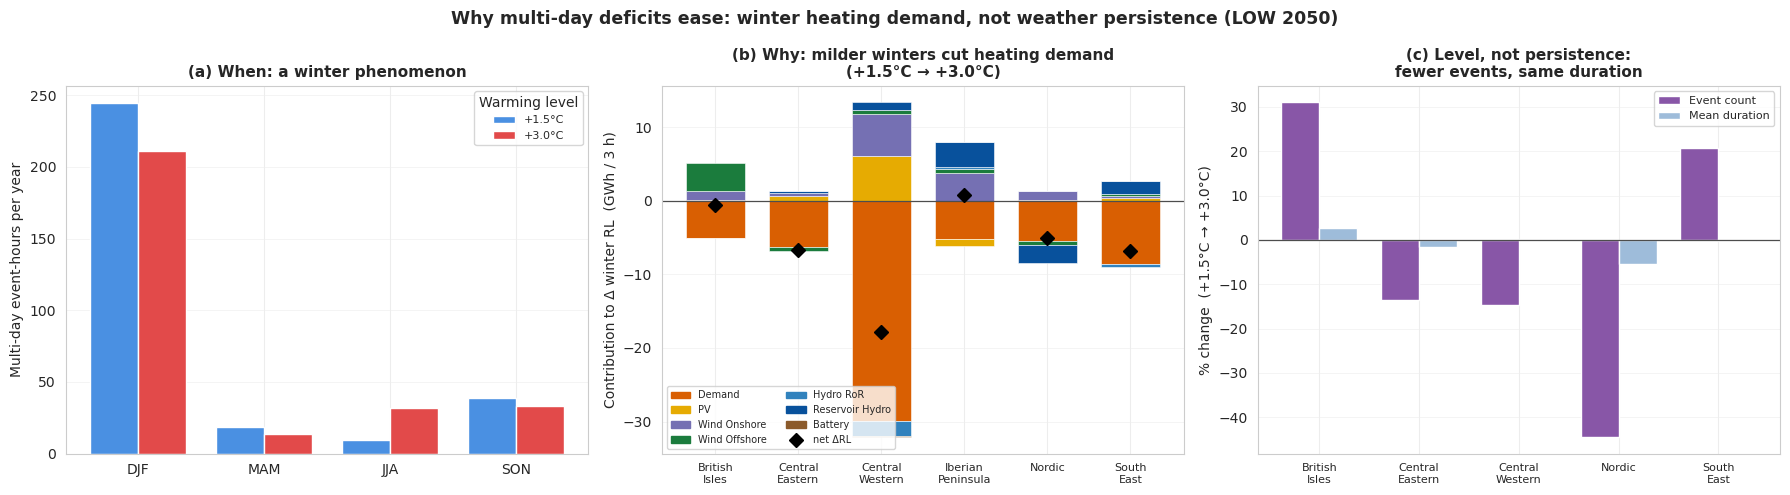

In [22]:
# Multi-day figure: (a) seasonal occurrence, (b) winter-RL driver attribution,
# (c) level (count) vs persistence (duration) change.
_zl = [str(z) for z in zones]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.0))

# (a) multi-day event-hours by season, coldest vs warmest GWL (mean over zones)
ax = axes[0]
_gs = (df_mdseason.groupby(["period", "zone", "season"]).median(numeric_only=True)
                  .groupby(["period", "season"]).mean(numeric_only=True))
_x, _bw = np.arange(len(season_order)), 0.38
for _i, _p in enumerate([_mdp[0], _mdp[-1]]):
    ax.bar(_x + (_i - 0.5) * _bw, [_gs.loc[(_p, s), "md_hours_yr"] for s in season_order],
           _bw, color=period_colors[_p], label=_p)
ax.set_xticks(_x); ax.set_xticklabels(season_order)
ax.set_ylabel("Multi-day event-hours per year")
ax.set_title("(a) When: a winter phenomenon", fontsize=11, fontweight="bold")
ax.legend(title="Warming level", fontsize=8); ax.grid(axis="y", lw=0.4)

# (b) driver attribution of Δ(winter RL) — diverging stacked bars + net marker
ax = axes[1]; _xz = np.arange(len(_zl))
for _zi, _z in enumerate(_zl):
    _c = winter_rl_attribution(_z); _pb = _nb = 0.0
    for _dr in _DRIVERS:
        _v = _c[_dr]
        if abs(_v) < 1e-9:
            continue
        _bot = _pb if _v >= 0 else _nb
        ax.bar(_zi, _v, bottom=_bot, width=0.72, color=driver_palette[_dr],
               edgecolor="white", linewidth=0.4, zorder=2)
        if _v >= 0:
            _pb += _v
        else:
            _nb += _v
    ax.plot(_zi, _c["net"], "D", color="k", ms=7, zorder=4)
ax.axhline(0, color="0.3", lw=0.9)
ax.set_xticks(_xz); ax.set_xticklabels([z.replace("_", "\n") for z in _zl], fontsize=8)
ax.set_ylabel("Contribution to Δ winter RL  (GWh / 3 h)")
ax.set_title(f"(b) Why: milder winters cut heating demand\n({_mdp[0]} → {_mdp[-1]})",
             fontsize=11, fontweight="bold")
_hd = [plt.Rectangle((0, 0), 1, 1, color=driver_palette[d]) for d in _DRIVERS]
_hd.append(plt.Line2D([0], [0], marker="D", color="k", ls="", ms=7))
ax.legend(_hd, _DRIVERS + ["net ΔRL"], fontsize=7, ncol=2, loc="lower left")
ax.grid(axis="y", lw=0.4)

# (c) level vs persistence: % change in count vs mean duration
# restricted to zones with a genuine multi-day regime (>= 1 event/yr at the coldest GWL)
ax = axes[2]
_zl_md = [z for z in _zl if float(_md_gm.xs((_mdp[0], z))["md_events_yr"]) >= 1.0]
_xm, _dc, _dd = np.arange(len(_zl_md)), [], []
for _z in _zl_md:
    _a = _md_gm.xs(_z, level="zone").reindex(_mdp)
    _dc.append(100 * (_a["md_events_yr"].iloc[-1] - _a["md_events_yr"].iloc[0]) / _a["md_events_yr"].iloc[0])
    _dd.append(100 * (_a["md_meandur"].iloc[-1] - _a["md_meandur"].iloc[0]) / _a["md_meandur"].iloc[0])
ax.bar(_xm - _bw / 2, _dc, _bw, color="#8856a7", label="Event count")
ax.bar(_xm + _bw / 2, _dd, _bw, color="#9ebcda", label="Mean duration")
ax.axhline(0, color="0.3", lw=0.9)
ax.set_xticks(_xm); ax.set_xticklabels([z.replace("_", "\n") for z in _zl_md], fontsize=8)
ax.set_ylabel(f"% change  ({_mdp[0]} → {_mdp[-1]})")
ax.set_title("(c) Level, not persistence:\nfewer events, same duration", fontsize=11, fontweight="bold")
ax.legend(fontsize=8); ax.grid(axis="y", lw=0.4)

fig.suptitle(f"Why multi-day deficits ease: winter heating demand, not weather persistence "
             f"({supply_scenario} {supply_year})", fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.show()

**The answer (and the contrast with the sub-daily surge).**

- **When: multi-day events are a winter regime.** Almost all multi-day event-hours fall in **DJF**
  (≈ 150 of ~190 h/yr; panel a), concentrated in the continental / northern zones (Central-Eastern
  alone carries ~580 h/yr). Spring and summer contribute almost nothing.

- **Why they ease: milder winters cut heating demand.** The change in winter residual load is
  **demand-dominated** (panel b): heating demand falls by −6 to −30 GWh/3 h across the northern
  zones, lowering the winter RL *level* so fewer synoptic spells reach the deficit threshold.
  Reduced winter PV / wind partly offset this (they would raise RL) but demand wins.

- **It's a level effect, not a persistence effect.** Mean multi-day duration (~58 h) and the winter
  above-threshold run-length (~8.7 h) barely move; the decline is almost entirely **fewer events**,
  not shorter ones (panel c). Warming lowers the odds of *starting* a multi-day deficit but does not
  change how long the driving weather persists once it does — the opposite of the diurnal (solar)
  clock that shapes the sub-daily events.

- **Same north-west exception.** In the **British Isles**, multi-day events actually *increase*
  (+47 %, 85 → 133 h/yr) because declining **offshore wind** outweighs the heating-demand drop
  (panel b: green offsets orange, net ΔRL ≈ 0) — the same wind-deficit signature seen in its
  sub-daily events.

**In short:** the sub-daily surge is *summer cooling demand* creating new short evening deficits;
the multi-day decline is *winter heating demand* falling so fewer — but equally persistent — long
deficits form. Warming migrates the stress from a persistent winter regime to a diurnal summer one,
except in the wind-dependent north-west where a renewable deficit pushes both upward.

## Figure 4 · Diurnal profile of extreme events + PV context

Percentage of event timesteps by hour of day (per season) and mean PV generation
during events vs the reference-period climatology. The post-solar-noon evening
ramp (hours 18–21) dominates, most strongly in JJA.

**Key result —** events concentrate on the evening ramp (18–21 h), peaking in summer (~40% of JJA event-steps at 18:00) — the post-solar-noon net-load peak, not midday.

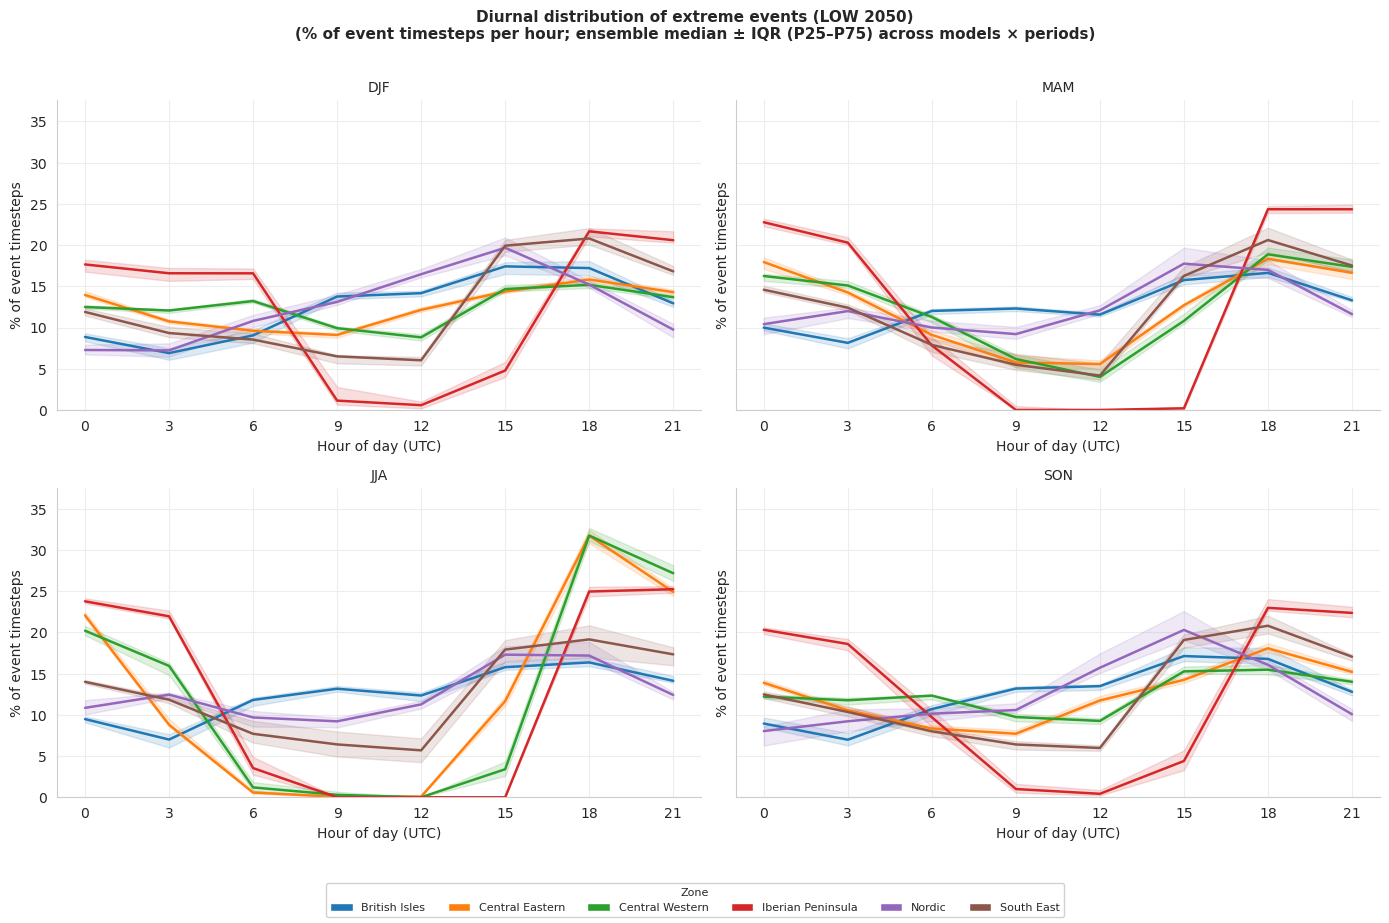

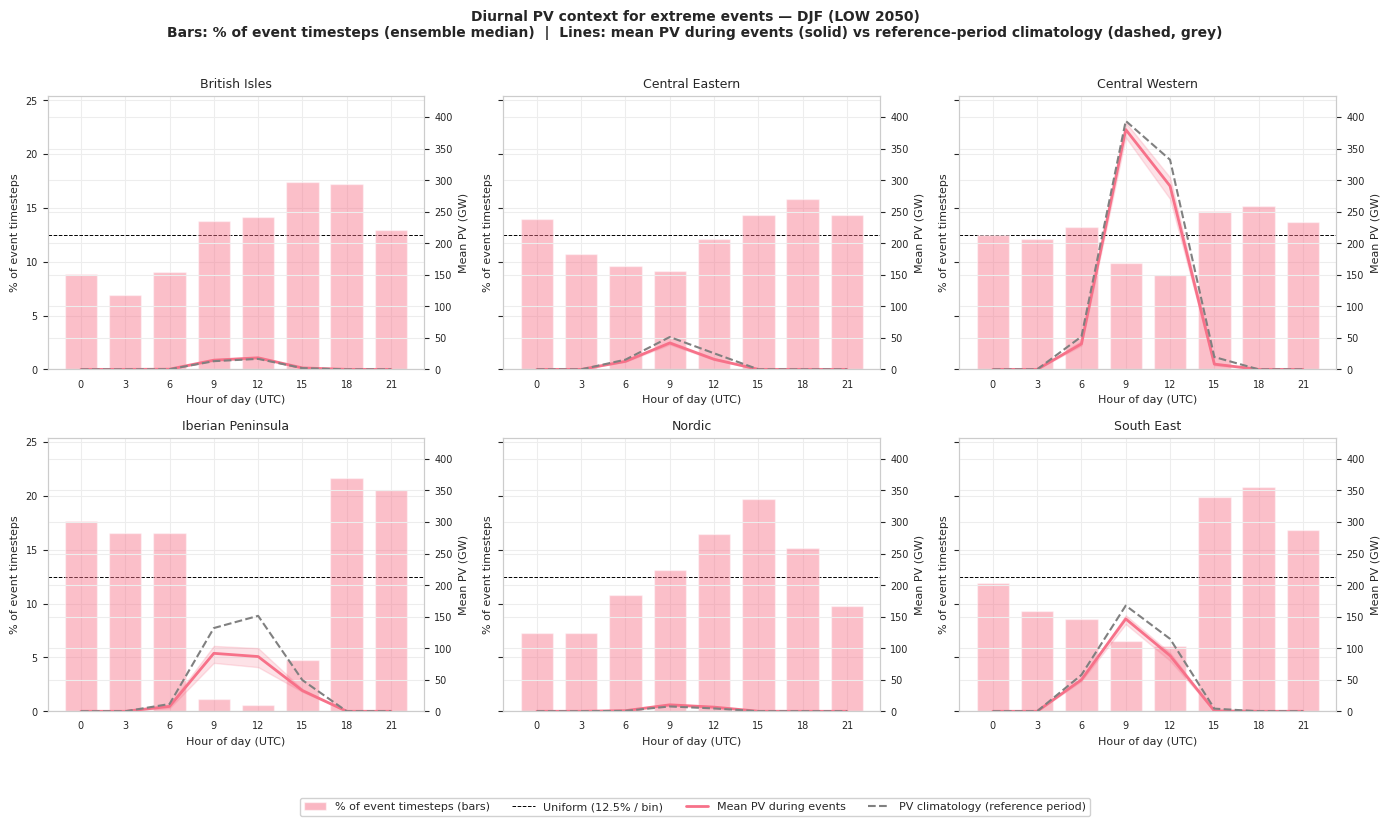

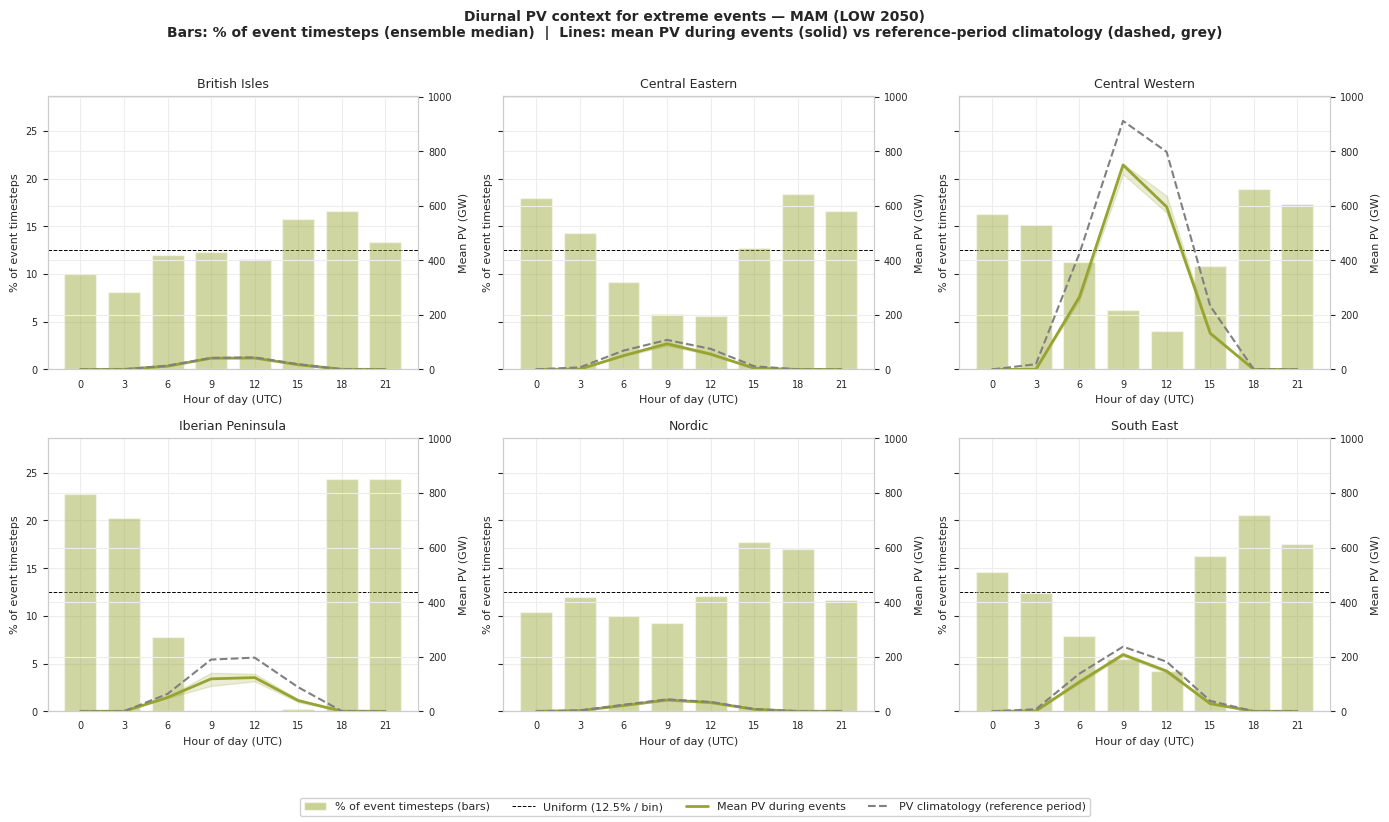

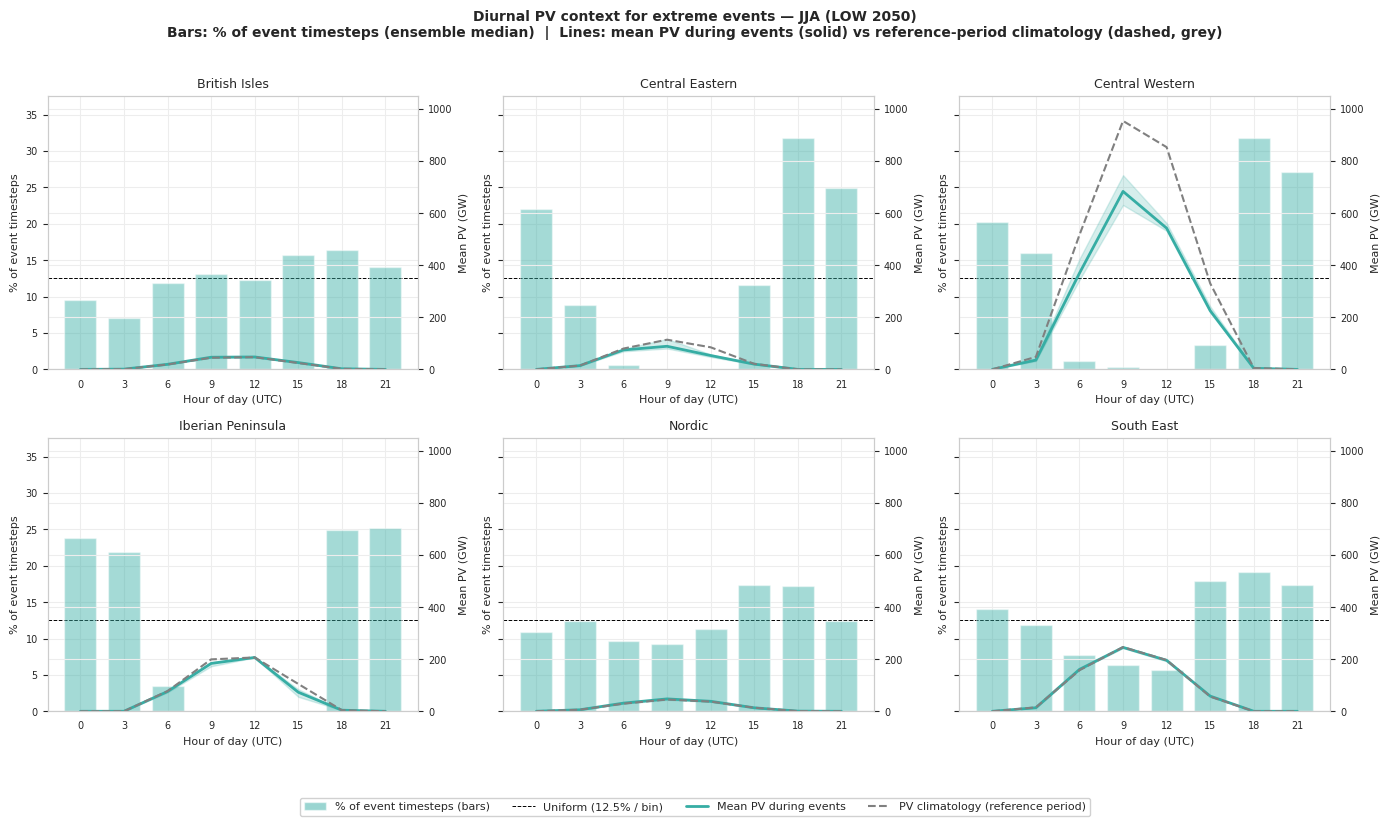

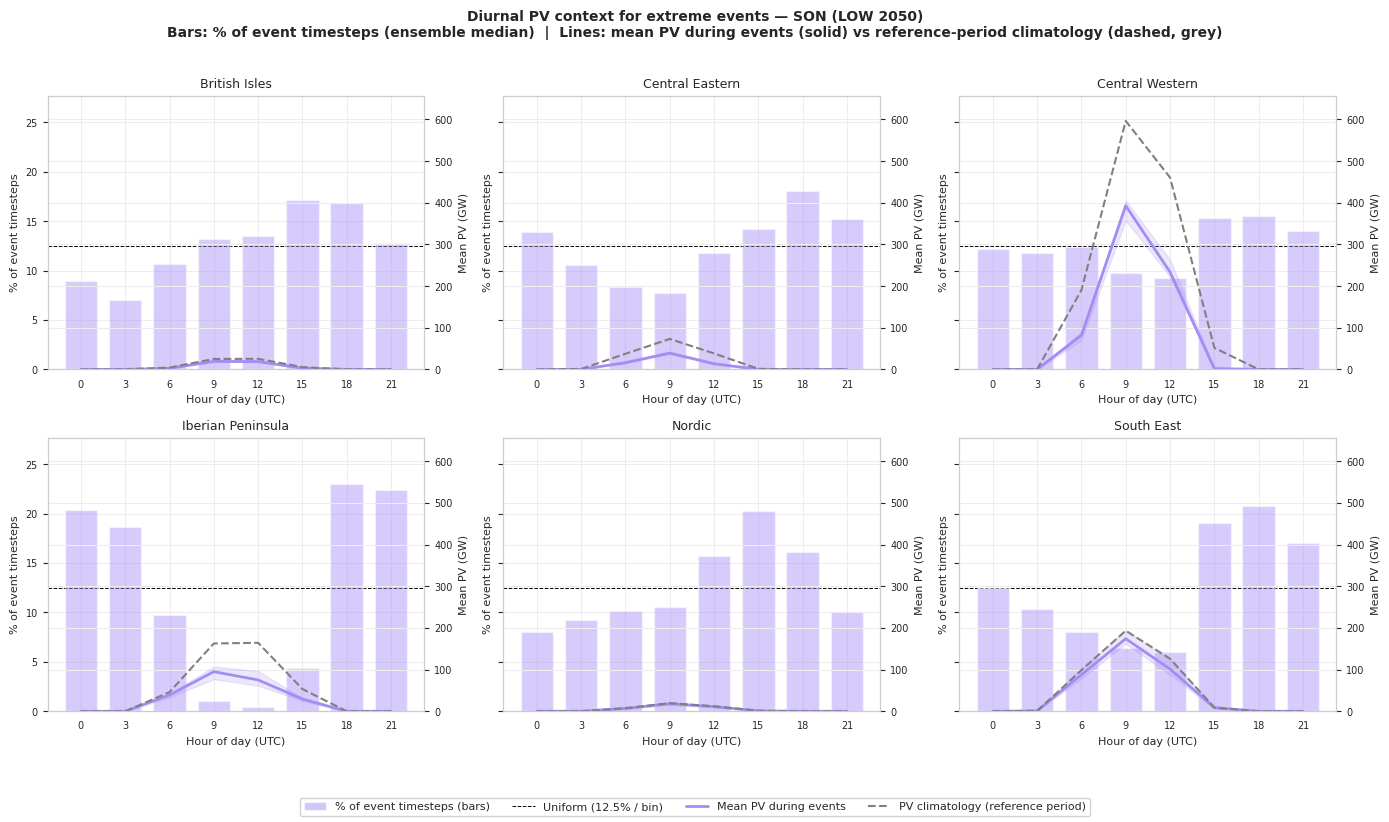

In [23]:
plot_event_diurnal_profile(
    df_diurnal, zones=zones, season_order=season_order, period_defs=period_defs,
    period_colors=period_colors, supply_scenario=supply_scenario, supply_year=supply_year, spread=SPREAD,
)

## Figure 5 · Seasonal-conditional event frequency

Inter-model spread of seasonal event frequency per zone/period. Highlights the
two opposing headline signals: the Iberian summer/spring rise and the
Central-Eastern winter decline.

**Key result —** Iberian and South-Eastern summer events roughly triple by +3.0 °C (≈160→430 per 20-yr window) while Central-Eastern winter events decline — opposite-signed regional responses.

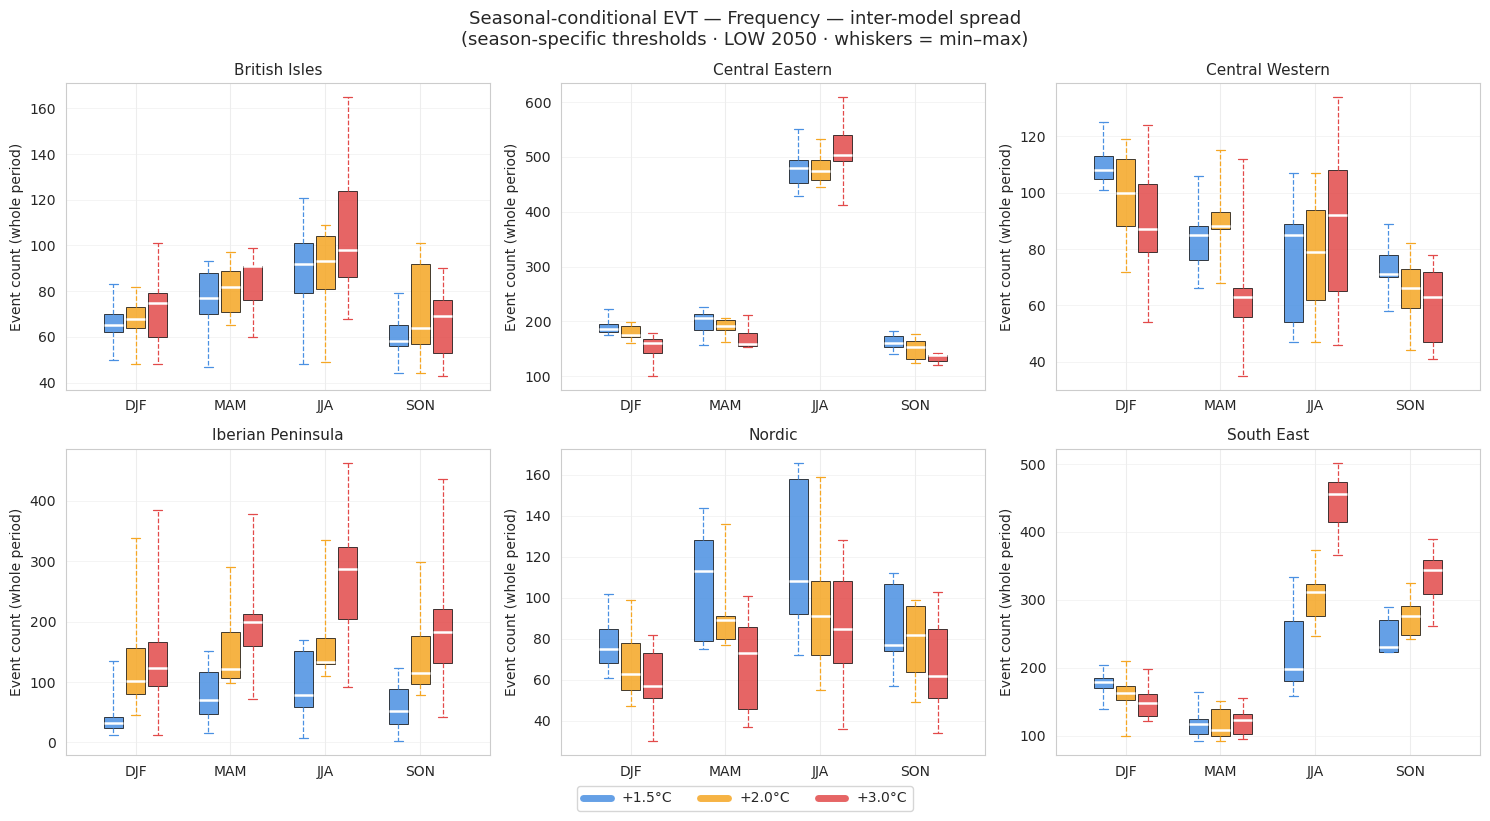

In [24]:
plot_seasonal_conditional_metrics(
    df_seasonal_evt,
    metrics=[("Frequency", "Event count (whole period)", "Frequency")],
    zones=zones, period_defs=period_defs, season_order=season_order,
    period_colors=period_colors, supply_scenario=supply_scenario, supply_year=supply_year, spread="minmax",
)

## Figure 6 · Seasonal flexibility attenuation

Per-event severity reduction from battery and reservoir dispatch, by season and
zone. Two complementary views are shown:

- **Shapley shares** (`*_attenuation_share_pct`) — an additive split of the
  *combined* attenuation between battery and reservoir; the two shares sum to
  `combined_attenuation_pct`. **Use these for "who does what."**
- **Marginal (leave-one-out)** attenuations (`*_attenuation_pct`) — each measured
  against its own counterfactual denominator. Where battery and reservoir act on
  the *same* deficits (e.g. Iberian evening peaks) these overlap and can sum to
  **>100%**, so they answer "how critical is each on its own", not "what share".

**Key result —** combined storage attenuates ~50–80% of event severity in the
solar-driven zones (Iberian, South-East) but only ~10–25% in Nordic and in
winter; the Shapley split shows reservoir, not batteries, carries most of that
reduction in the hydro-rich Mediterranean — storage tames the diurnal regime, not the synoptic one.

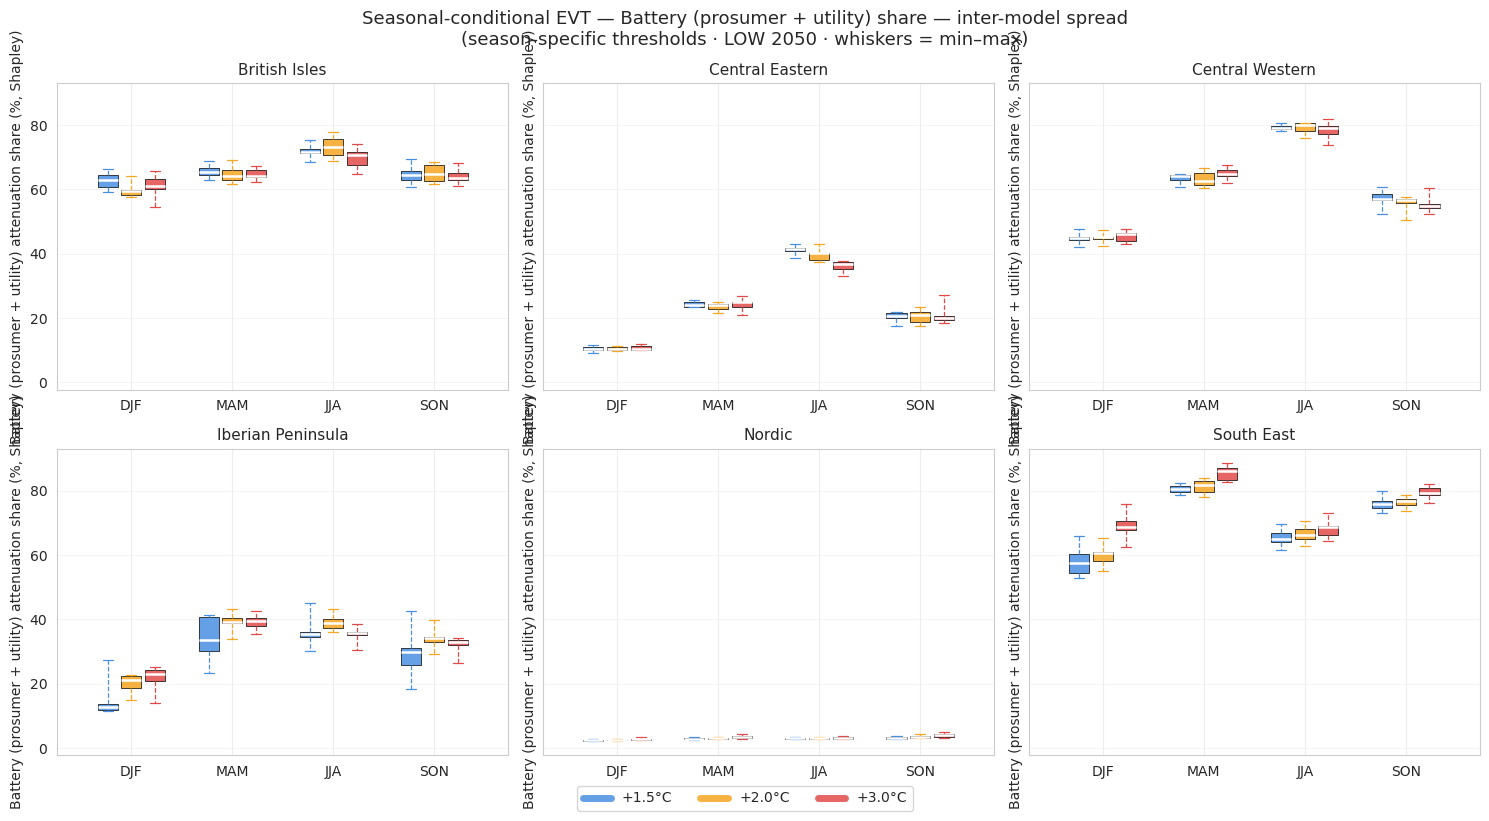

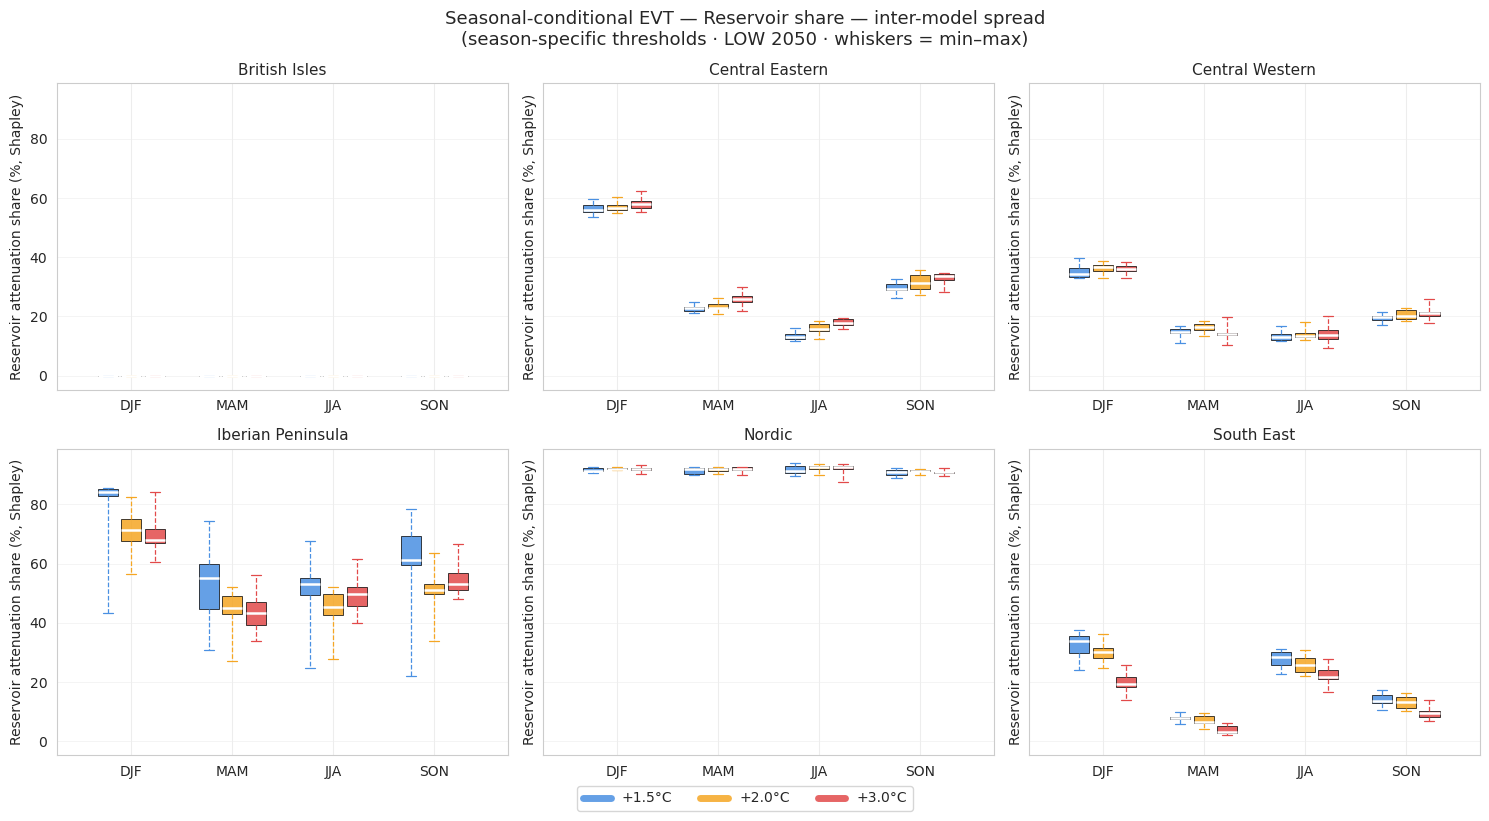

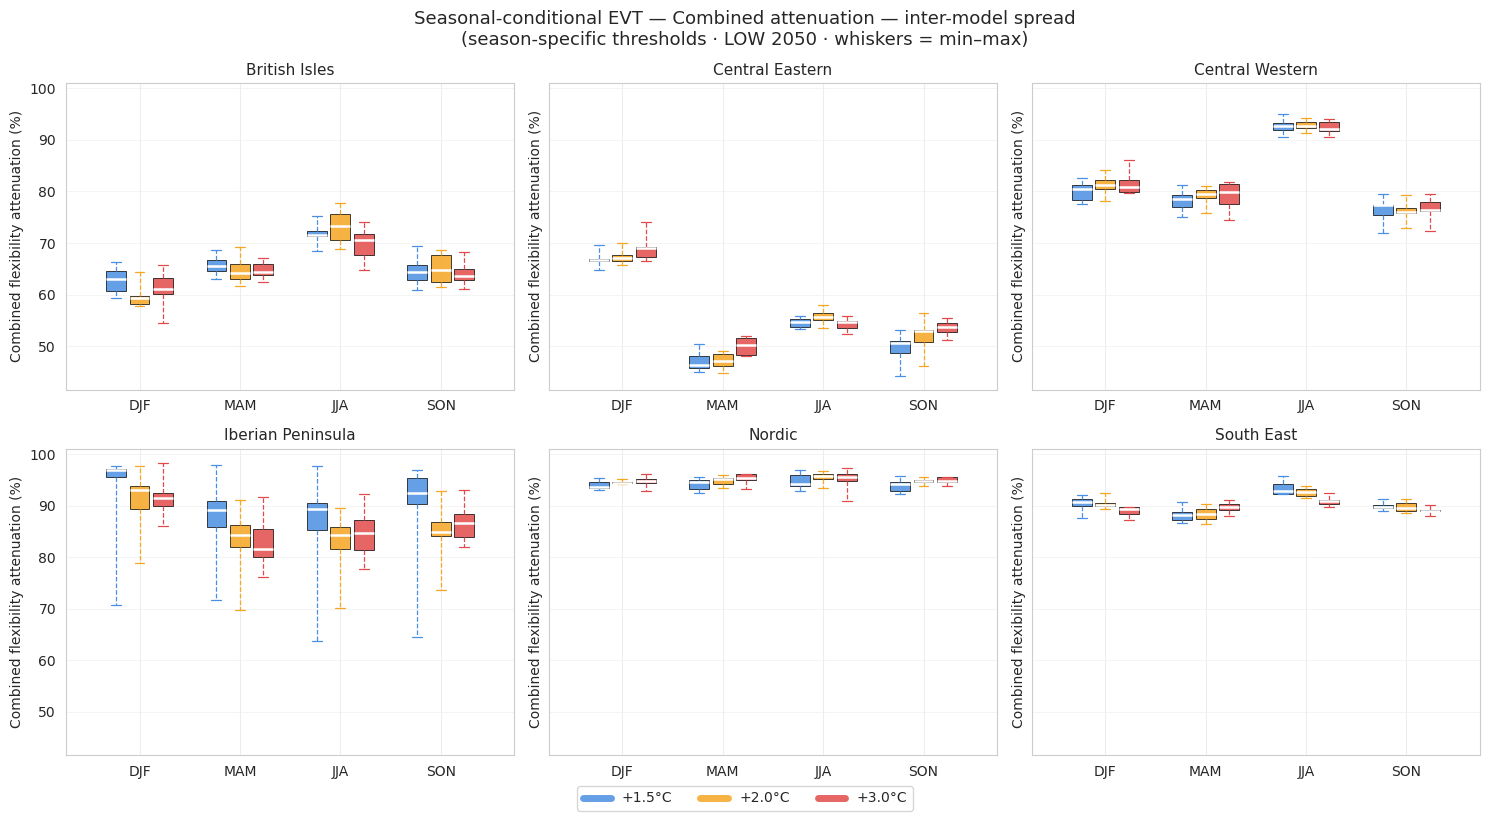

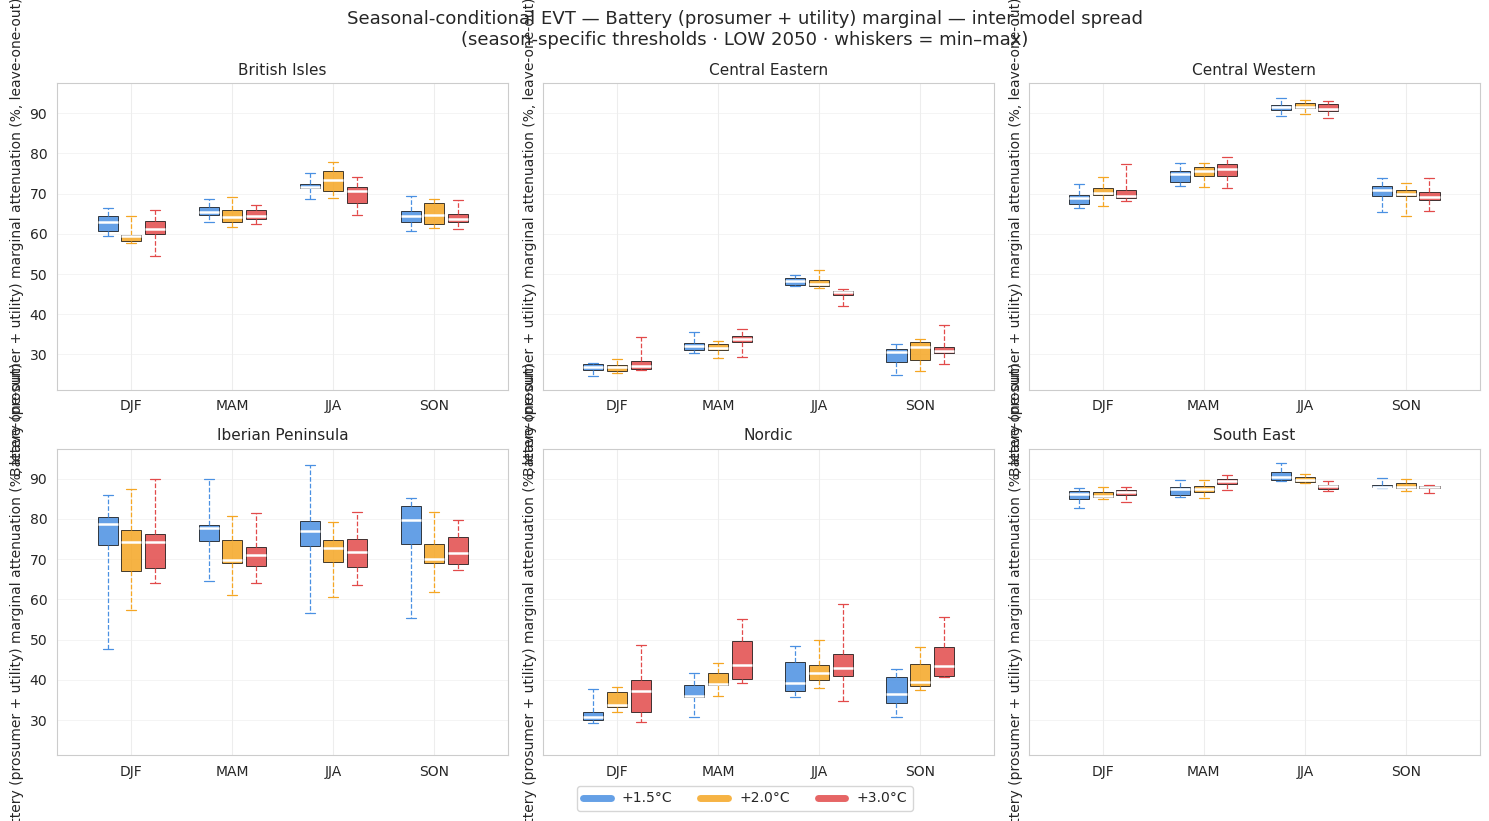

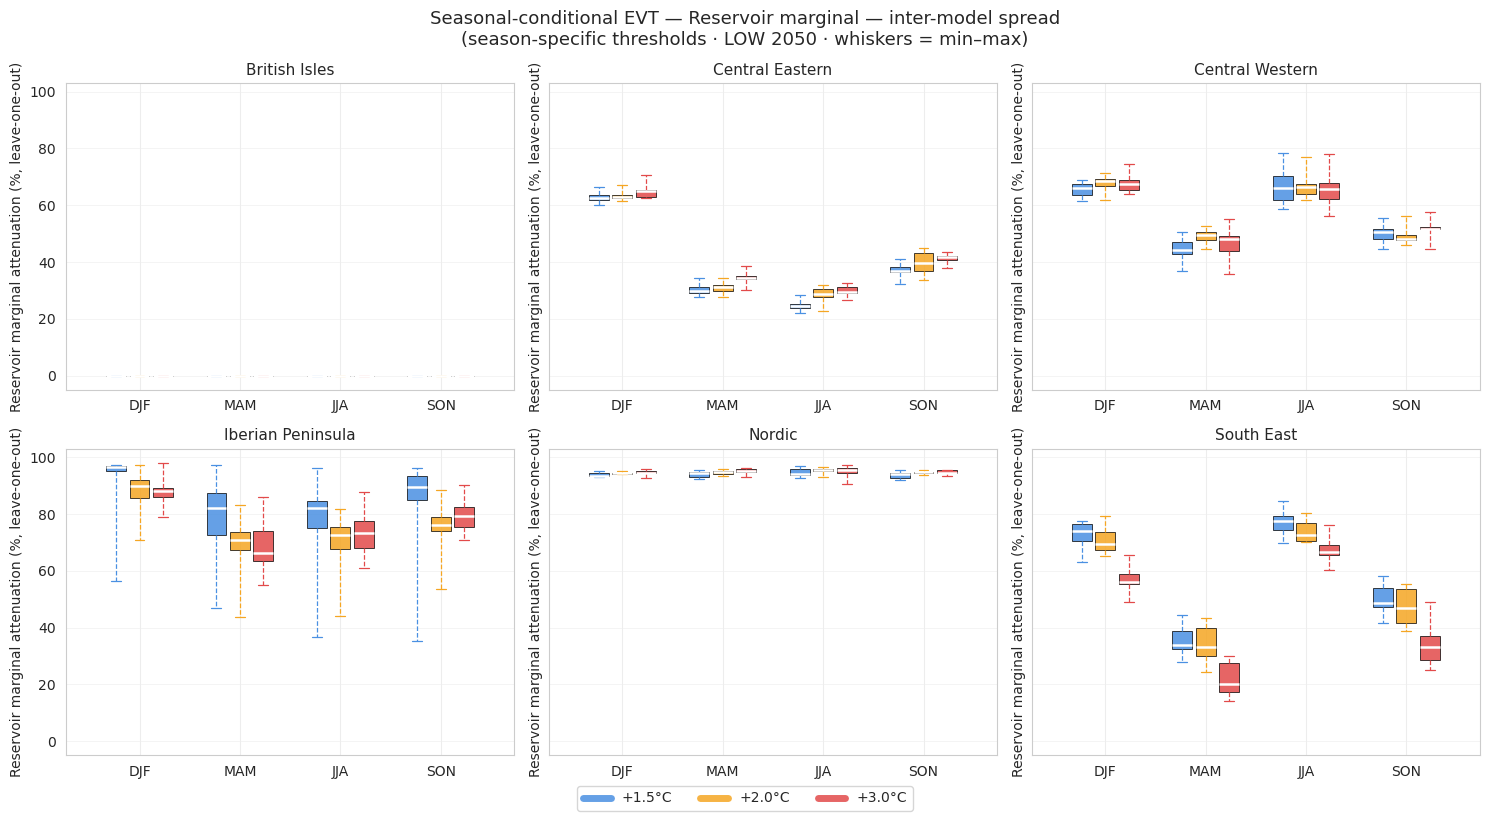

In [25]:
# Battery panels are labelled according to BATTERY_MODE: under the lumped 'system'
# scheme `battery_*` covers prosumer + utility together, and the per-asset panels do
# not exist.  Specs whose column is absent (or all-NaN) for this run are dropped.
_BATT = "Battery (prosumer + utility)" if BATTERY_MODE == "lumped" else "Battery"
_all_specs = [
    # Additive Shapley shares (battery + reservoir sum to the combined attenuation)
    ("battery_attenuation_share_pct",   f"{_BATT} attenuation share (%, Shapley)",   f"{_BATT} share"),
    ("reservoir_attenuation_share_pct", "Reservoir attenuation share (%, Shapley)",  "Reservoir share"),
    ("combined_attenuation_pct",        "Combined flexibility attenuation (%)",      "Combined attenuation"),
    # Marginal (leave-one-out) attenuations — independent denominators; can sum to >100%
    ("battery_attenuation_pct",   f"{_BATT} marginal attenuation (%, leave-one-out)",  f"{_BATT} marginal"),
    ("prosumer_attenuation_pct",  "Prosumer marginal attenuation (%, leave-one-out)",  "Prosumer marginal"),
    ("utility_attenuation_pct",   "Utility marginal attenuation (%, leave-one-out)",   "Utility marginal"),
    ("reservoir_attenuation_pct", "Reservoir marginal attenuation (%, leave-one-out)", "Reservoir marginal"),
]
_avail = set(flex_metric_columns(df_seasonal_evt, "all"))
_specs = [s for s in _all_specs if s[0] in _avail]

plot_seasonal_conditional_metrics(
    df_seasonal_evt,
    metrics=_specs,
    zones=zones, period_defs=period_defs, season_order=season_order,
    period_colors=period_colors, supply_scenario=supply_scenario, supply_year=supply_year,
    sharey=True, spread="minmax",
)

## Figure 7 · G2 — Compound zone-pair co-occurrence

Fraction of Zone A exceedance timesteps that fall within **±24 h** of a Zone B
exceedance (annual scale; window set by `COOC_WINDOW_STEPS`).

- **7a** — all events (the established view): absolute co-occurrence per period
  plus the change vs +1.5 °C.
- **7b** — conditioned on duration class: do long **multi_day** (synoptic) events
  co-occur across zones more than short **sub_daily** events? Spatial coherence of
  blocking is the systemic-risk question behind cross-border balancing. Each row
  shows the **+1.5 °C baseline** (absolute %, left) followed by the **change vs
  +1.5 °C** for each higher warming level (pp, diverging scale).

Degenerate zones (`DEGENERATE_ZONES`, e.g. Nordic) are shown for completeness but
should be read as a potential *exporter*, not as a stressed zone (see coverage
diagnostic). Cells with very few class-member timesteps are hatched.

**Model agreement.** On every *change* panel an **×** marks cells where fewer than
6/9 models agree on the sign of the co-occurrence change — i.e. the direction is
not robust across the ensemble. In 7a these are the difference panels from
`plot_zone_cooccurrence_heatmaps(..., stipple_agreement=True)`; in 7b they are the
Δ-vs-+1.5 °C panels (the diagonal is omitted, since self-co-occurrence is trivially
100 % → 0 pp).

**Key result —** multi_day events are spatially coherent across the northern/western wind zones (high cross-zone co-occurrence) whereas sub_daily events stay largely zone-local — so simultaneous multi-zone shortfalls cap the relief interconnection can offer during synoptic spells.

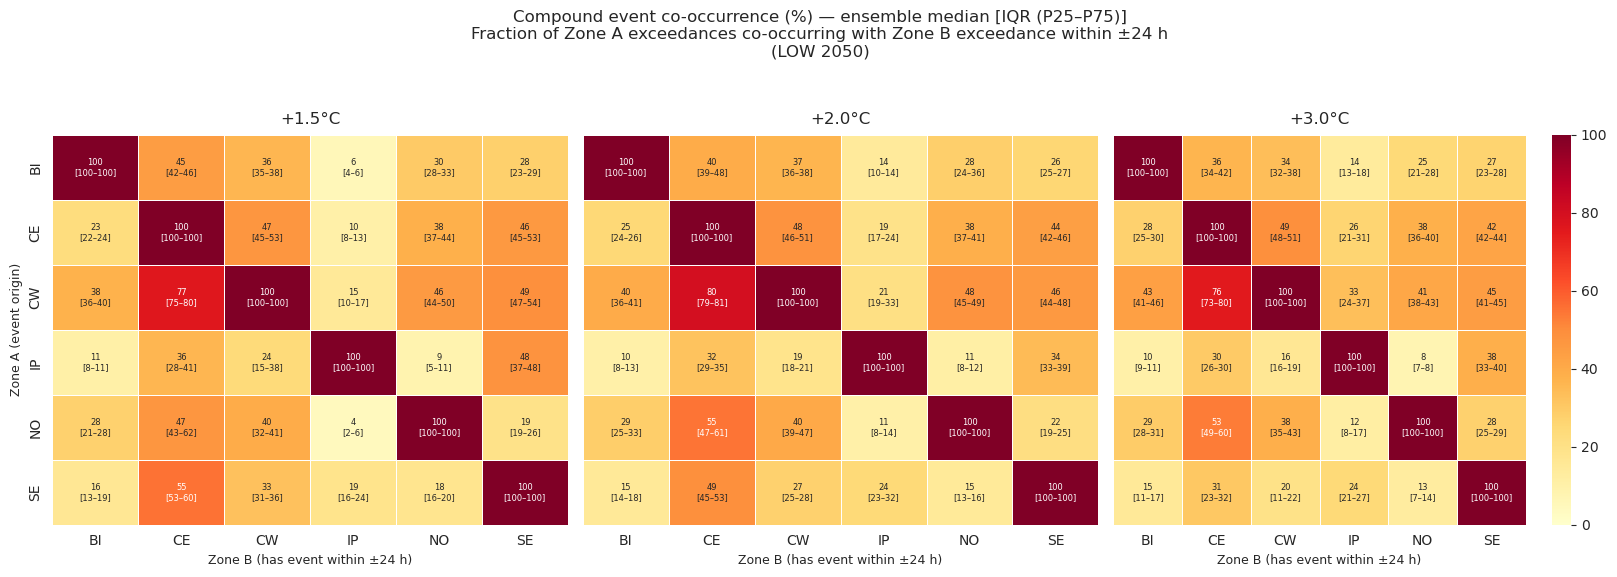

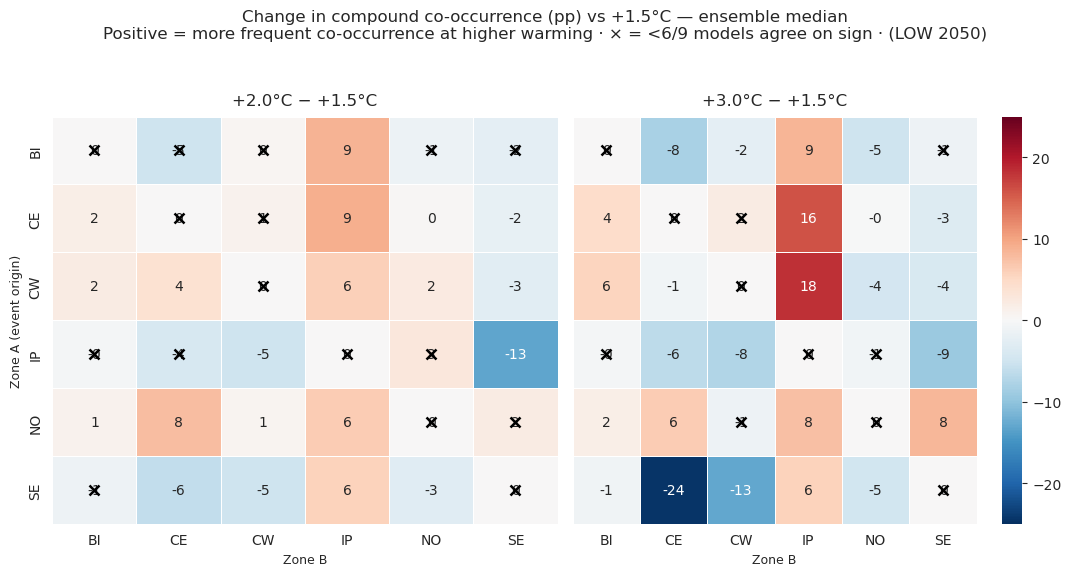

In [26]:
# 7a — all events, annual scale
df_coo_all = compute_zone_pair_cooccurrence(
    _cache_rl, active_thresholds, period_defs, models, zones,
    window_steps=COOC_WINDOW_STEPS,
)
plot_zone_cooccurrence_heatmaps(
    df_coo_all, zones=zones, period_defs=period_defs,
    supply_scenario=supply_scenario, supply_year=supply_year,
    window_steps=COOC_WINDOW_STEPS,
    stipple_agreement=True, robust_n=ROBUSTNESS_THRESHOLD,  # × on change panels where <ROBUSTNESS_THRESHOLD/9 models agree on sign
    spread=SPREAD,
)

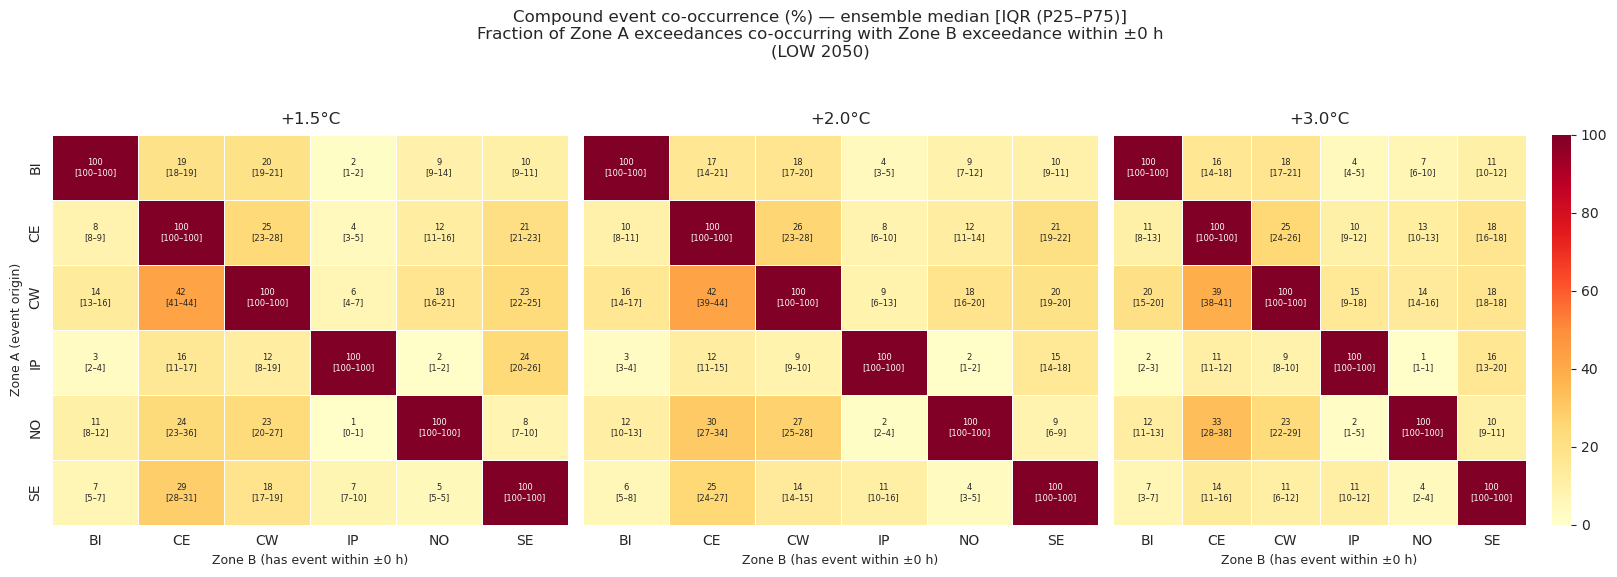

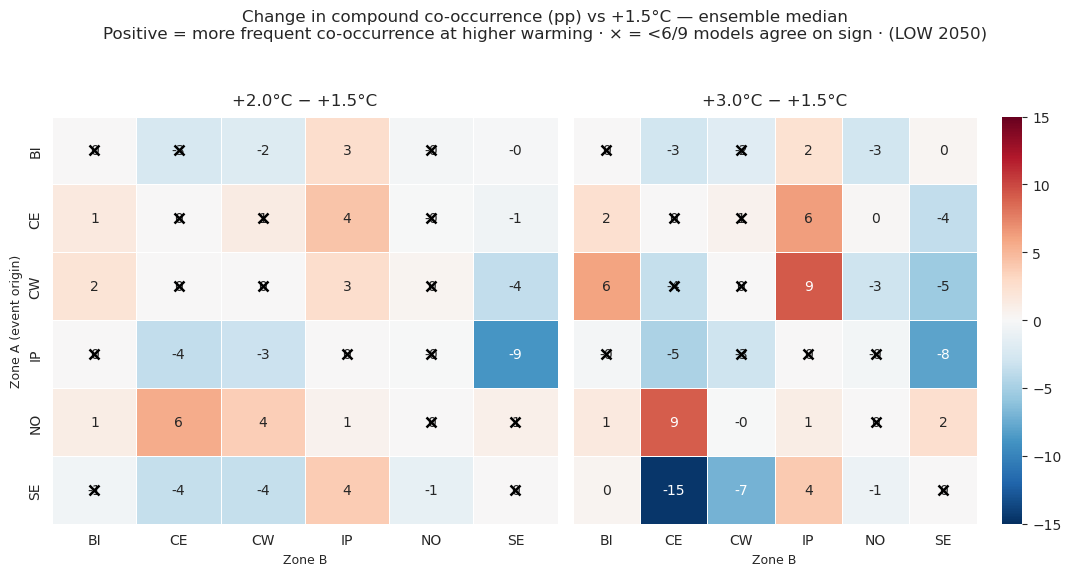

In [27]:
# 7a — all events, annual scale
df_coo_all_simultaneous = compute_zone_pair_cooccurrence(
    _cache_rl, active_thresholds, period_defs, models, zones,
    window_steps=0,
)
plot_zone_cooccurrence_heatmaps(
    df_coo_all_simultaneous, zones=zones, period_defs=period_defs,
    supply_scenario=supply_scenario, supply_year=supply_year,
    window_steps=0,
    stipple_agreement=True, robust_n=ROBUSTNESS_THRESHOLD,  # × on change panels where <ROBUSTNESS_THRESHOLD/9 models agree on sign
)

df_coo_dc: 1944 rows


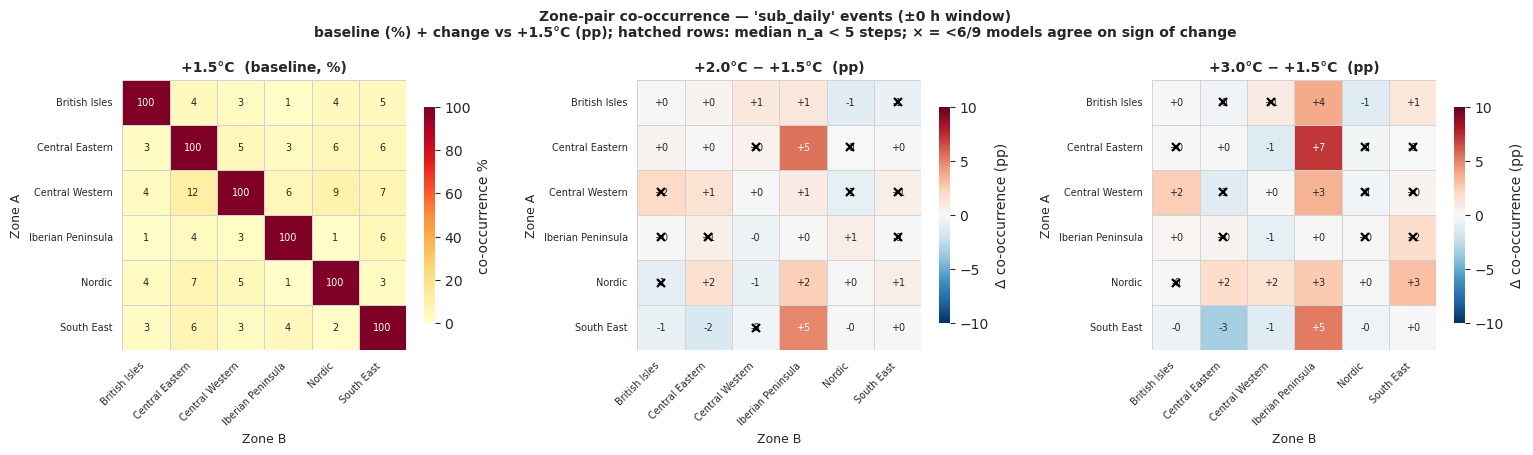

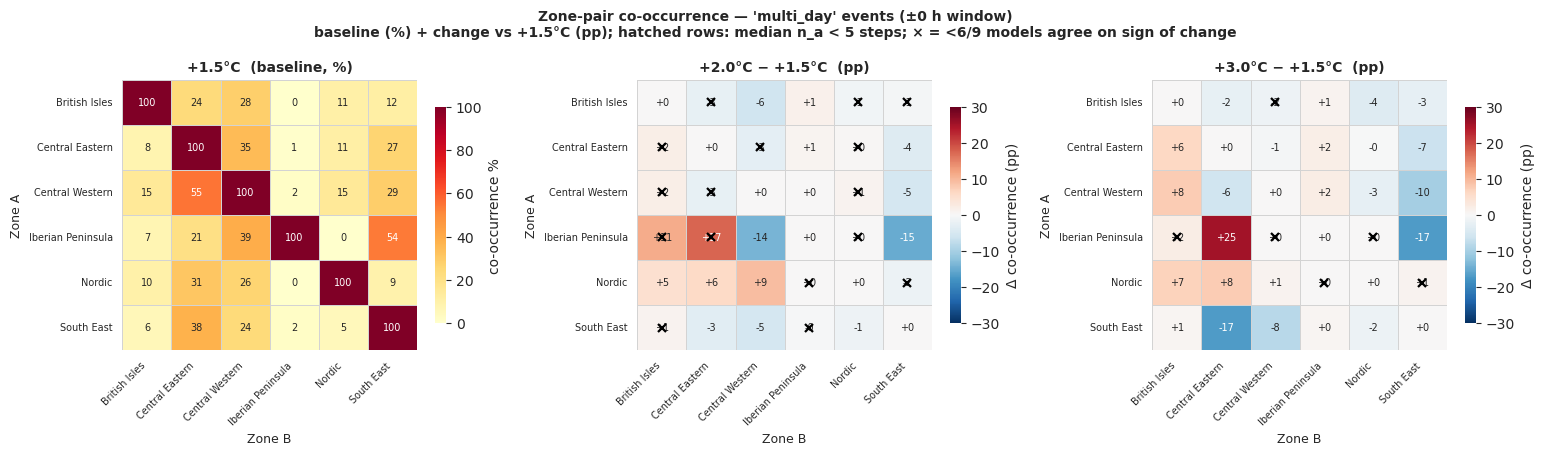

In [28]:
# 7b — conditioned on duration class
COOC_WINDOW_STEPS = 0
df_coo_dc = compute_zone_pair_cooccurrence_by_duration(
    _cache_rl, active_thresholds, period_defs, models, zones,
    window_steps=COOC_WINDOW_STEPS, method=EVENT_DETECTION_METHOD, duration_bins=DURATION_BINS,
)
print(f"df_coo_dc: {df_coo_dc.shape[0]} rows")

_zl = [str(z) for z in zones]
_MIN_NA   = 5   # mask zone-A rows with fewer than this many class-member timesteps (ensemble median)
_ref_cooc  = period_names[0]
_comp_cooc = [p for p in period_names if p != _ref_cooc]

def _cooc_sign_agree(sub_dc, ref, comp, za, zb):
    r = (sub_dc[(sub_dc["zone_a"] == za) & (sub_dc["zone_b"] == zb) & (sub_dc["period"] == ref)]
         .set_index("model")["co_occurrence_pct"])
    c = (sub_dc[(sub_dc["zone_a"] == za) & (sub_dc["zone_b"] == zb) & (sub_dc["period"] == comp)]
         .set_index("model")["co_occurrence_pct"])
    common = r.index.intersection(c.index)
    d = (c.loc[common] - r.loc[common]).dropna()
    return (max(int((d > 0).sum()), int((d < 0).sum())), len(d)) if len(d) else (np.nan, 0)

def _hatch_and_gray(ax, na, period, n_zones):
    # Hatch sparse zone-A rows and gray degenerate-zone labels on an axis.
    for i, za in enumerate(_zl):
        n_med = na.get((period, za), np.nan)
        if not np.isfinite(n_med) or n_med < _MIN_NA:
            ax.add_patch(plt.Rectangle((0, i), n_zones, 1, fill=True, facecolor="lightgray",
                                       alpha=0.55, hatch="///", edgecolor="gray", zorder=4))
        if str(za) in DEGENERATE_ZONES:
            ax.get_yticklabels()[i].set_color("gray")

for dc in DURATION_CLASS_ORDER:
    sub = df_coo_dc[df_coo_dc["duration_class"] == dc]
    med = (sub.groupby(["period", "zone_a", "zone_b"])["co_occurrence_pct"].median().reset_index())
    na  = (sub.groupby(["period", "zone_a"])["n_a"].median())
    med_piv = {
        p: (med[med["period"] == p].pivot(index="zone_a", columns="zone_b", values="co_occurrence_pct")
            .reindex(index=_zl, columns=_zl))
        for p in period_names
    }
    # Symmetric colour scale shared across the difference panels
    _absmax = np.nanmax([np.nanmax(np.abs((med_piv[c] - med_piv[_ref_cooc]).values))
                         for c in _comp_cooc]) if _comp_cooc else 10.0
    vmax = float(np.ceil((_absmax if np.isfinite(_absmax) else 10.0) / 5) * 5) or 10.0

    ncols = 1 + len(_comp_cooc)
    fig, axes = plt.subplots(1, ncols, figsize=(5.2 * ncols, 4.6))
    if ncols == 1:
        axes = [axes]
    fig.suptitle(f"Zone-pair co-occurrence — '{dc}' events (±{COOC_WINDOW_STEPS*3} h window)\n"
                 f"baseline (%) + change vs {_ref_cooc} (pp); hatched rows: median n_a < {_MIN_NA} steps; "
                 f"× = <{ROBUSTNESS_THRESHOLD}/{len(models)} models agree on sign of change",
                 fontsize=10, fontweight="bold")

    # Panel 0 — baseline absolute co-occurrence
    ax = axes[0]
    sns.heatmap(med_piv[_ref_cooc], ax=ax, annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100,
                cbar_kws={"label": "co-occurrence %", "shrink": 0.8},
                linewidths=0.5, linecolor="lightgray", annot_kws={"size": 7})
    _hatch_and_gray(ax, na, _ref_cooc, len(_zl))
    ax.set_title(f"{_ref_cooc}  (baseline, %)", fontsize=10, fontweight="bold")
    ax.set_xlabel("Zone B", fontsize=9); ax.set_ylabel("Zone A", fontsize=9)
    ax.set_xticklabels([z.replace("_", " ") for z in _zl], rotation=45, ha="right", fontsize=7)
    ax.set_yticklabels([z.replace("_", " ") for z in _zl], rotation=0, fontsize=7)

    # Panels 1.. — change vs baseline (pp), with model-agreement stippling
    for ax, comp in zip(axes[1:], _comp_cooc):
        dmat = med_piv[comp] - med_piv[_ref_cooc]
        sns.heatmap(dmat, ax=ax, annot=True, fmt="+.0f", cmap="RdBu_r", center=0,
                    vmin=-vmax, vmax=vmax, cbar_kws={"label": "Δ co-occurrence (pp)", "shrink": 0.8},
                    linewidths=0.5, linecolor="lightgray", annot_kws={"size": 7})
        # hatch rows sparse in EITHER period (a change needs events in both)
        for i, za in enumerate(_zl):
            n_ref = na.get((_ref_cooc, za), np.nan); n_cmp = na.get((comp, za), np.nan)
            if not (np.isfinite(n_ref) and np.isfinite(n_cmp)) or min(n_ref, n_cmp) < _MIN_NA:
                ax.add_patch(plt.Rectangle((0, i), len(_zl), 1, fill=True, facecolor="lightgray",
                                           alpha=0.55, hatch="///", edgecolor="gray", zorder=4))
            if str(za) in DEGENERATE_ZONES:
                ax.get_yticklabels()[i].set_color("gray")
            for j, zb in enumerate(_zl):
                if za == zb:
                    continue  # self co-occurrence is trivially 100 % → 0 pp change
                n_agree, n_used = _cooc_sign_agree(sub, _ref_cooc, comp, za, zb)
                if n_used > 0 and (not np.isfinite(n_agree) or n_agree < ROBUSTNESS_THRESHOLD):
                    ax.plot(j + 0.5, i + 0.5, "x", color="black", markersize=6, markeredgewidth=1.6, zorder=6)
        ax.set_title(f"{comp} − {_ref_cooc}  (pp)", fontsize=10, fontweight="bold")
        ax.set_xlabel("Zone B", fontsize=9); ax.set_ylabel("Zone A", fontsize=9)
        ax.set_xticklabels([z.replace("_", " ") for z in _zl], rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels([z.replace("_", " ") for z in _zl], rotation=0, fontsize=7)
    plt.tight_layout(); plt.show()

df_coo_dc: 1944 rows


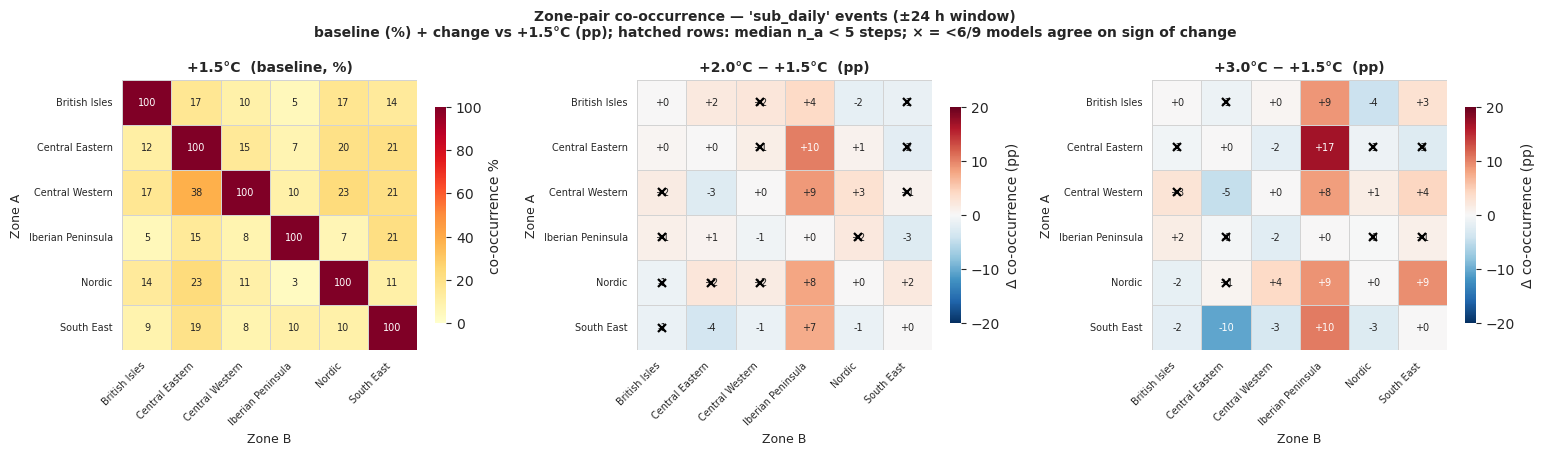

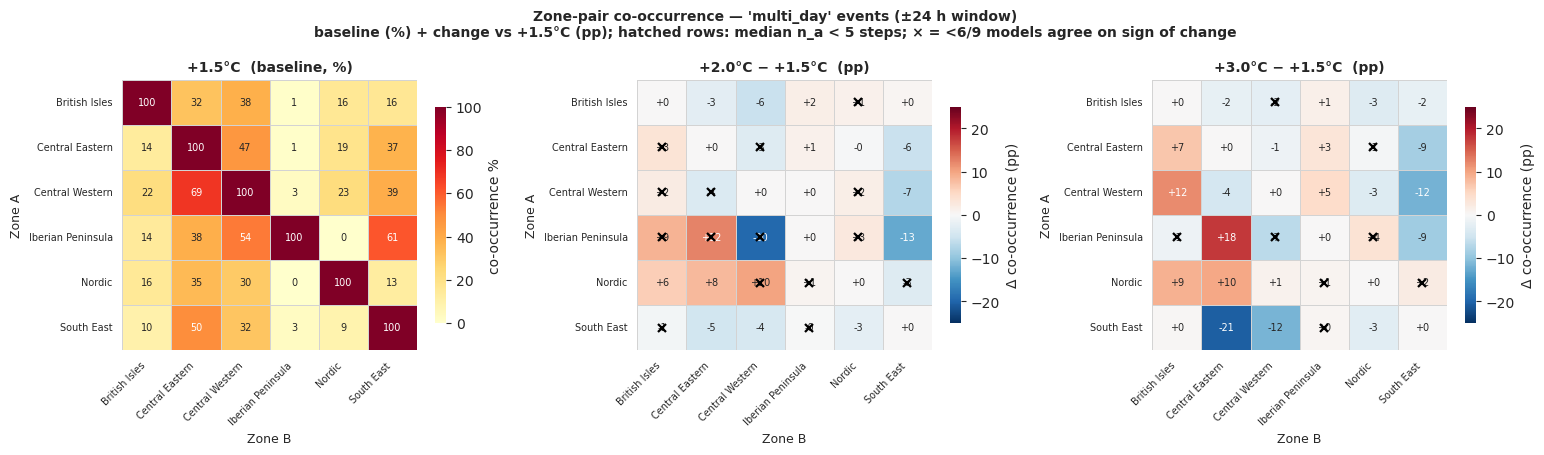

In [29]:
# 7b — conditioned on duration class
COOC_WINDOW_STEPS = 8
df_coo_dc = compute_zone_pair_cooccurrence_by_duration(
    _cache_rl, active_thresholds, period_defs, models, zones,
    window_steps=COOC_WINDOW_STEPS, method=EVENT_DETECTION_METHOD, duration_bins=DURATION_BINS,
)
print(f"df_coo_dc: {df_coo_dc.shape[0]} rows")

_zl = [str(z) for z in zones]
_MIN_NA   = 5   # mask zone-A rows with fewer than this many class-member timesteps (ensemble median)
_ref_cooc  = period_names[0]
_comp_cooc = [p for p in period_names if p != _ref_cooc]

def _cooc_sign_agree(sub_dc, ref, comp, za, zb):
    r = (sub_dc[(sub_dc["zone_a"] == za) & (sub_dc["zone_b"] == zb) & (sub_dc["period"] == ref)]
         .set_index("model")["co_occurrence_pct"])
    c = (sub_dc[(sub_dc["zone_a"] == za) & (sub_dc["zone_b"] == zb) & (sub_dc["period"] == comp)]
         .set_index("model")["co_occurrence_pct"])
    common = r.index.intersection(c.index)
    d = (c.loc[common] - r.loc[common]).dropna()
    return (max(int((d > 0).sum()), int((d < 0).sum())), len(d)) if len(d) else (np.nan, 0)

def _hatch_and_gray(ax, na, period, n_zones):
    # Hatch sparse zone-A rows and gray degenerate-zone labels on an axis.
    for i, za in enumerate(_zl):
        n_med = na.get((period, za), np.nan)
        if not np.isfinite(n_med) or n_med < _MIN_NA:
            ax.add_patch(plt.Rectangle((0, i), n_zones, 1, fill=True, facecolor="lightgray",
                                       alpha=0.55, hatch="///", edgecolor="gray", zorder=4))
        if str(za) in DEGENERATE_ZONES:
            ax.get_yticklabels()[i].set_color("gray")

for dc in DURATION_CLASS_ORDER:
    sub = df_coo_dc[df_coo_dc["duration_class"] == dc]
    med = (sub.groupby(["period", "zone_a", "zone_b"])["co_occurrence_pct"].median().reset_index())
    na  = (sub.groupby(["period", "zone_a"])["n_a"].median())
    med_piv = {
        p: (med[med["period"] == p].pivot(index="zone_a", columns="zone_b", values="co_occurrence_pct")
            .reindex(index=_zl, columns=_zl))
        for p in period_names
    }
    # Symmetric colour scale shared across the difference panels
    _absmax = np.nanmax([np.nanmax(np.abs((med_piv[c] - med_piv[_ref_cooc]).values))
                         for c in _comp_cooc]) if _comp_cooc else 10.0
    vmax = float(np.ceil((_absmax if np.isfinite(_absmax) else 10.0) / 5) * 5) or 10.0

    ncols = 1 + len(_comp_cooc)
    fig, axes = plt.subplots(1, ncols, figsize=(5.2 * ncols, 4.6))
    if ncols == 1:
        axes = [axes]
    fig.suptitle(f"Zone-pair co-occurrence — '{dc}' events (±{COOC_WINDOW_STEPS*3} h window)\n"
                 f"baseline (%) + change vs {_ref_cooc} (pp); hatched rows: median n_a < {_MIN_NA} steps; "
                 f"× = <{ROBUSTNESS_THRESHOLD}/{len(models)} models agree on sign of change",
                 fontsize=10, fontweight="bold")

    # Panel 0 — baseline absolute co-occurrence
    ax = axes[0]
    sns.heatmap(med_piv[_ref_cooc], ax=ax, annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100,
                cbar_kws={"label": "co-occurrence %", "shrink": 0.8},
                linewidths=0.5, linecolor="lightgray", annot_kws={"size": 7})
    _hatch_and_gray(ax, na, _ref_cooc, len(_zl))
    ax.set_title(f"{_ref_cooc}  (baseline, %)", fontsize=10, fontweight="bold")
    ax.set_xlabel("Zone B", fontsize=9); ax.set_ylabel("Zone A", fontsize=9)
    ax.set_xticklabels([z.replace("_", " ") for z in _zl], rotation=45, ha="right", fontsize=7)
    ax.set_yticklabels([z.replace("_", " ") for z in _zl], rotation=0, fontsize=7)

    # Panels 1.. — change vs baseline (pp), with model-agreement stippling
    for ax, comp in zip(axes[1:], _comp_cooc):
        dmat = med_piv[comp] - med_piv[_ref_cooc]
        sns.heatmap(dmat, ax=ax, annot=True, fmt="+.0f", cmap="RdBu_r", center=0,
                    vmin=-vmax, vmax=vmax, cbar_kws={"label": "Δ co-occurrence (pp)", "shrink": 0.8},
                    linewidths=0.5, linecolor="lightgray", annot_kws={"size": 7})
        # hatch rows sparse in EITHER period (a change needs events in both)
        for i, za in enumerate(_zl):
            n_ref = na.get((_ref_cooc, za), np.nan); n_cmp = na.get((comp, za), np.nan)
            if not (np.isfinite(n_ref) and np.isfinite(n_cmp)) or min(n_ref, n_cmp) < _MIN_NA:
                ax.add_patch(plt.Rectangle((0, i), len(_zl), 1, fill=True, facecolor="lightgray",
                                           alpha=0.55, hatch="///", edgecolor="gray", zorder=4))
            if str(za) in DEGENERATE_ZONES:
                ax.get_yticklabels()[i].set_color("gray")
            for j, zb in enumerate(_zl):
                if za == zb:
                    continue  # self co-occurrence is trivially 100 % → 0 pp change
                n_agree, n_used = _cooc_sign_agree(sub, _ref_cooc, comp, za, zb)
                if n_used > 0 and (not np.isfinite(n_agree) or n_agree < ROBUSTNESS_THRESHOLD):
                    ax.plot(j + 0.5, i + 0.5, "x", color="black", markersize=6, markeredgewidth=1.6, zorder=6)
        ax.set_title(f"{comp} − {_ref_cooc}  (pp)", fontsize=10, fontweight="bold")
        ax.set_xlabel("Zone B", fontsize=9); ax.set_ylabel("Zone A", fontsize=9)
        ax.set_xticklabels([z.replace("_", " ") for z in _zl], rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels([z.replace("_", " ") for z in _zl], rotation=0, fontsize=7)
    plt.tight_layout(); plt.show()

## Figure 8 · Robustness — Wilcoxon signed-rank & ensemble agreement (C1)

Paired baseline→comparison test across the 9 GCM–RCM chains, per (zone, season,
duration class). For each (duration class, comparison) the **left** panel is the
**ensemble agreement fraction** — the share of models agreeing on the dominant
sign of the `n_events` change (the robust, low-assumption statistic) — and the
**right** panel is the **Wilcoxon signed-rank p-value** (bold border = p < 0.05).

With n = 9 and frequent ties the Wilcoxon is underpowered and only flags
near-unanimous shifts, so read it *alongside* the agreement fraction, not in
isolation. The console table lists changes that are both robust (≥ 7/9) and
significant (p < 0.05).

**Key result —** the Iberian sub_daily summer/spring increase is the most robust and statistically detectable change; most multi_day shifts are not robust at n = 9, reinforcing the small-ensemble caveat.

In [30]:
# C1a — Build Wilcoxon signed-rank + ensemble-agreement table
import warnings as _warnings
from scipy import stats as _stats

_metrics_c      = ["n_events", "avg_severity_gwh", "total_annual_severity_gwh"]
_period_names_c = list(period_defs.keys())
_ref_c          = _period_names_c[0]
_comps_c        = [p for p in _period_names_c if p != _ref_c]

_sig_rows = []
with _warnings.catch_warnings():
    _warnings.simplefilter("ignore")  # n=9 with ties -> benign divide warnings in scipy.wilcoxon
    for dc in DURATION_CLASS_ORDER:
        df_dc = df_seasonal_dc[df_seasonal_dc["duration_class"] == dc]
        for zone in zones:
            for season in season_order:
                for comp in _comps_c:
                    for metric in _metrics_c:
                        ref_s = (df_dc[(df_dc["zone"] == str(zone)) & (df_dc["season"] == season)
                                       & (df_dc["period"] == _ref_c)].set_index("model")[metric])
                        cmp_s = (df_dc[(df_dc["zone"] == str(zone)) & (df_dc["season"] == season)
                                       & (df_dc["period"] == comp)].set_index("model")[metric])
                        common = ref_s.index.intersection(cmp_s.index)
                        if len(common) < 3:
                            continue
                        x_ref  = ref_s.loc[common].values.astype(float)
                        x_comp = cmp_s.loc[common].values.astype(float)
                        diffs  = x_comp - x_ref
                        agree_n = max(int((diffs > 0).sum()), int((diffs < 0).sum()))
                        try:
                            _, pval = _stats.wilcoxon(x_comp, x_ref, alternative="two-sided")
                        except Exception:
                            pval = np.nan
                        med_ref, med_comp = float(np.median(x_ref)), float(np.median(x_comp))
                        pct_chg = (med_comp - med_ref) / med_ref * 100 if med_ref > 0 else np.nan
                        _sig_rows.append({
                            "duration_class": dc, "zone": str(zone), "season": season,
                            "comparison": f"{_ref_c}->{comp}", "metric": metric,
                            "median_ref": med_ref, "median_comp": med_comp, "pct_change": pct_chg,
                            "n_agree": agree_n, "n_models": len(common),
                            "agree_frac": agree_n / len(common), "p_wilcoxon": pval,
                            "robust": agree_n >= ROBUSTNESS_THRESHOLD,
                            "sig_05": (pval < 0.05) if not np.isnan(pval) else False,
                        })

df_sig = pd.DataFrame(_sig_rows)
print(f"Total tests: {len(df_sig)}")
_summary = (df_sig[(df_sig["metric"] == "n_events") & df_sig["robust"] & df_sig["sig_05"]]
            [["duration_class", "zone", "season", "comparison", "pct_change", "n_agree", "p_wilcoxon"]]
            .sort_values(["duration_class", "comparison", "pct_change"]).reset_index(drop=True))
print(f"Robust (>= {ROBUSTNESS_THRESHOLD}/9) AND significant (p<0.05) n_events changes:")
print(_summary.to_string(index=False))

Total tests: 288
Robust (>= 6/9) AND significant (p<0.05) n_events changes:
duration_class              zone season     comparison  pct_change  n_agree  p_wilcoxon
     multi_day            Nordic    MAM +1.5°C->+2.0°C  -38.461538        7    0.039062
     multi_day        South_East    JJA +1.5°C->+2.0°C   56.250000        9    0.003906
     multi_day            Nordic    SON +1.5°C->+3.0°C  -61.111111        7    0.019531
     multi_day            Nordic    MAM +1.5°C->+3.0°C  -50.000000        8    0.007812
     multi_day   Central_Western    MAM +1.5°C->+3.0°C  -46.153846        7    0.023438
     multi_day        South_East    MAM +1.5°C->+3.0°C  -42.105263        7    0.031250
     multi_day   Central_Eastern    DJF +1.5°C->+3.0°C  -32.653061        8    0.007812
     multi_day   Central_Eastern    SON +1.5°C->+3.0°C  -25.714286        7    0.015625
     multi_day     British_Isles    JJA +1.5°C->+3.0°C   47.619048        8    0.015625
     multi_day        South_East    SON +1.5

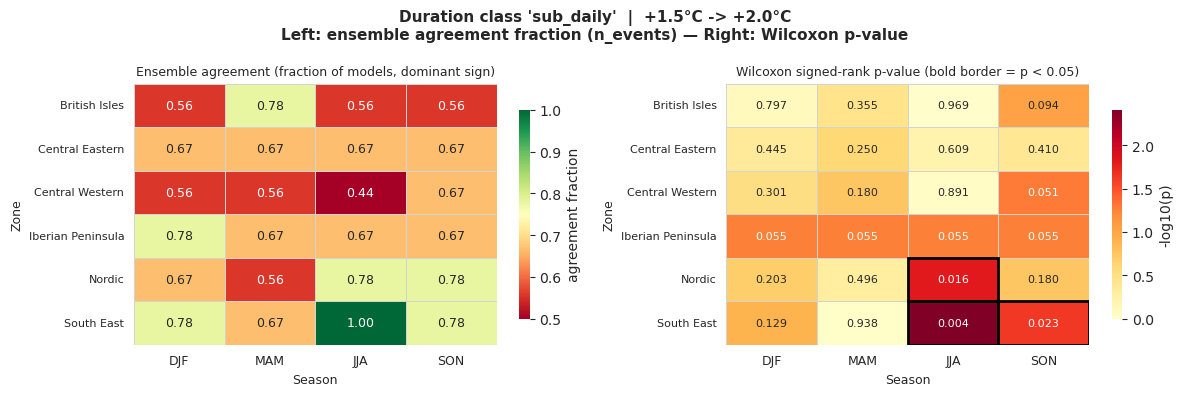

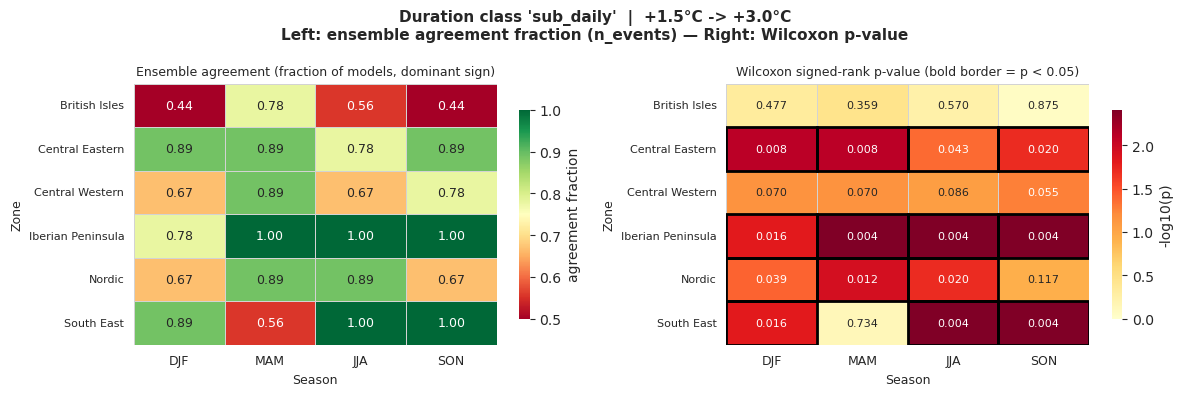

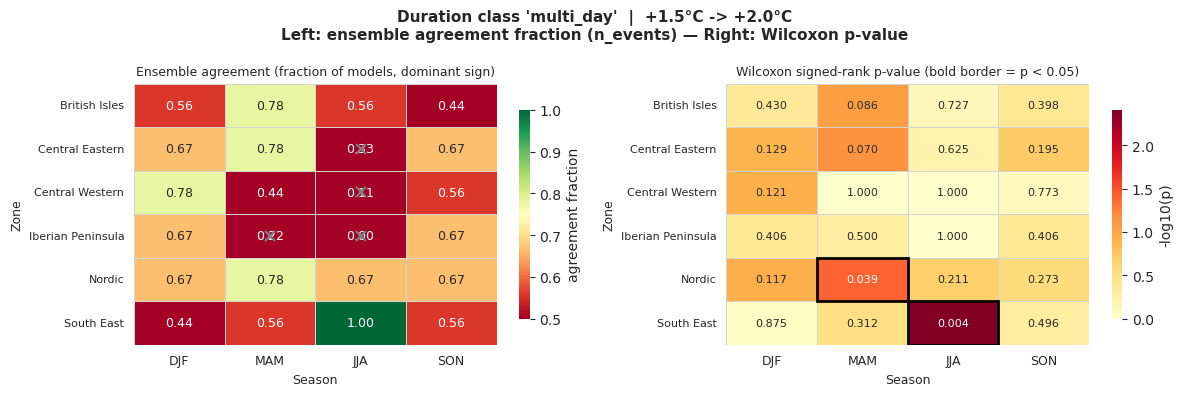

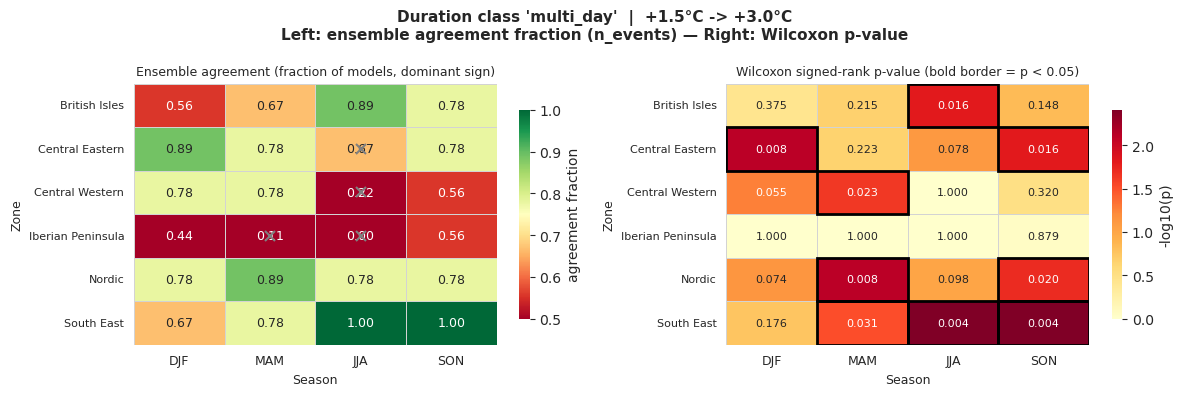

In [31]:
# C1b — Agreement-fraction + Wilcoxon p-value heatmaps per (duration class, comparison)
_zone_labels_c = [str(z) for z in zones]
for dc in DURATION_CLASS_ORDER:
    for comp in _comps_c:
        _sub = df_sig[(df_sig["duration_class"] == dc)
                      & (df_sig["comparison"] == f"{_ref_c}->{comp}")
                      & (df_sig["metric"] == "n_events")]
        if _sub.empty:
            continue
        agree_piv = _sub.pivot(index="zone", columns="season", values="agree_frac").reindex(index=_zone_labels_c, columns=season_order)
        sig_piv   = _sub.pivot(index="zone", columns="season", values="sig_05").reindex(index=_zone_labels_c, columns=season_order)
        pct_piv   = _sub.pivot(index="zone", columns="season", values="pct_change").reindex(index=_zone_labels_c, columns=season_order)

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        fig.suptitle(f"Duration class '{dc}'  |  {_ref_c} -> {comp}\n"
                     f"Left: ensemble agreement fraction (n_events) — Right: Wilcoxon p-value",
                     fontsize=11, fontweight="bold")
        # Agreement fraction
        ax = axes[0]
        sns.heatmap(agree_piv, ax=ax, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.5, vmax=1.0,
                    linewidths=0.5, linecolor="lightgray",
                    cbar_kws={"label": "agreement fraction", "shrink": 0.8}, annot_kws={"size": 9})
        for i, z in enumerate(agree_piv.index):
            for j, s in enumerate(agree_piv.columns):
                if not np.isfinite(pct_piv.loc[z, s]):
                    ax.plot(j + 0.5, i + 0.5, "x", color="gray", markersize=7, markeredgewidth=1.5, zorder=5)
        ax.set_title("Ensemble agreement (fraction of models, dominant sign)", fontsize=9)
        ax.set_yticklabels([z.replace("_", " ") for z in _zone_labels_c], rotation=0, fontsize=8)
        ax.set_xticklabels(season_order, rotation=0, fontsize=9)
        ax.set_xlabel("Season", fontsize=9); ax.set_ylabel("Zone", fontsize=9)
        # Wilcoxon p-value
        ax = axes[1]
        _sig_df = _sub.copy()
        _sig_df["neg_log10_p"] = -np.log10(_sig_df["p_wilcoxon"].clip(lower=1e-6))
        pval_piv = _sig_df.pivot(index="zone", columns="season", values="neg_log10_p").reindex(index=_zone_labels_c, columns=season_order)
        raw_piv  = _sig_df.pivot(index="zone", columns="season", values="p_wilcoxon").reindex(index=_zone_labels_c, columns=season_order)
        annot_p = raw_piv.copy().astype(object)
        for r in annot_p.index:
            for c in annot_p.columns:
                v = raw_piv.loc[r, c]
                annot_p.loc[r, c] = f"{v:.3f}" if np.isfinite(v) else "—"
        _finite = pval_piv.values[np.isfinite(pval_piv.values)]
        _vmax = max(float(_finite.max()) if _finite.size else 1.3, 1.3)
        sns.heatmap(pval_piv, ax=ax, annot=annot_p, fmt="", cmap="YlOrRd", vmin=0, vmax=_vmax,
                    linewidths=0.5, linecolor="lightgray",
                    cbar_kws={"label": "-log10(p)", "shrink": 0.8}, annot_kws={"size": 8})
        for i, z in enumerate(pval_piv.index):
            for j, s in enumerate(pval_piv.columns):
                v = sig_piv.loc[z, s]
                if pd.notna(v) and bool(v):
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=2, zorder=5))
        ax.set_title("Wilcoxon signed-rank p-value (bold border = p < 0.05)", fontsize=9)
        ax.set_yticklabels([z.replace("_", " ") for z in _zone_labels_c], rotation=0, fontsize=8)
        ax.set_xticklabels(season_order, rotation=0, fontsize=9)
        ax.set_xlabel("Season", fontsize=9); ax.set_ylabel("Zone", fontsize=9)
        plt.tight_layout(); plt.show()

## Seasonal driver-anomaly box-strips (from N2)

Signed mean anomaly per event (GWh) for each driver, by season and warming level.
Demand anomaly positive (excess); generation/flexibility negative (shortfall).

**Key result —** events coincide with demand excess plus PV/wind shortfall — winter events demand- and wind-dominated, summer events PV-dominated — and the signed anomaly magnitudes grow with warming.

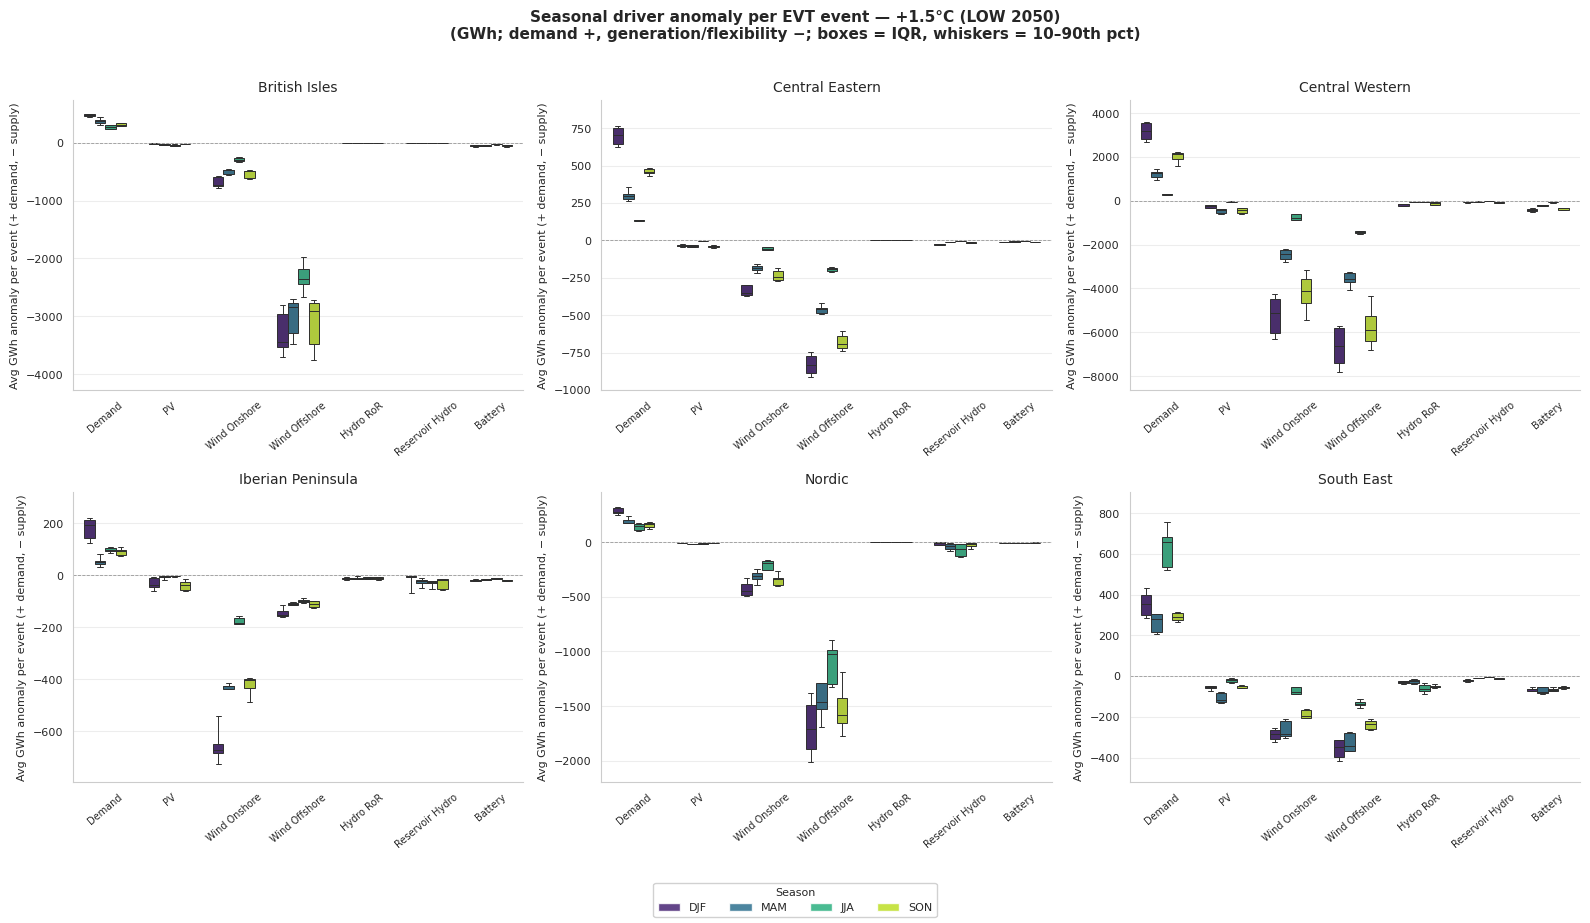

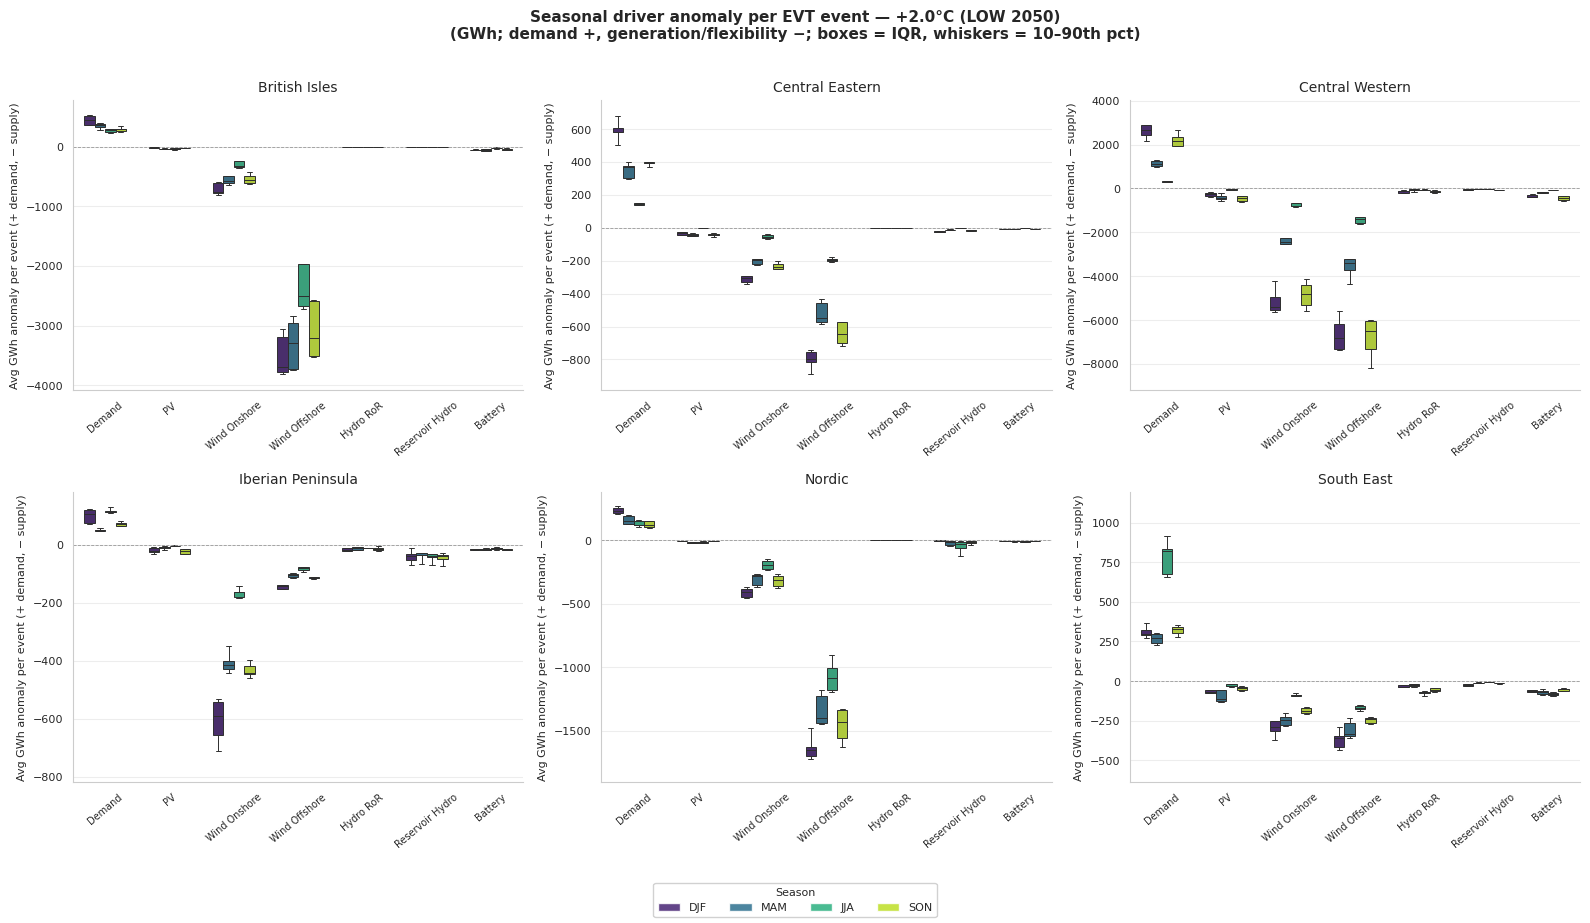

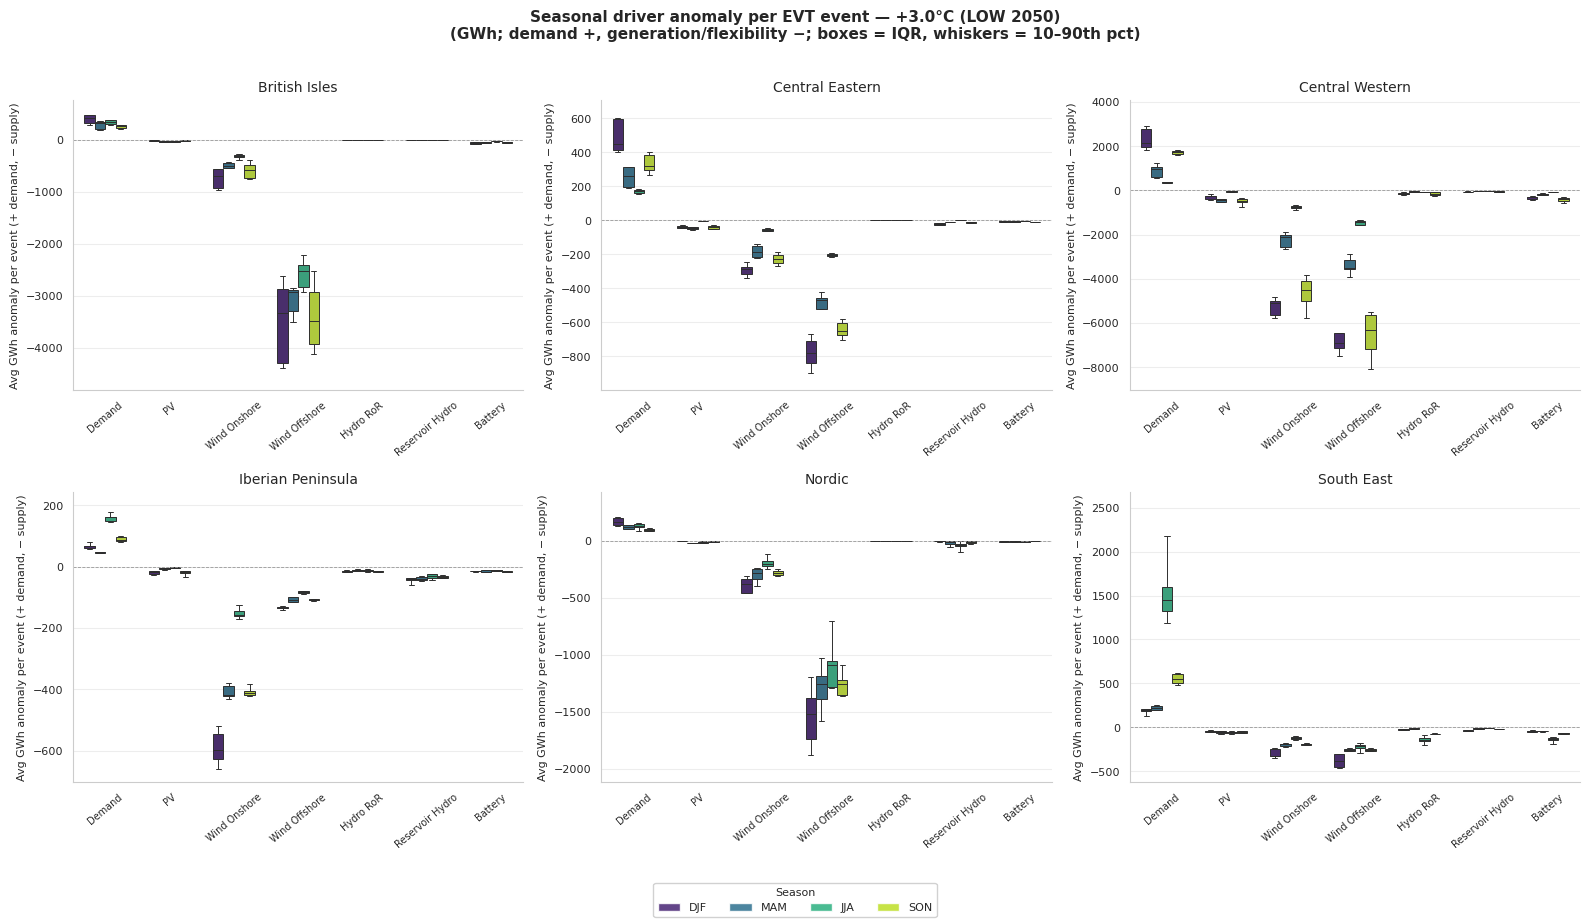

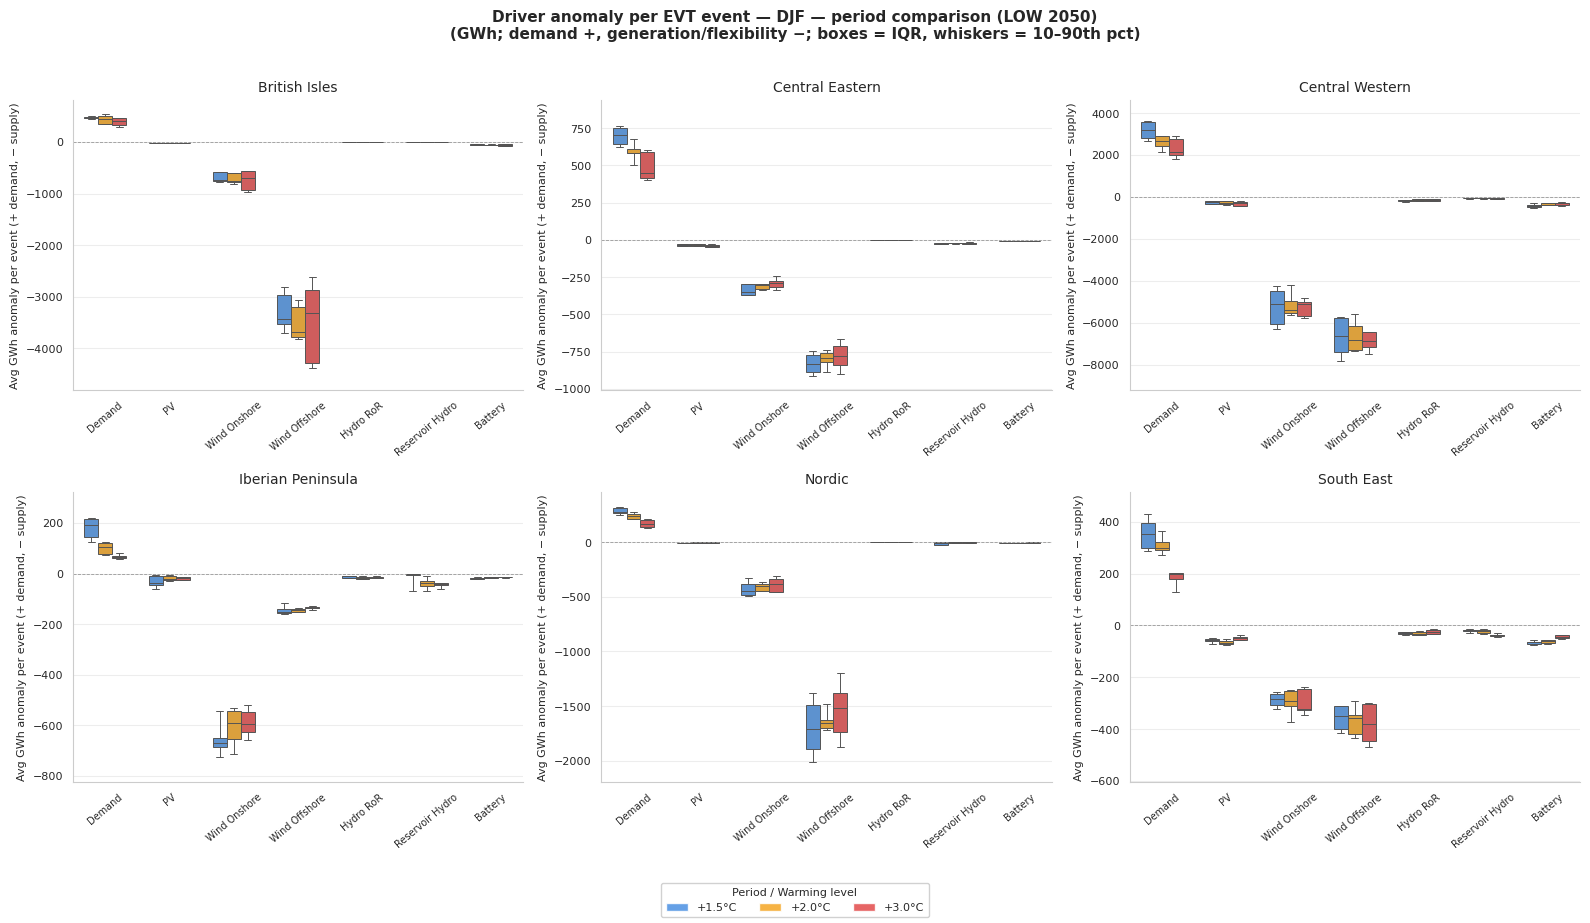

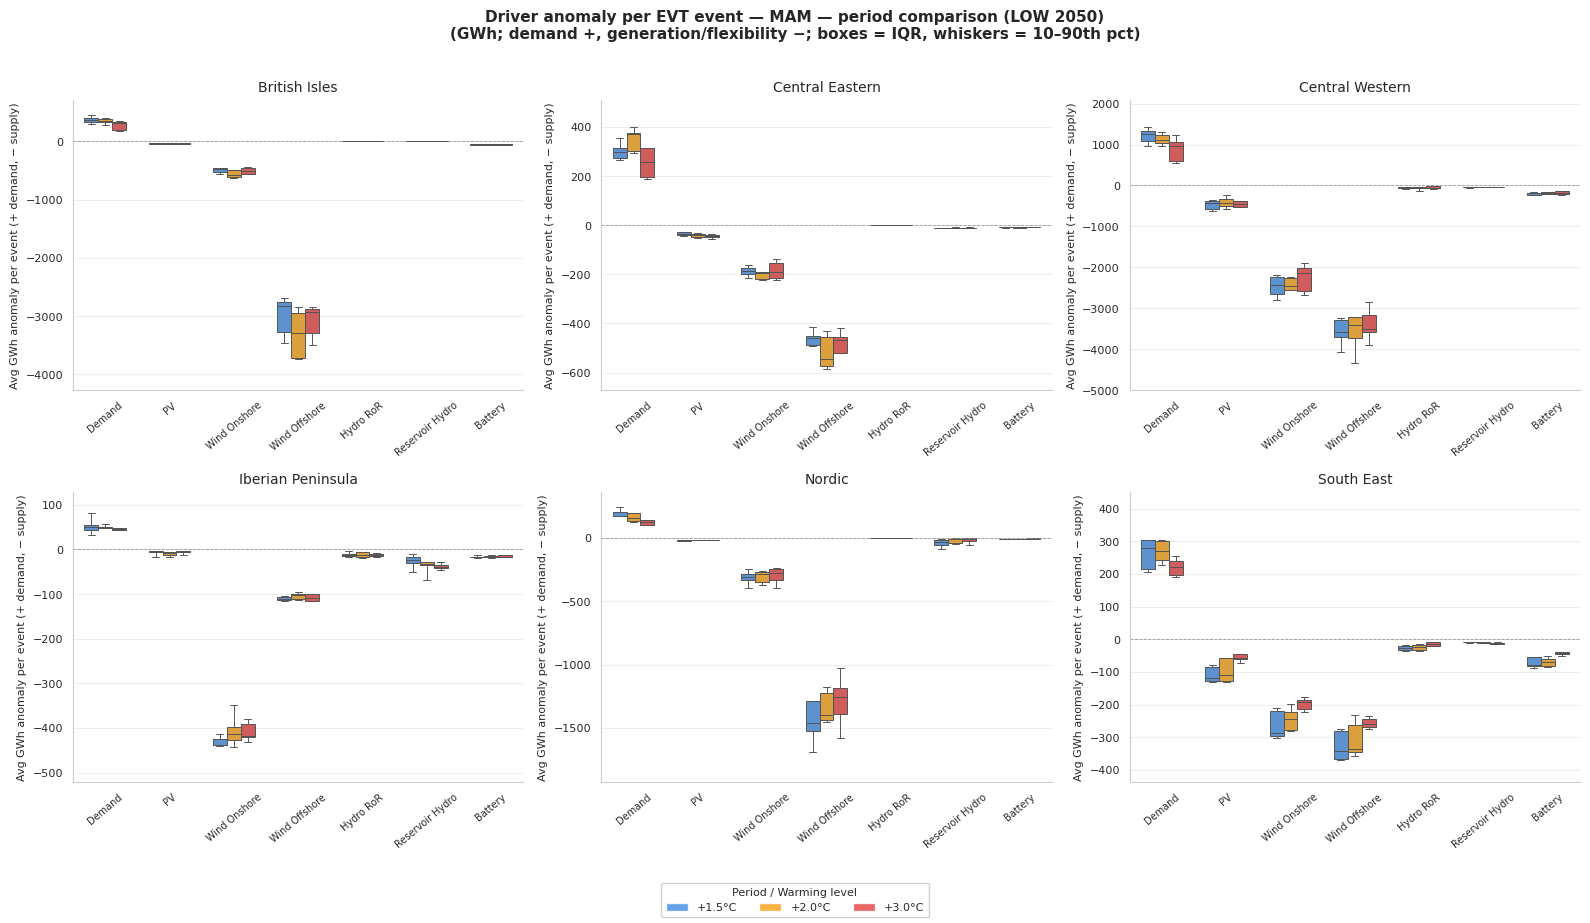

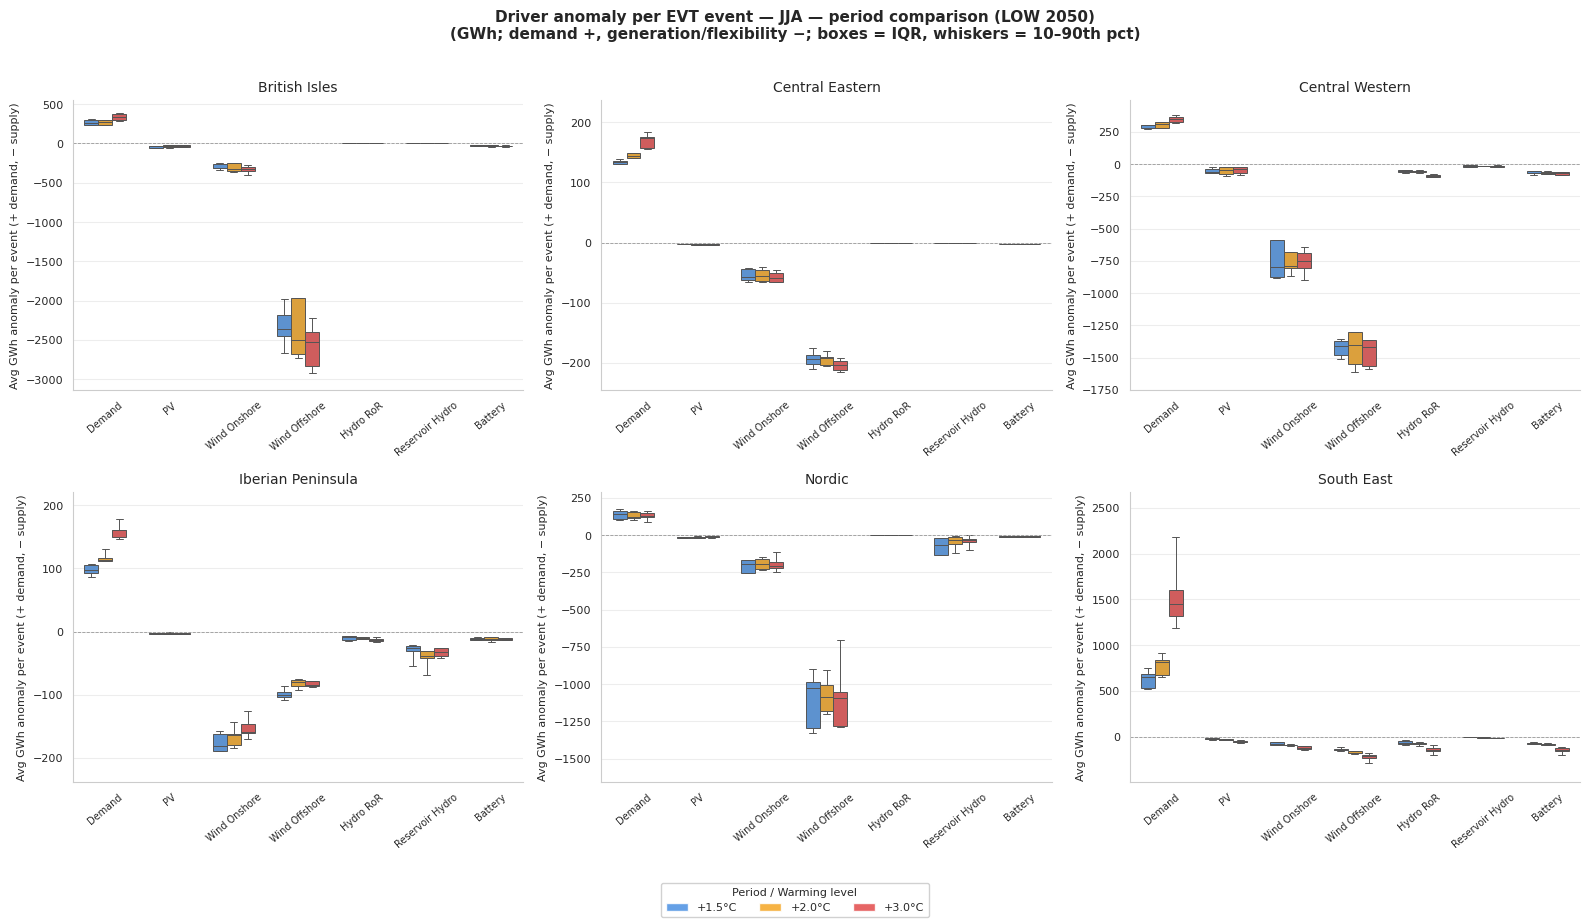

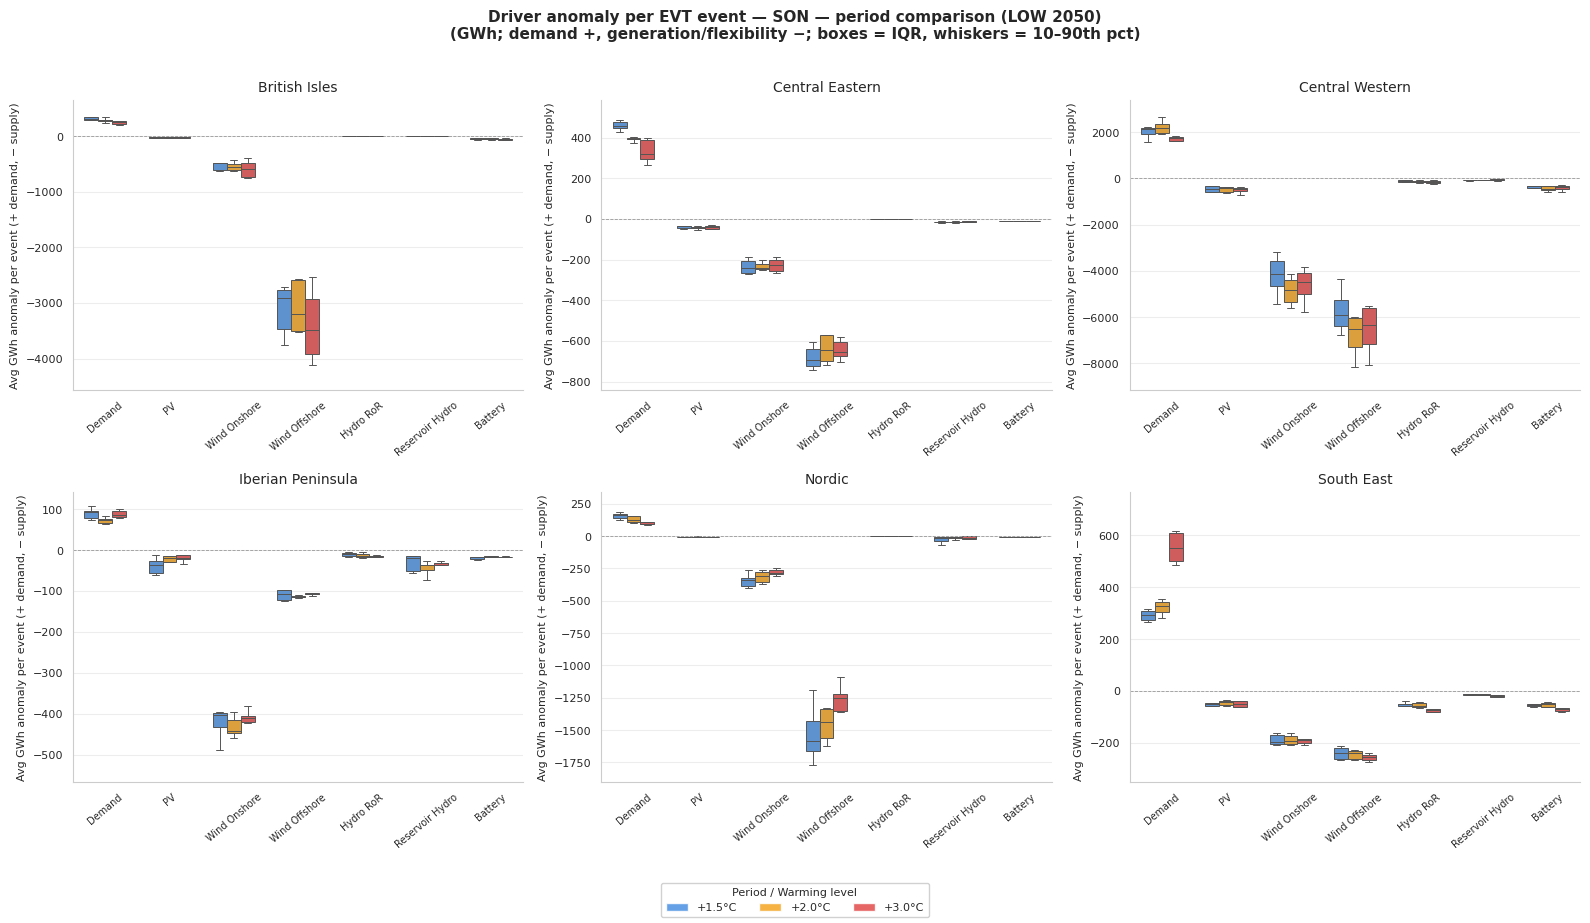

In [32]:
plot_seasonal_component_anomaly_distributions(
    df_seasonal_evt, zones=zones, season_order=season_order, period_defs=period_defs,
    component_cols=anomaly_component_cols, component_palette=driver_palette,
    period_palette=period_colors, supply_scenario=supply_scenario, supply_year=supply_year,
)

## Driver-anomaly box-strips by duration class (annual)

Signed mean anomaly per event (GWh) for each driver, split by duration class —
the mechanistic counterpart to the duration dichotomy. Expectation: `sub_daily`
events are dominated by demand excess + PV shortfall (diurnal/solar regime),
while `multi_day` events are dominated by wind drought + reservoir drawdown
(synoptic regime). Annual scale is used (not seasonal) so the sparse multi_day
cells retain interpretable event counts; degenerate zones (`DEGENERATE_ZONES`)
should be read with care.

**Key result —** the regimes separate mechanistically — sub_daily events are demand- and wind/battery-driven (diurnal/solar), while multi_day events are wind-drought- and pv-driven (synoptic).

── Driver anomaly (annual): 'sub_daily' events  (rows=162)


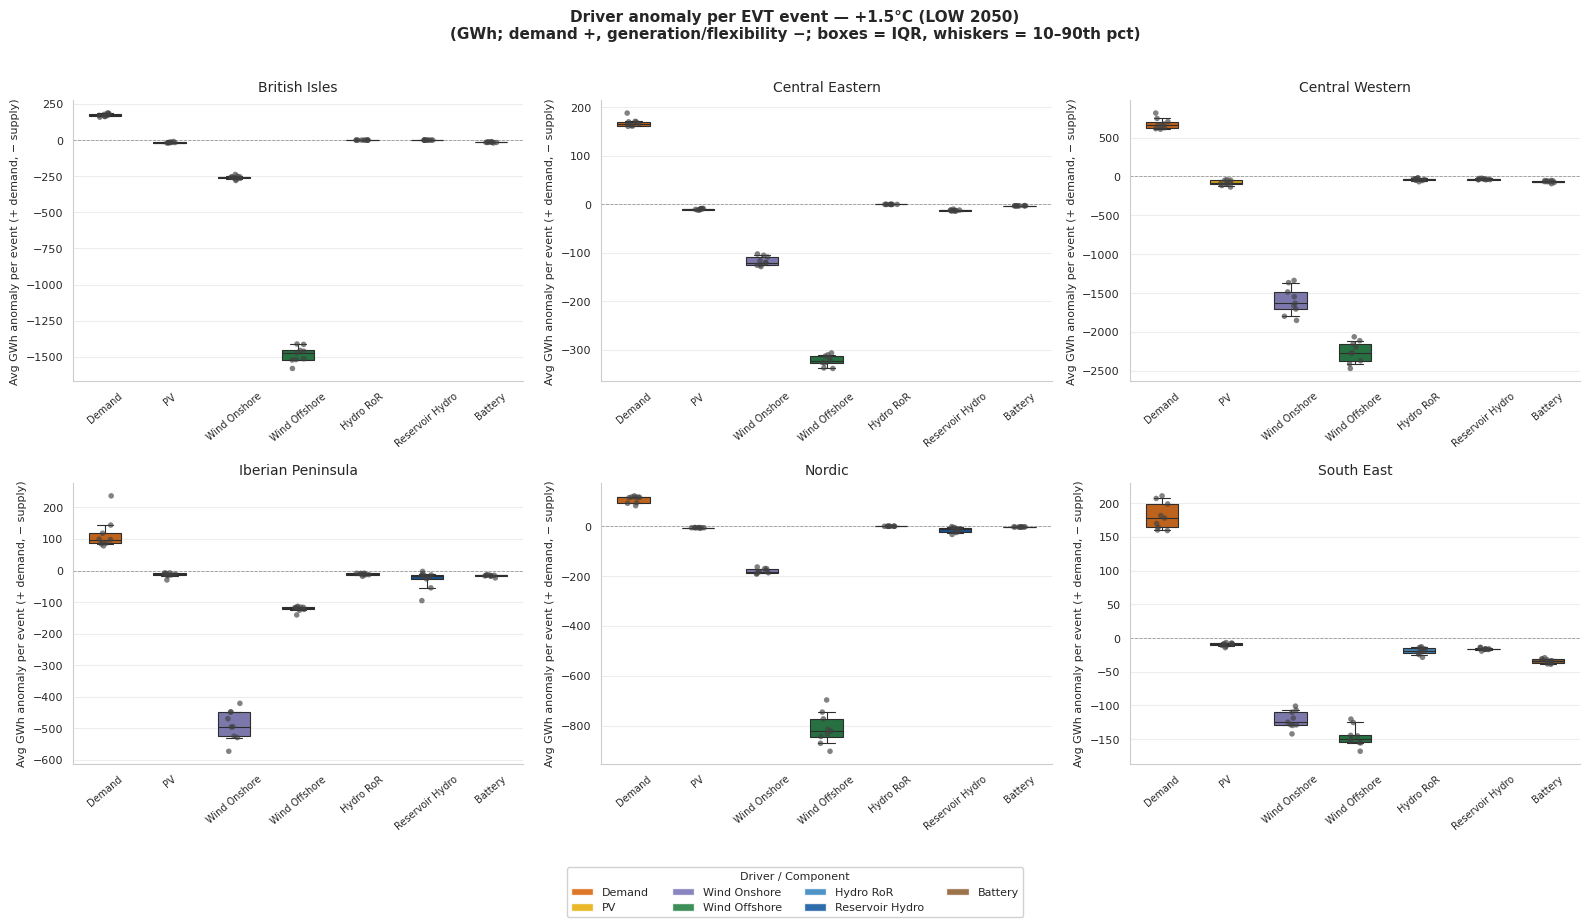

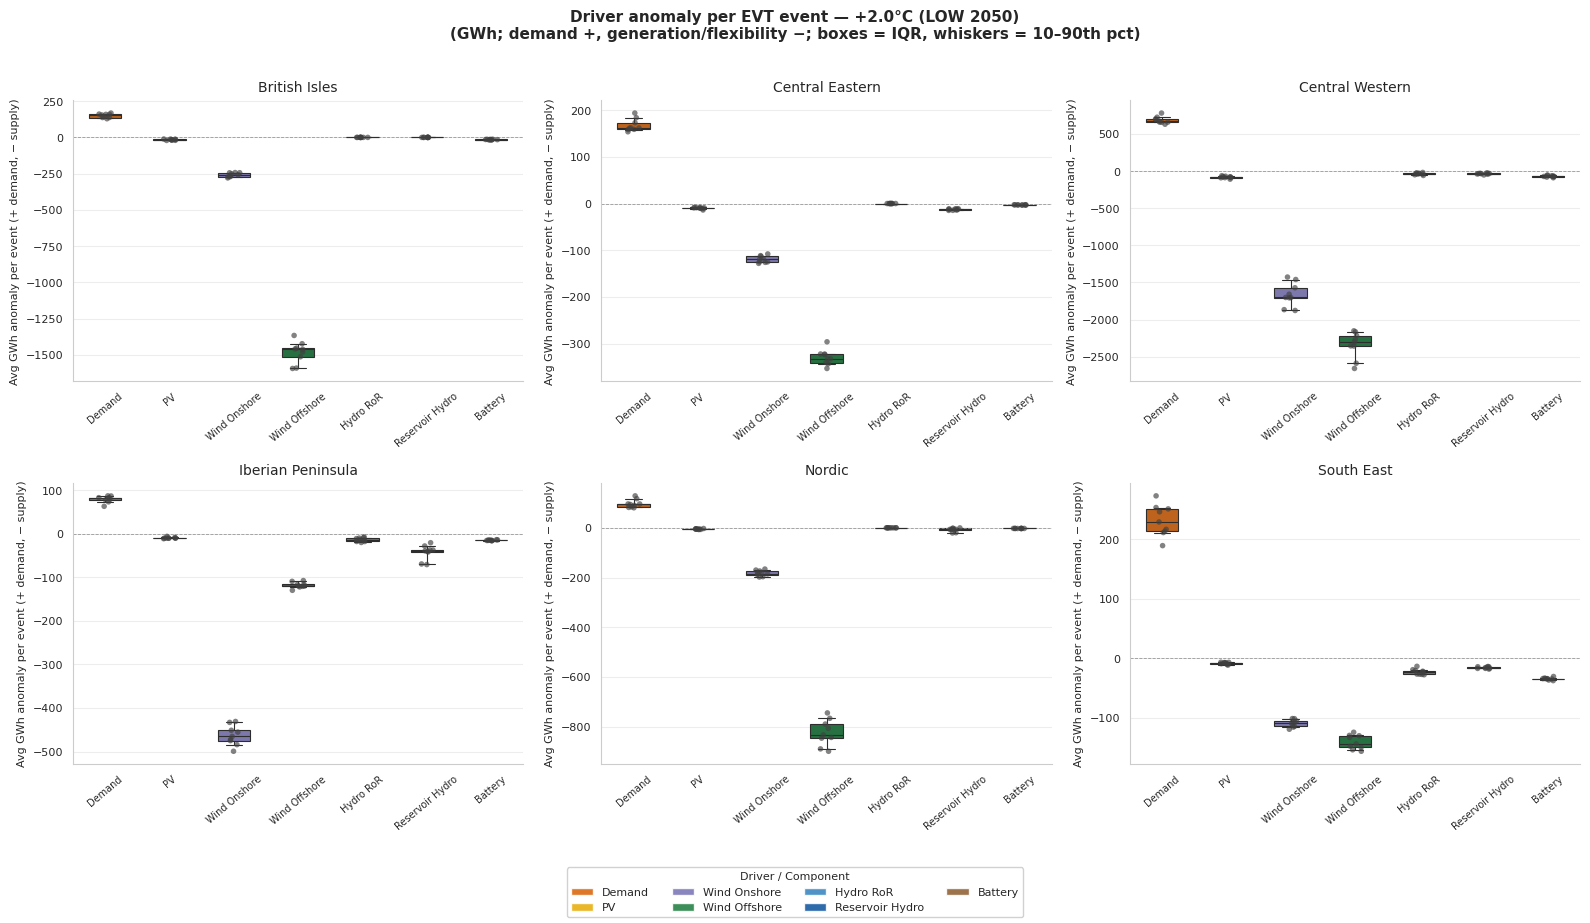

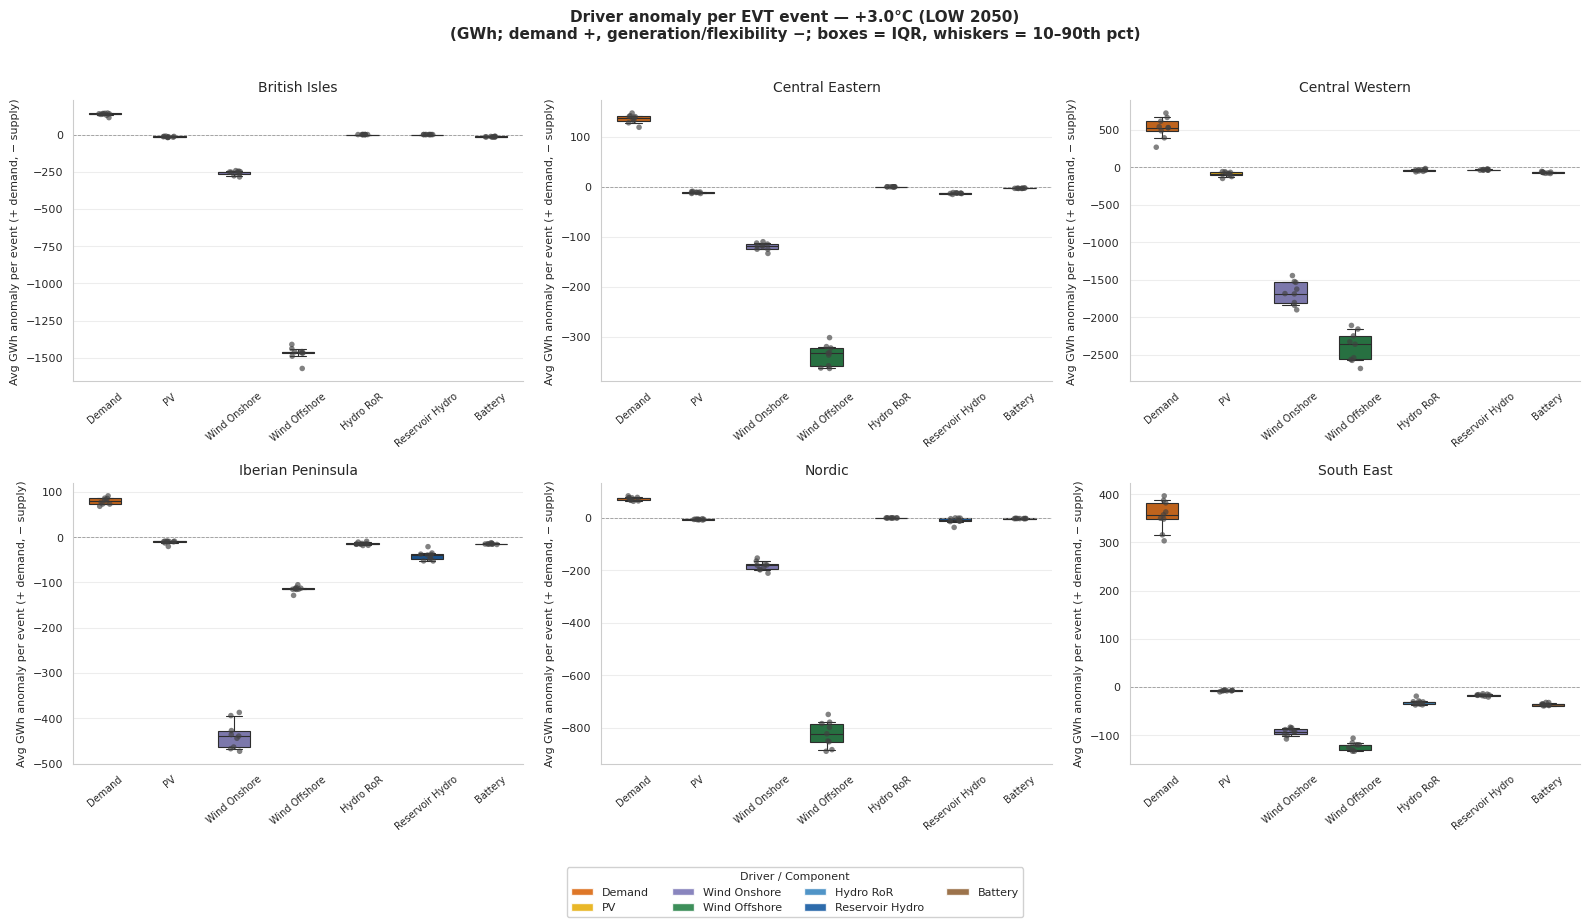

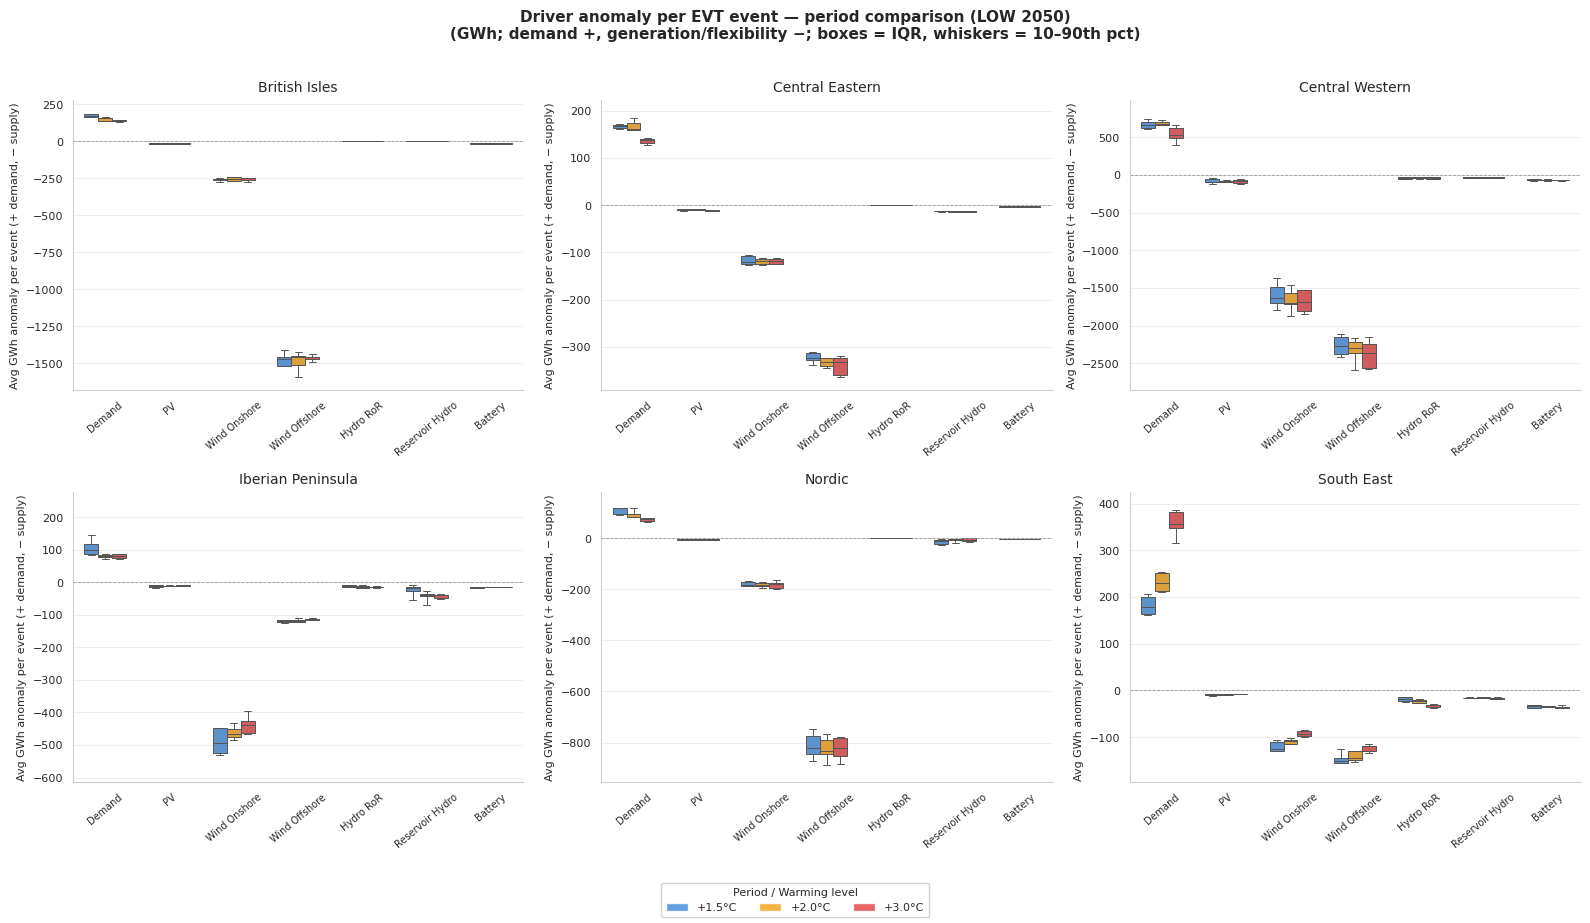

── Driver anomaly (annual): 'multi_day' events  (rows=162)


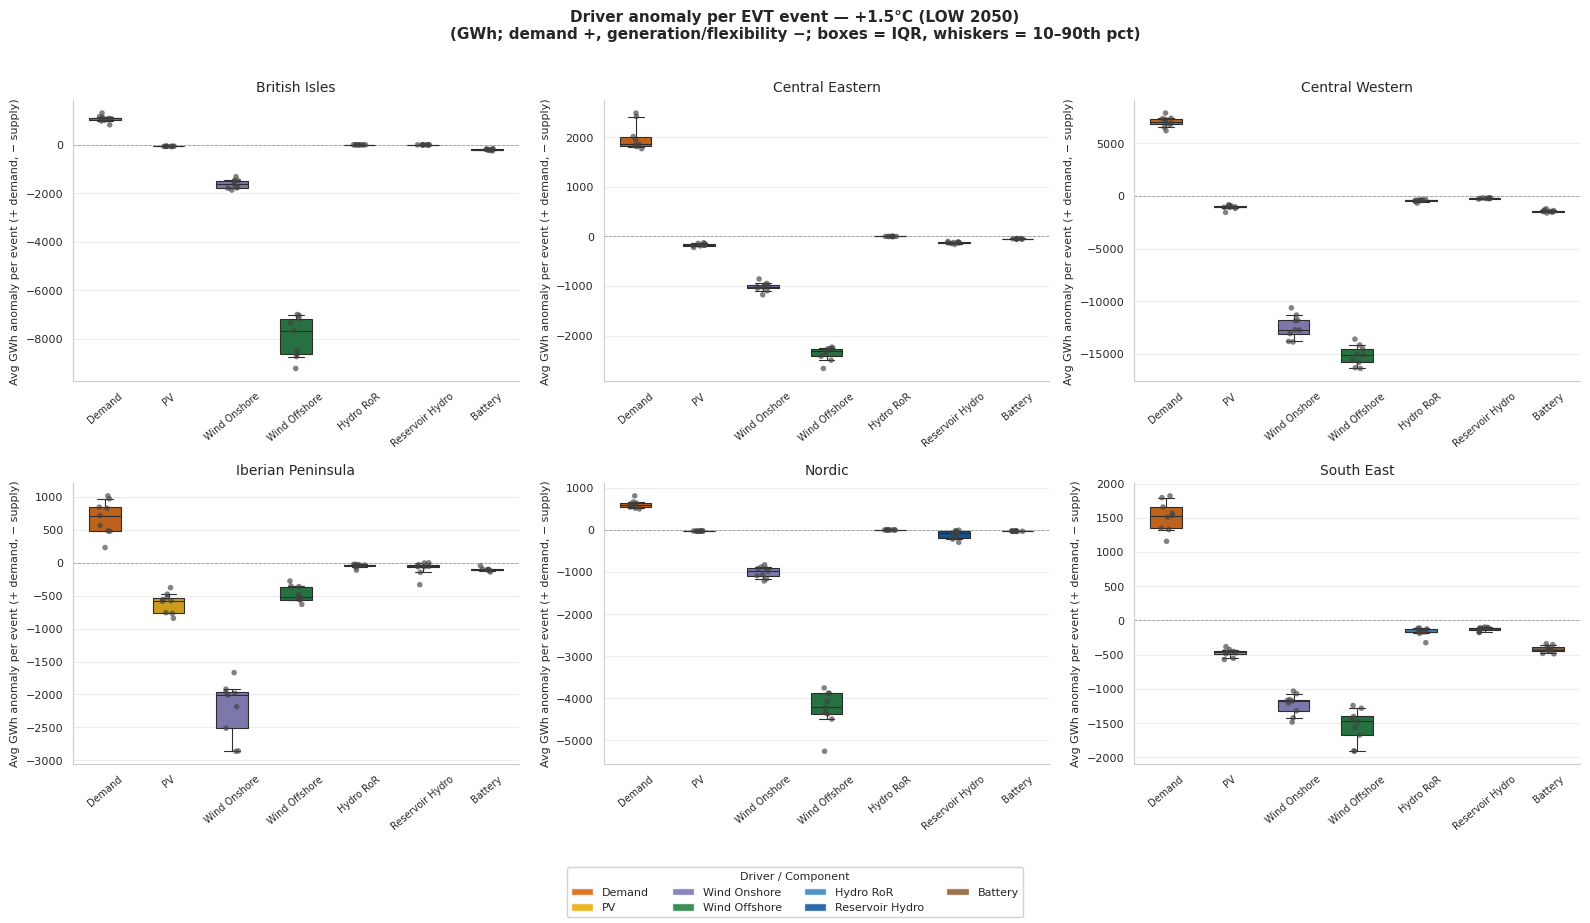

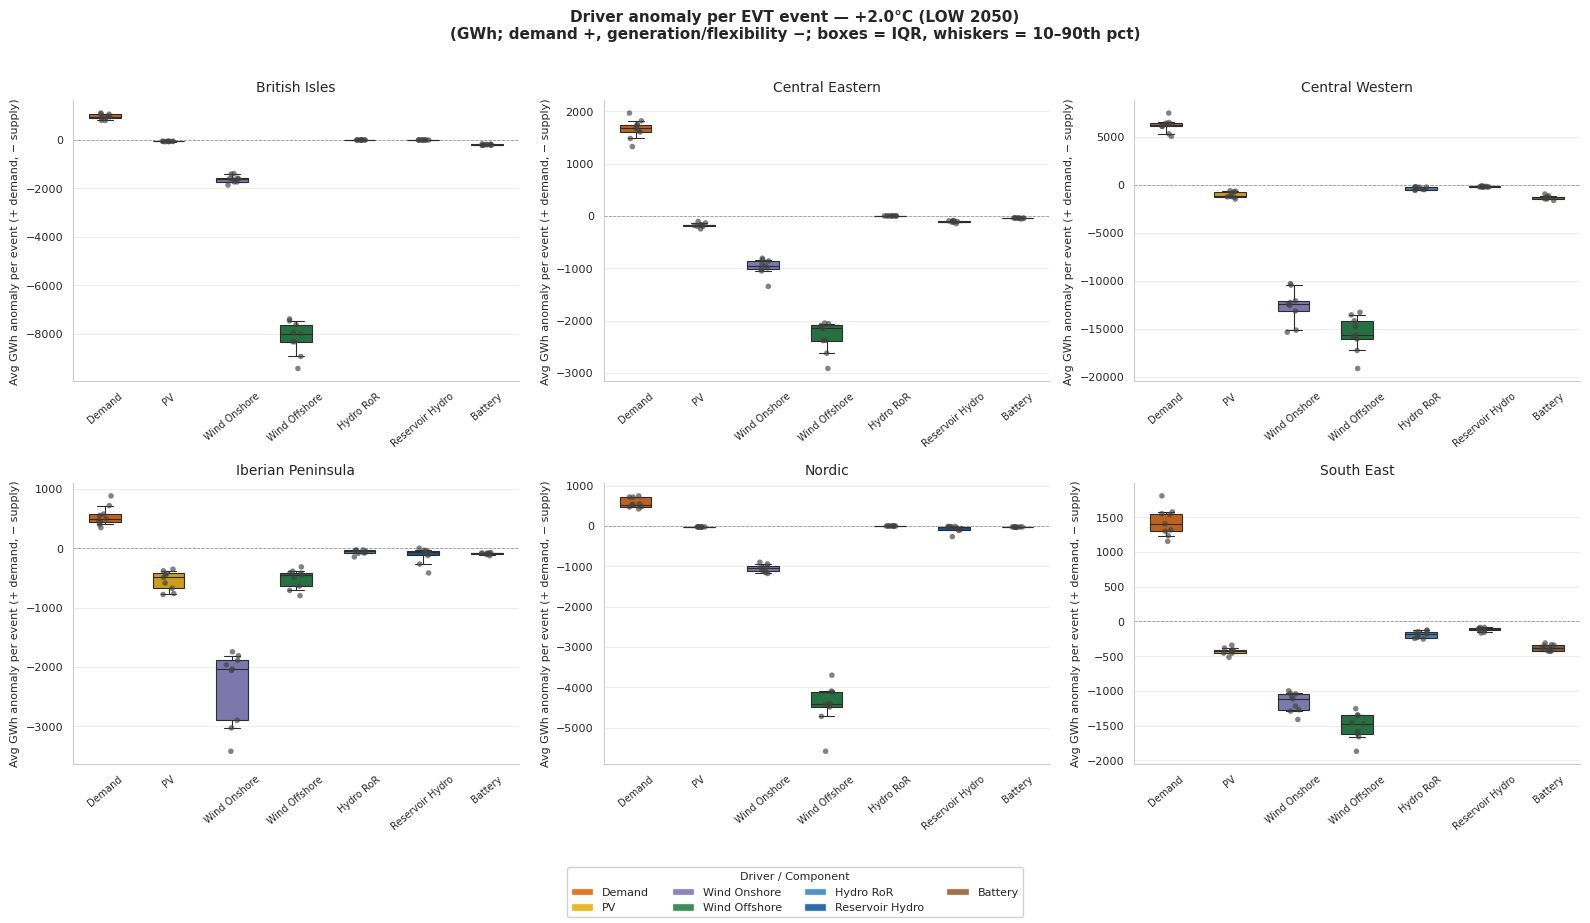

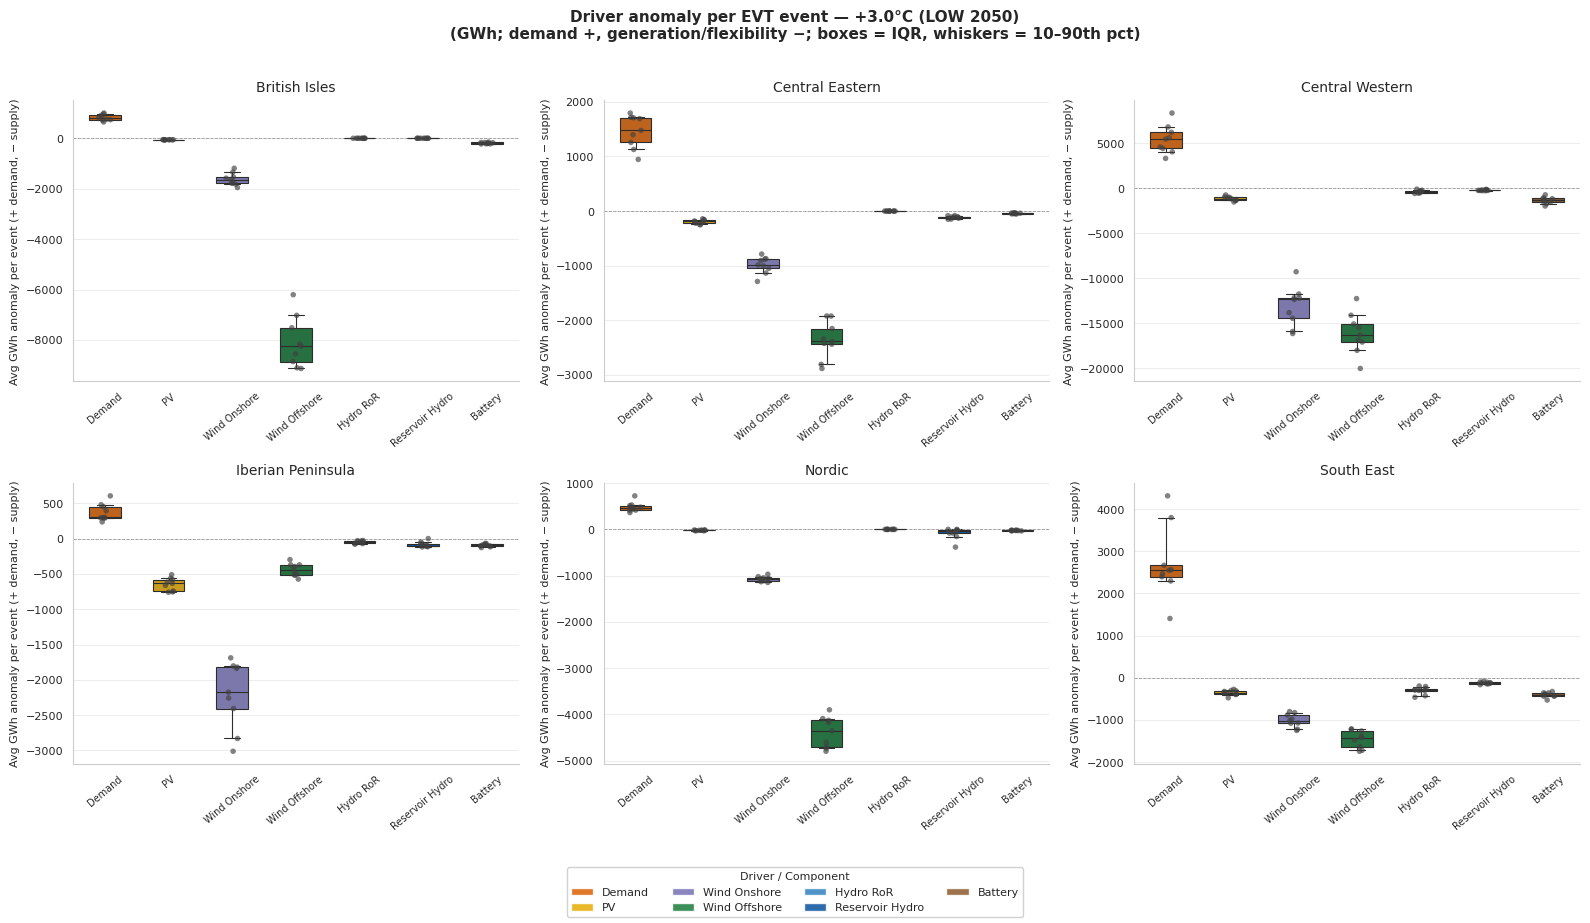

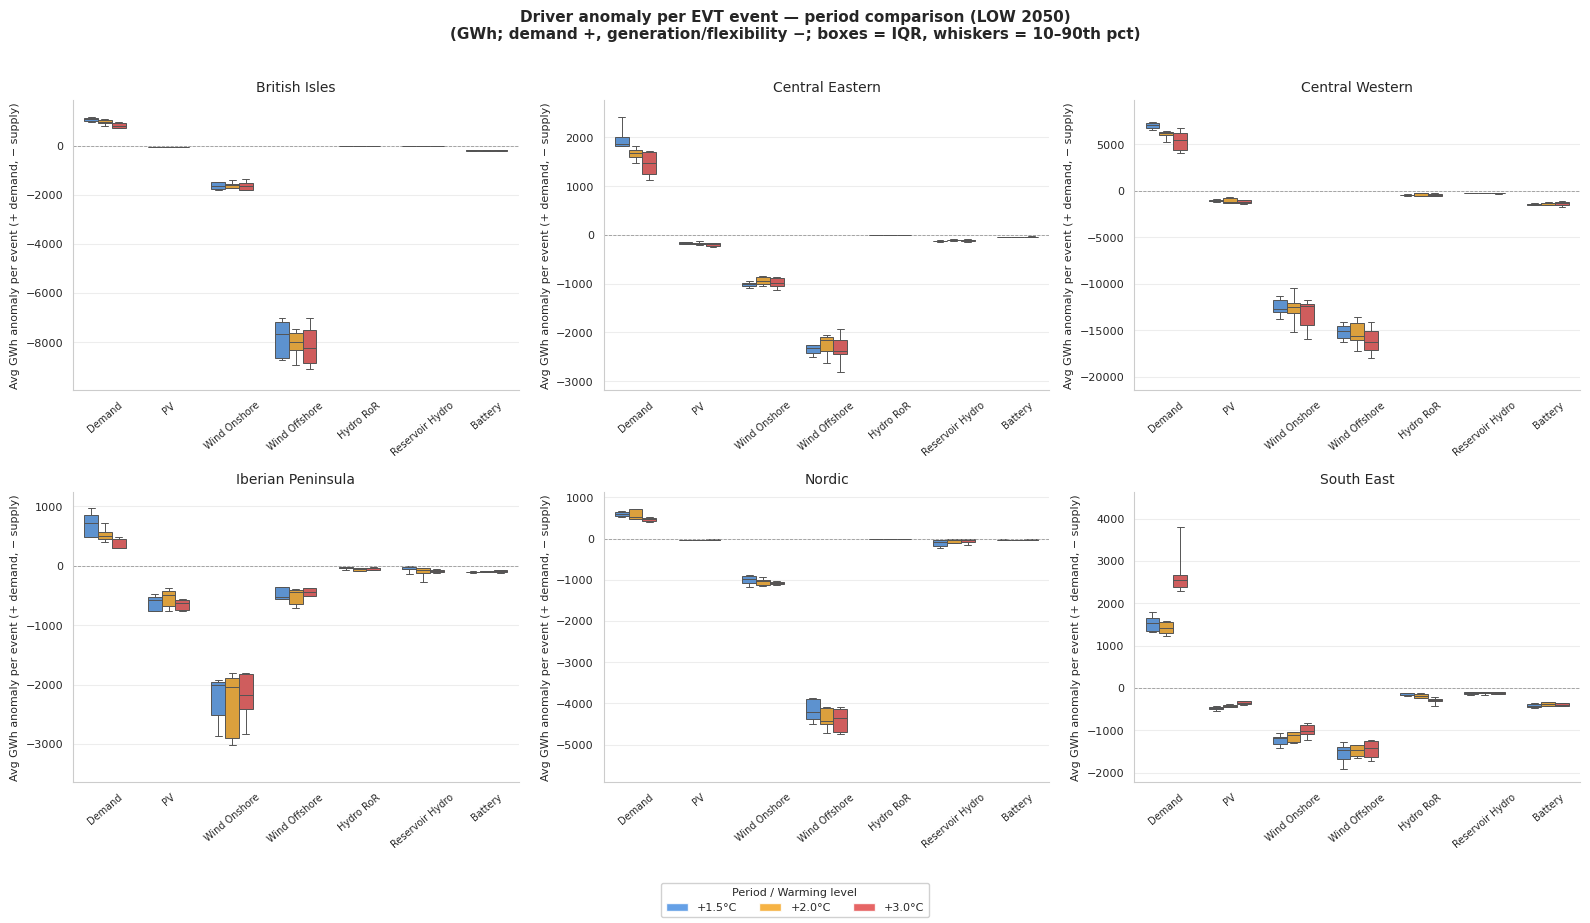

In [33]:
for dc in DURATION_CLASS_ORDER:
    df_dc = df_annual[(df_annual["duration_class"] == dc) & (df_annual["n_events"] > 0)].copy()
    if df_dc.empty:
        print(f"  [skip {dc}: no events]")
        continue
    print(f"── Driver anomaly (annual): '{dc}' events  (rows={len(df_dc)})")
    plot_component_anomaly_distributions(
        df_dc, zones=zones, period_defs=period_defs,
        component_cols=anomaly_component_cols, component_palette=driver_palette,
        period_palette=period_colors, supply_scenario=supply_scenario, supply_year=supply_year,
    )

## Duration-class characteristics — `sub_daily` vs `multi_day`

Beyond frequency, this section characterises the two duration regimes: **duration**,
**per-event & annual severity**, **driver attribution** (dominant driver in the table),
the **event-count vs energy-severity concentration** (are multi_day events a small share
of events but a large share of the energy at risk?), **flexibility attenuation** by class,
and **seasonal timing**. All boxplots use the global `SPREAD` convention (box = IQR,
whiskers = `SPREAD`).

In [34]:
# Attenuation stratified by duration class (annual scale) + characteristics frame + helper
df_flex_dc = compute_flexibility_attenuation_metrics(
    _cache_rl, _cache_comp, active_thresholds, period_defs, models, zones,
    method=EVENT_DETECTION_METHOD, duration_bins=DURATION_BINS,
)

df_char = df_annual.merge(
    df_flex_dc[["model", "period", "zone", "duration_class",
                "combined_attenuation_pct",
                "battery_attenuation_share_pct", "reservoir_attenuation_share_pct"]],
    on=["model", "period", "zone", "duration_class"], how="left",
)

def _box_by_duration(df, metric, ylabel, title):
    """One figure PER duration class; x = region, one box per warming level
    (period-coloured); box = IQR, whiskers = SPREAD."""
    _whis = list(spread_qpair("minmax"))
    _pn   = list(period_defs.keys())
    _np   = len(_pn)
    _zl   = [str(z) for z in zones]
    _zx   = np.arange(len(_zl))
    _bw   = 0.7 / _np
    for dc in DURATION_CLASS_ORDER:
        df_dc = df[df["duration_class"] == dc]
        fig, ax = plt.subplots(figsize=(14, 5))
        for pi, p in enumerate(_pn):
            color = period_colors[p]
            offs  = _zx + (pi - _np / 2 + 0.5) * _bw
            data, pos = [], []
            for zi, z in enumerate(_zl):
                v = df_dc[(df_dc["period"] == p) & (df_dc["zone"] == z)][metric].dropna().values
                if v.size:
                    data.append(v); pos.append(offs[zi])
            if data:
                ax.boxplot(data, positions=pos, widths=_bw * 0.85, patch_artist=True,
                           whis=_whis, showfliers=False,
                           medianprops=dict(color="white", linewidth=1.6),
                           boxprops=dict(facecolor=color, alpha=0.85, linewidth=0.6),
                           whiskerprops=dict(color=color, linewidth=0.9, linestyle="--"),
                           capprops=dict(color=color, linewidth=0.9))
            ax.plot([], [], color=color, linewidth=5, alpha=0.85, label=p)
        ax.set_title(f"{title} — '{dc}' events\n(box = IQR, whiskers = {SPREAD_LABEL[SPREAD]})",
                     fontsize=12, fontweight="bold")
        ax.set_xticks(_zx)
        ax.set_xticklabels([z.replace("_", " ") for z in _zl], rotation=20, ha="right")
        ax.set_ylabel(ylabel, fontsize=10)
        ax.grid(axis="y", linewidth=0.4)
        ax.legend(title="Warming level", ncol=_np, fontsize=9)
        sns.despine(ax=ax)
        plt.tight_layout(); plt.show()

print(f"df_flex_dc: {df_flex_dc.shape[0]} rows | df_char: {df_char.shape[0]} rows")

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np.nan
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/extremes_analysis.py:865: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(arr)) if arr.size else np

df_flex_dc: 324 rows | df_char: 324 rows


In [35]:
# Regime summary table PER REGION (ensemble median over models, per zone).
# Concentration = share of events / severity across duration classes within each (zone, period).
_rows = []
for z in [str(zz) for zz in zones]:
    for p in period_names:
        for dc in DURATION_CLASS_ORDER:
            sub = df_char[(df_char["zone"] == z) & (df_char["period"] == p) & (df_char["duration_class"] == dc)]
            shares = {name: sub[col].median() for name, col in driver_cols.items() if col in sub}
            shares = {k: v for k, v in shares.items() if np.isfinite(v)}
            dom = max(shares, key=shares.get) if shares else "—"
            _rows.append(dict(
                zone=z, period=p, duration_class=dc,
                events_per_yr=sub["freq_per_year"].median(),
                n_events=sub["n_events"].median(),
                mean_duration_h=sub["avg_duration_h"].median(),
                mean_severity_gwh=sub["avg_severity_gwh"].median(),
                annual_severity_gwh=sub["total_annual_severity_gwh"].median(),
                combined_atten_pct=sub["combined_attenuation_pct"].median(),
                dominant_driver=dom,
            ))
regime_tbl = pd.DataFrame(_rows)

def _share(x):
    tot = x.sum()
    return x / tot * 100 if tot > 0 else x * 0.0

regime_tbl["pct_of_events"]   = regime_tbl.groupby(["zone", "period"])["n_events"].transform(_share)
regime_tbl["pct_of_severity"] = regime_tbl.groupby(["zone", "period"])["annual_severity_gwh"].transform(_share)

_disp = (regime_tbl.set_index(["zone", "period", "duration_class"])
         [["events_per_yr", "mean_duration_h", "mean_severity_gwh", "annual_severity_gwh",
           "pct_of_events", "pct_of_severity", "combined_atten_pct", "dominant_driver"]]
         .round(1))
print("Duration-class characteristics per region (ensemble median over models):")
print(_disp.to_string())


Duration-class characteristics per region (ensemble median over models):
                                         events_per_yr  mean_duration_h  mean_severity_gwh  annual_severity_gwh  pct_of_events  pct_of_severity  combined_atten_pct dominant_driver
zone              period duration_class                                                                                                                                            
British_Isles     +1.5°C sub_daily                10.8             12.0              128.5               1326.3           75.2             23.0                71.3   Wind Offshore
                         multi_day                 3.6             62.3             1287.5               4437.1           24.8             77.0                38.8   Wind Offshore
                  +2.0°C sub_daily                10.9             11.6              121.2               1336.2           74.4             20.3                72.6   Wind Offshore
                         mu

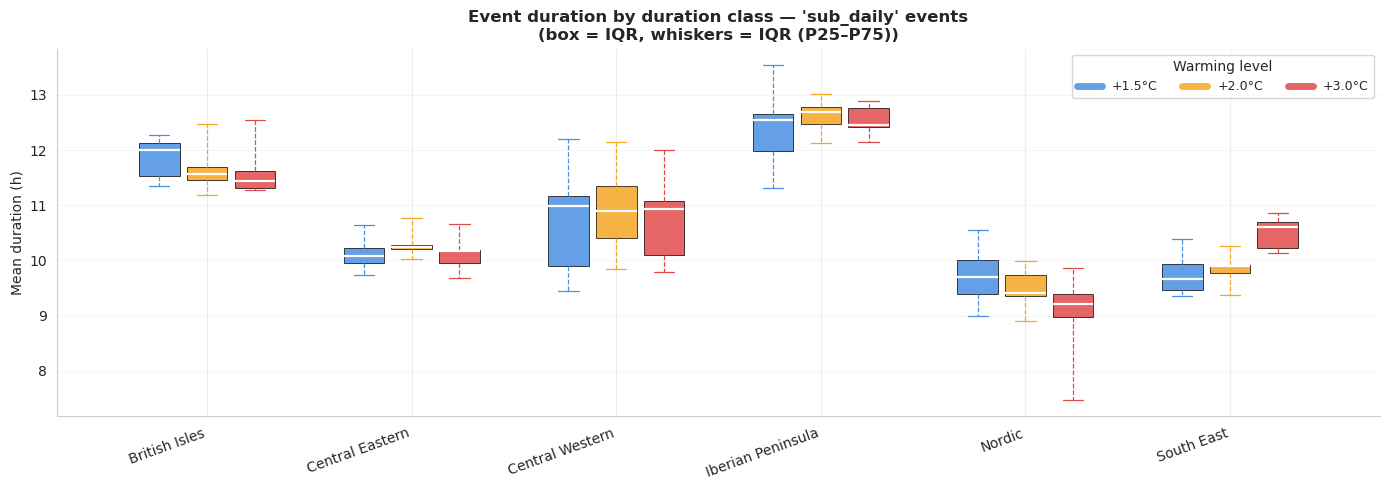

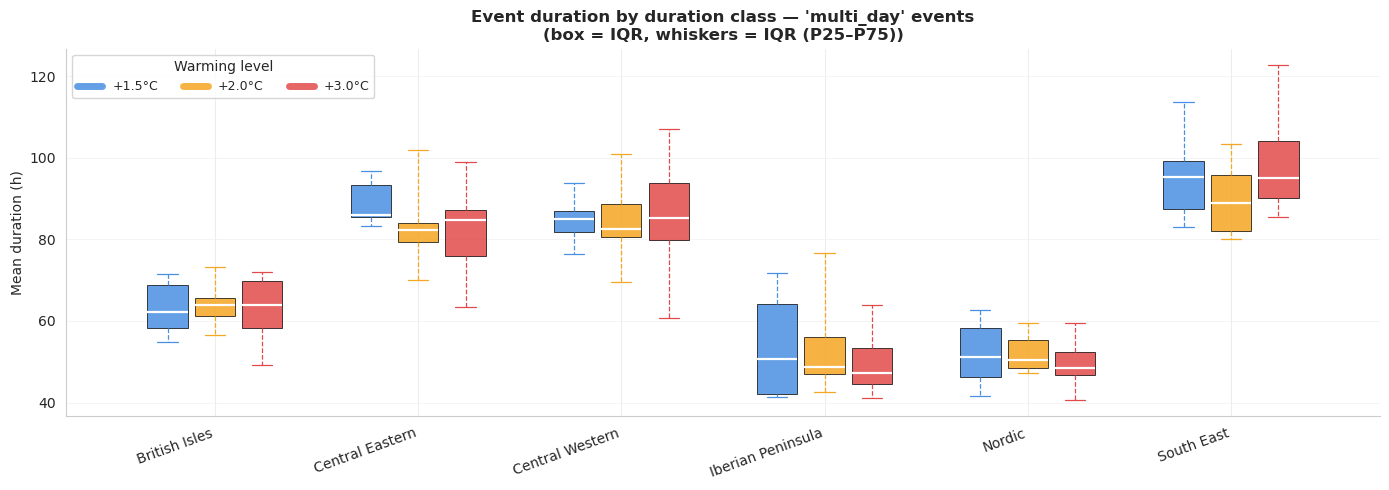

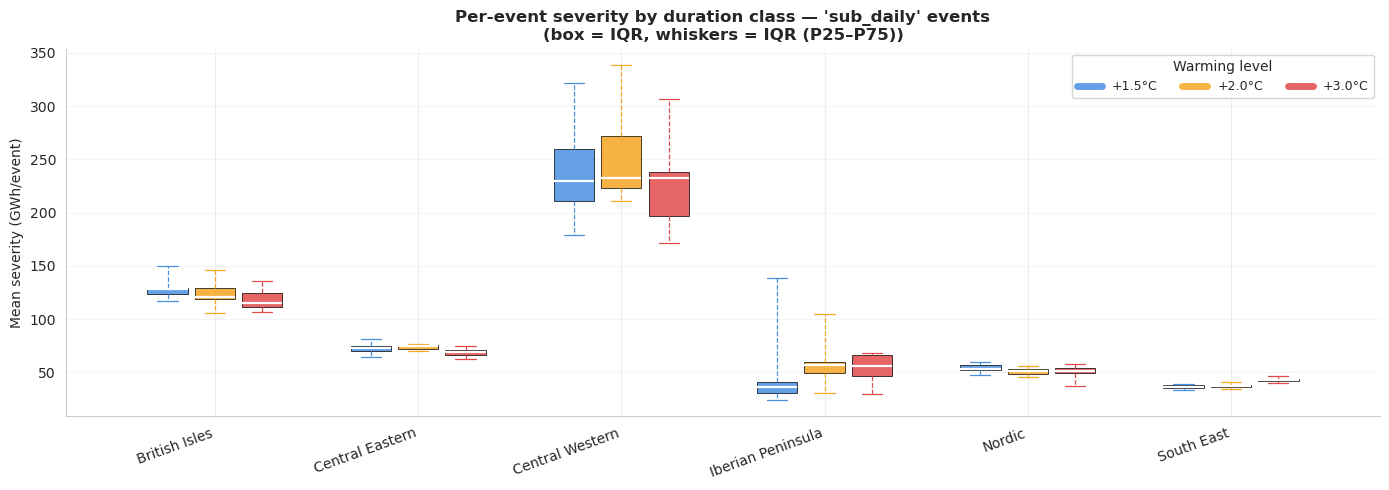

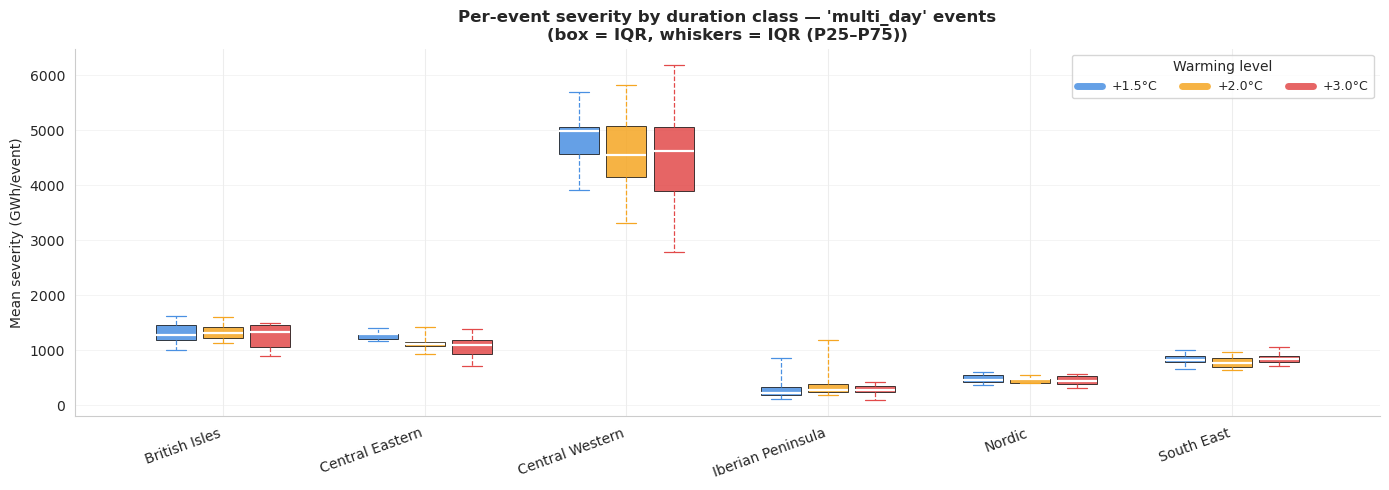

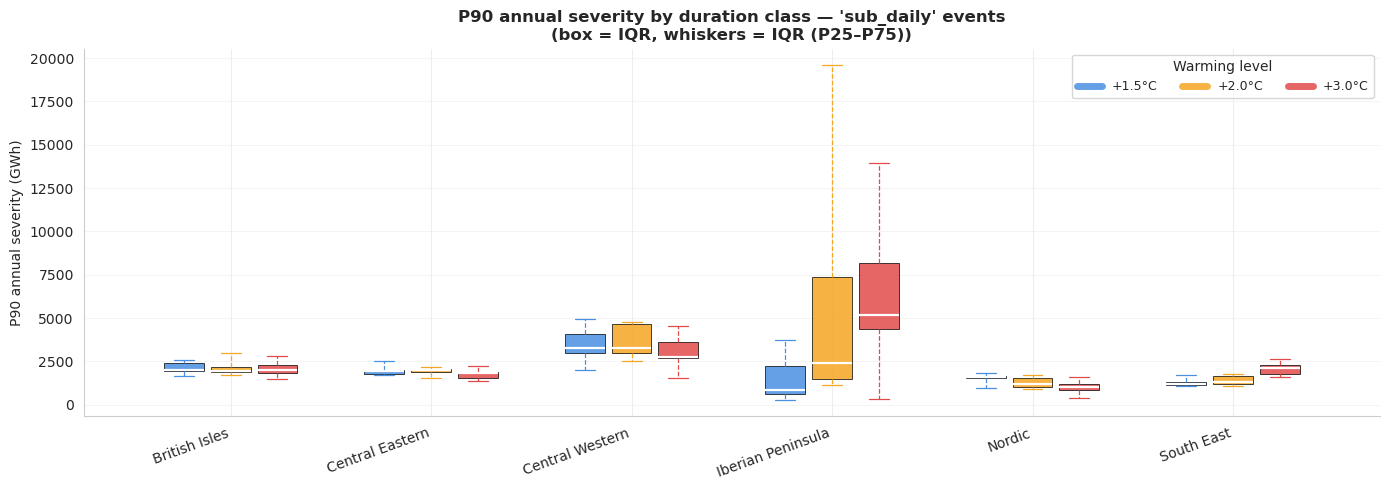

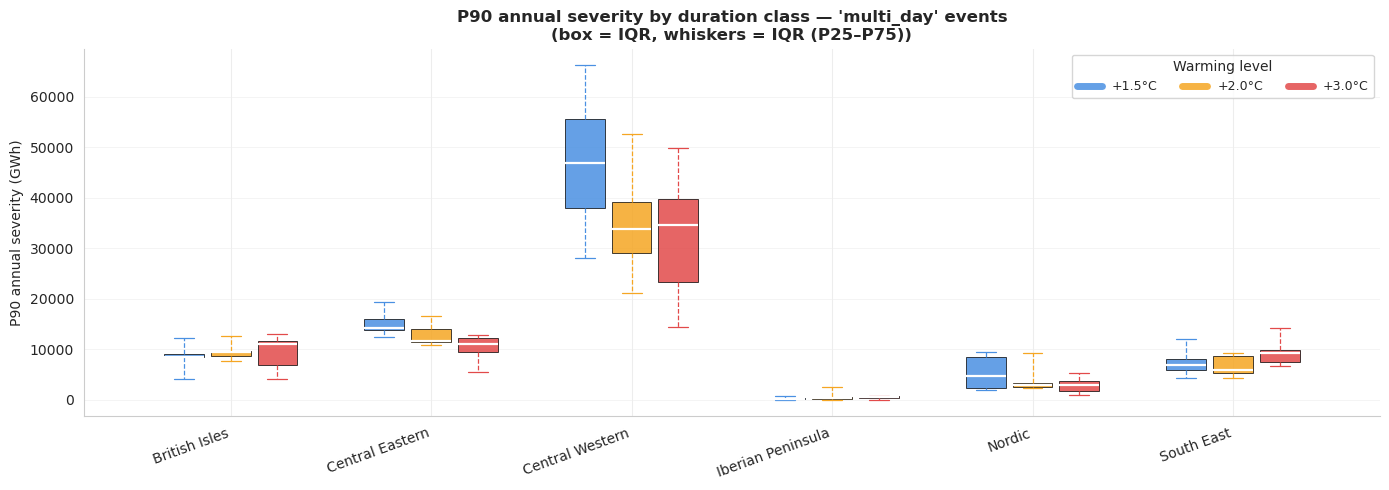

In [36]:
# Duration and severity by duration class
_box_by_duration(df_annual, "avg_duration_h",          "Mean duration (h)",         "Event duration by duration class")
_box_by_duration(df_annual, "avg_severity_gwh",        "Mean severity (GWh/event)", "Per-event severity by duration class")
_box_by_duration(df_annual, "p90_annual_severity_gwh", "P90 annual severity (GWh)", "P90 annual severity by duration class")

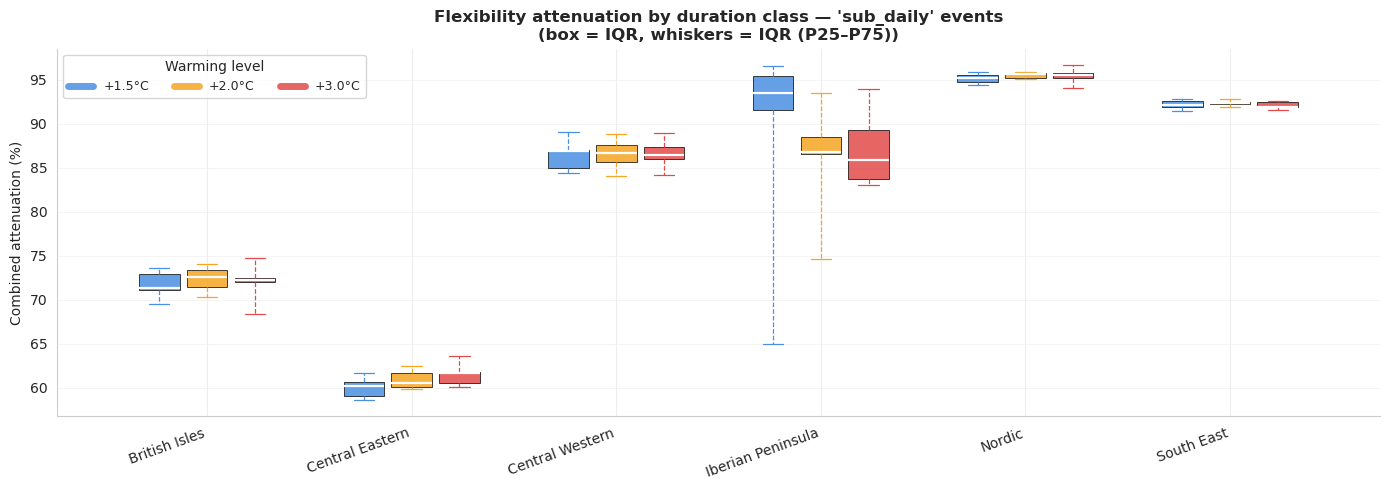

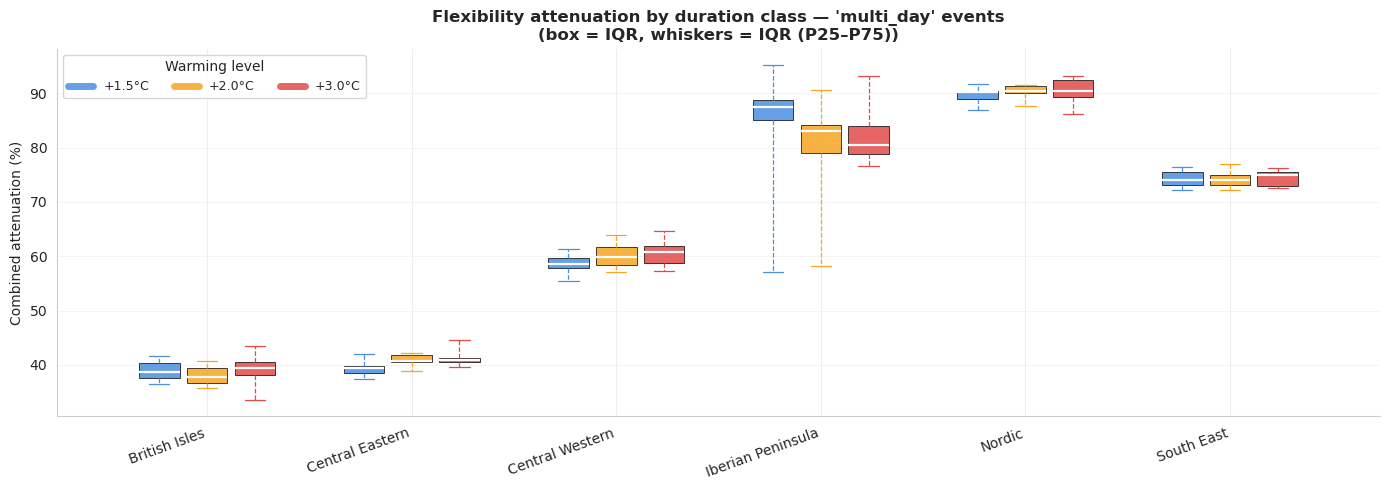

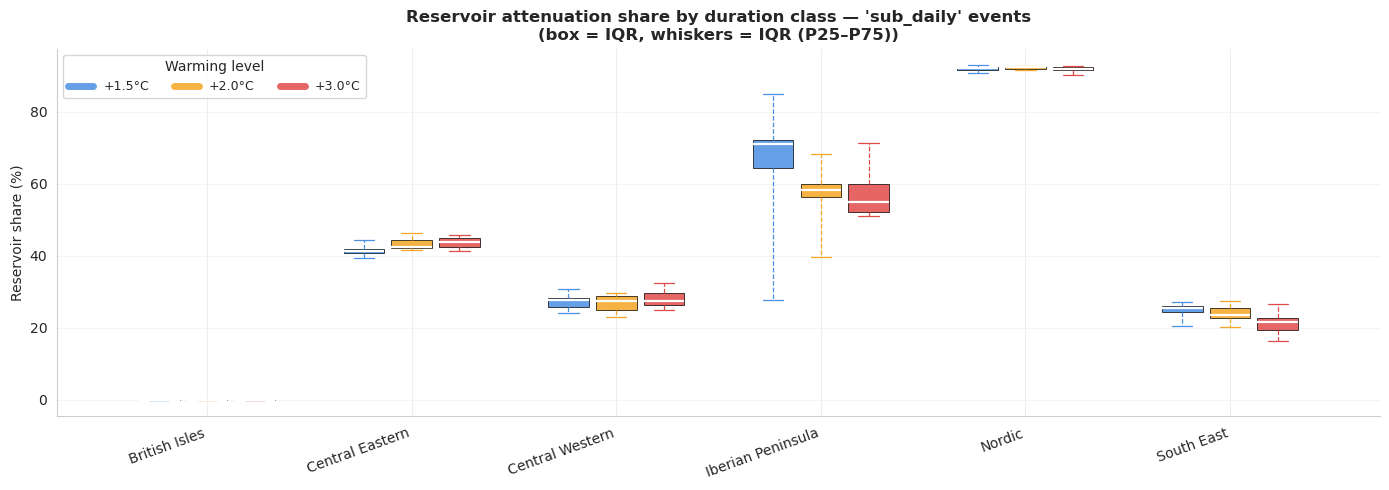

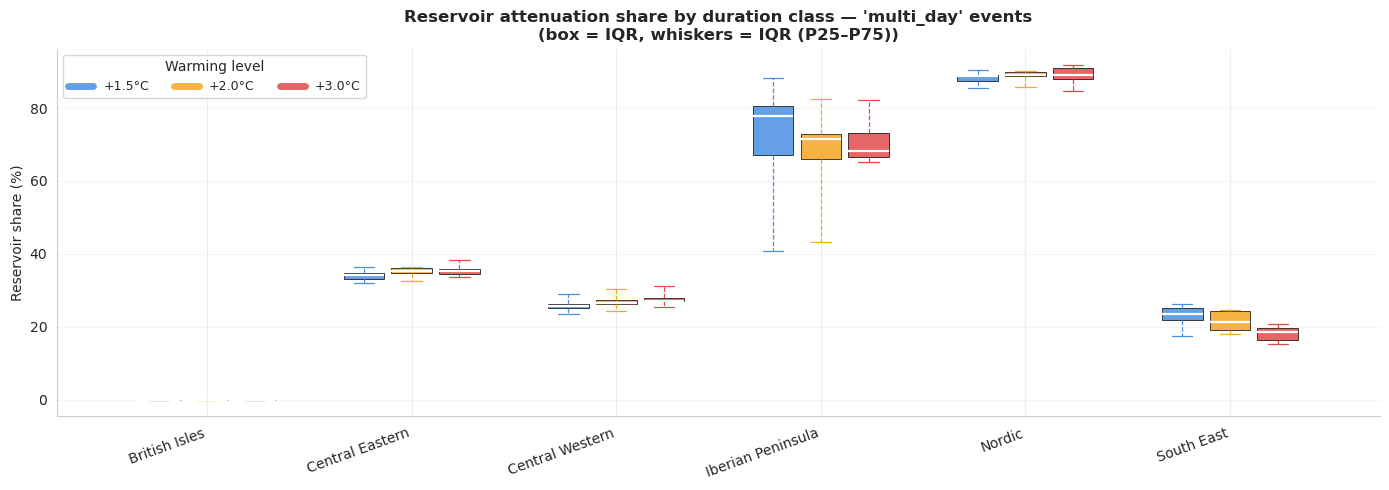

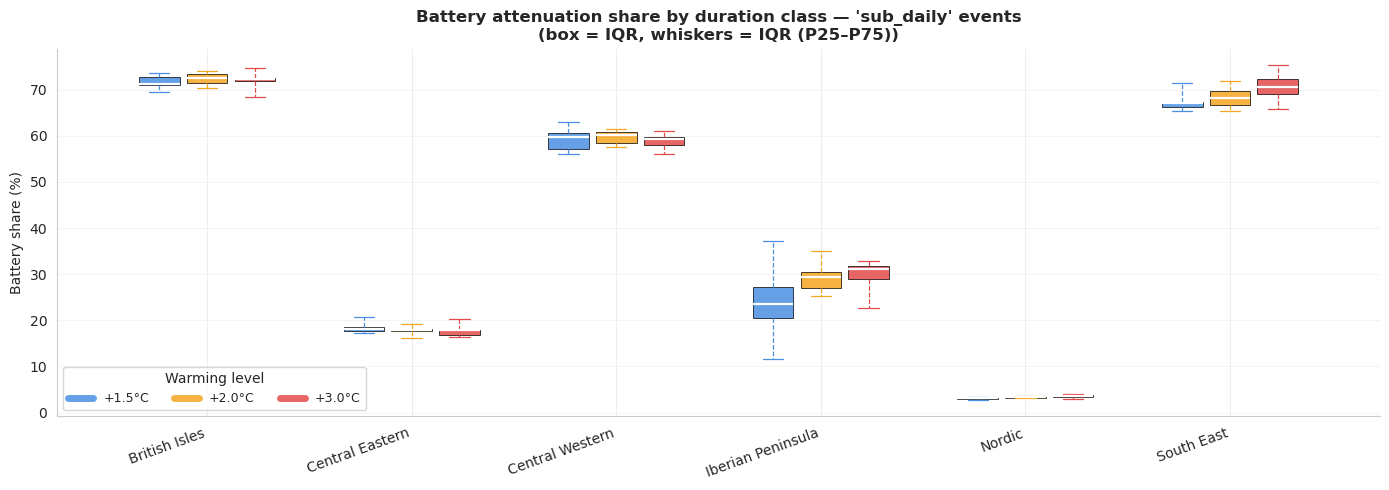

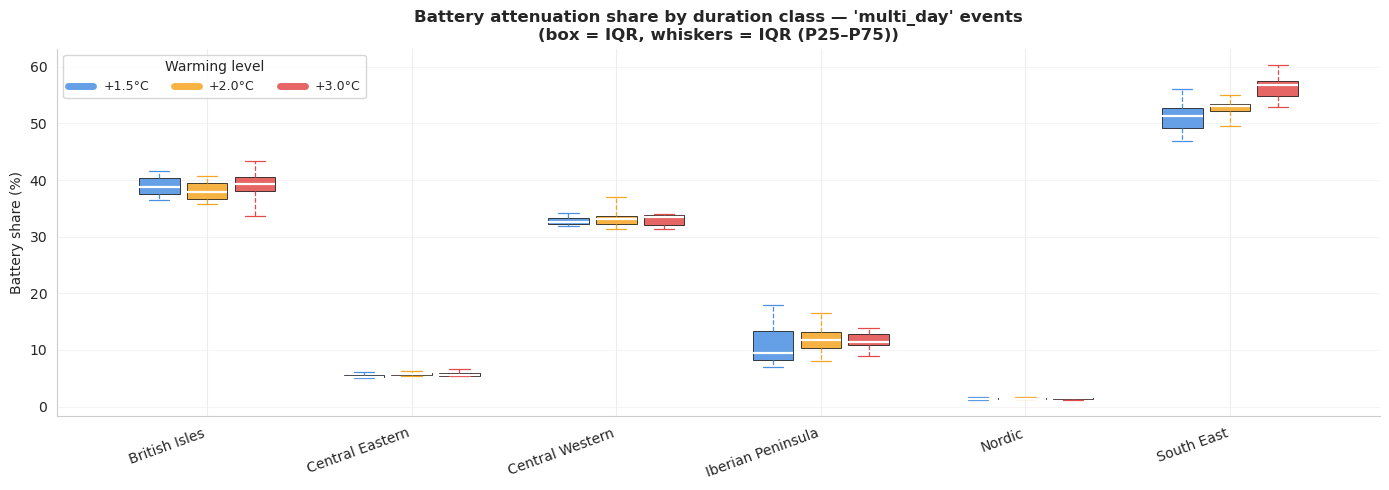

In [37]:
# Flexibility attenuation by duration class (combined + Shapley shares)
_box_by_duration(df_flex_dc, "combined_attenuation_pct",        "Combined attenuation (%)", "Flexibility attenuation by duration class")
_box_by_duration(df_flex_dc, "reservoir_attenuation_share_pct", "Reservoir share (%)",      "Reservoir attenuation share by duration class")
_box_by_duration(df_flex_dc, "battery_attenuation_share_pct",   "Battery share (%)",        "Battery attenuation share by duration class")

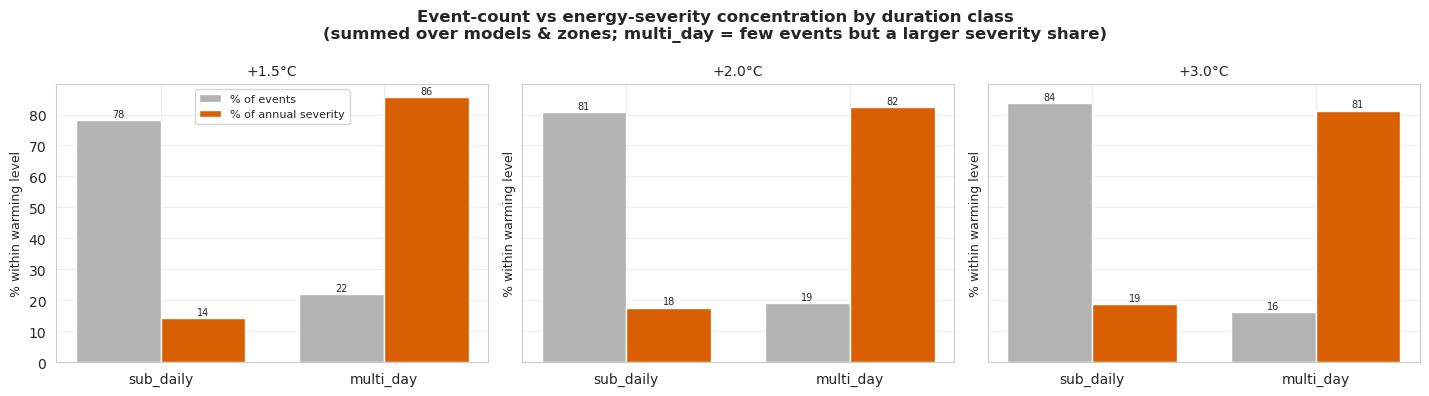

In [38]:
# Event-count vs energy-severity concentration by duration class
_sev_color = "#d95f02"
fig, axes = plt.subplots(1, len(period_names), figsize=(4.8 * len(period_names), 4), sharey=True)
if len(period_names) == 1:
    axes = [axes]
for ax, p in zip(axes, period_names):
    sub = df_annual[df_annual["period"] == p]
    ev = sub.groupby("duration_class")["n_events"].sum().reindex(DURATION_CLASS_ORDER).fillna(0)
    sv = sub.groupby("duration_class")["total_annual_severity_gwh"].sum().reindex(DURATION_CLASS_ORDER).fillna(0)
    ev_pct = ev / ev.sum() * 100 if ev.sum() > 0 else ev * 0
    sv_pct = sv / sv.sum() * 100 if sv.sum() > 0 else sv * 0
    x = np.arange(len(DURATION_CLASS_ORDER)); w = 0.38
    ax.bar(x - w / 2, ev_pct.values, w, color="0.7",       edgecolor="white", label="% of events")
    ax.bar(x + w / 2, sv_pct.values, w, color=_sev_color,  edgecolor="white", label="% of annual severity")
    for xi in range(len(DURATION_CLASS_ORDER)):
        ax.text(xi - w / 2, ev_pct.values[xi] + 1, f"{ev_pct.values[xi]:.0f}", ha="center", fontsize=7)
        ax.text(xi + w / 2, sv_pct.values[xi] + 1, f"{sv_pct.values[xi]:.0f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(DURATION_CLASS_ORDER); ax.set_title(p, fontsize=10)
    ax.set_ylabel("% within warming level", fontsize=9)
axes[0].legend(fontsize=8)
fig.suptitle("Event-count vs energy-severity concentration by duration class\n"
             "(summed over models & zones; multi_day = few events but a larger severity share)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

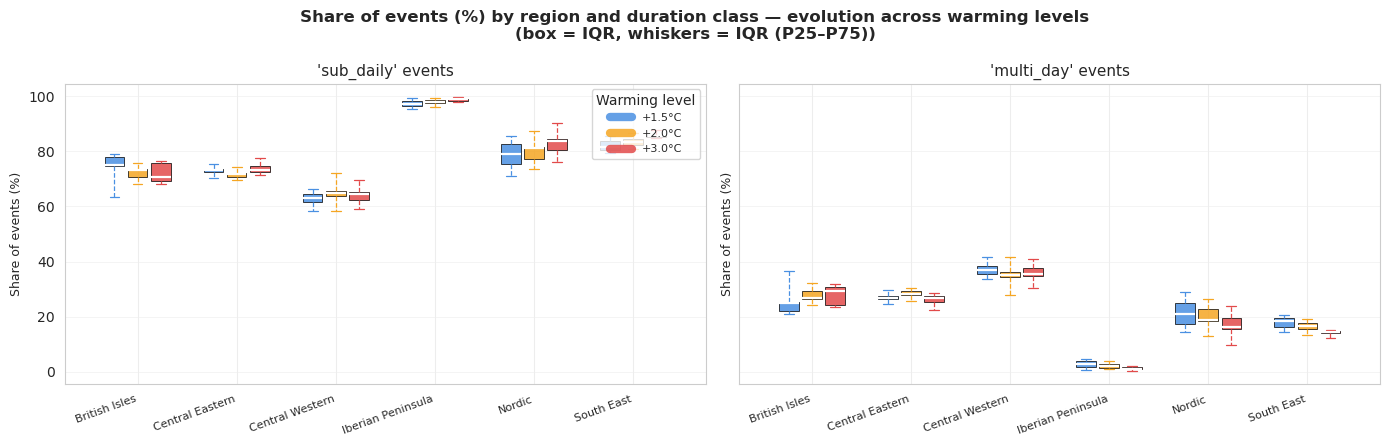

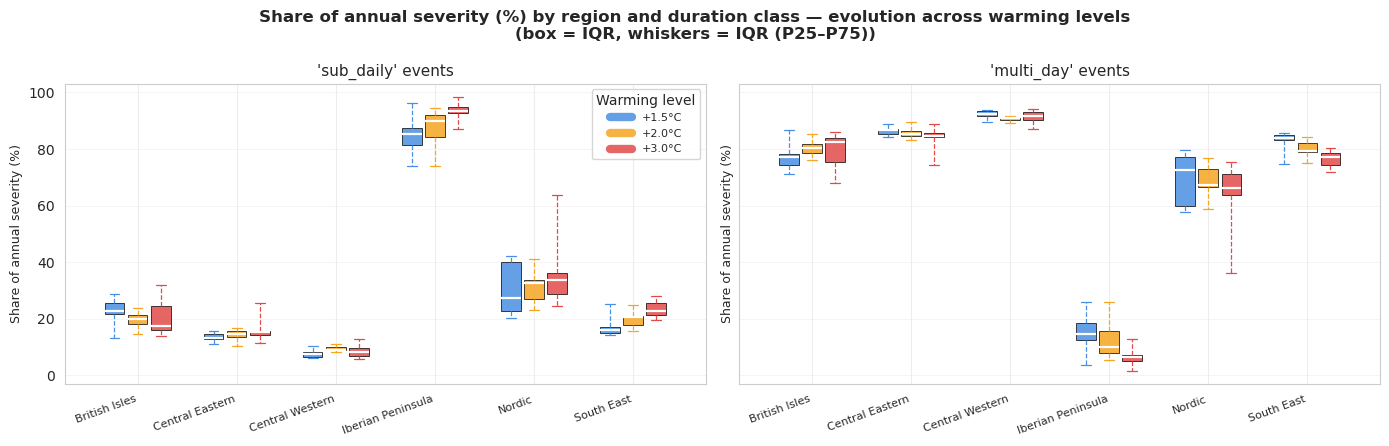

In [39]:
# Concentration per region, with inter-model spread and GWL evolution.
# For each duration class, its share of events / severity WITHIN each (model, period,
# zone) is computed; boxes span the 9 models, coloured by warming level.
_g = (df_annual.groupby(["model", "period", "zone", "duration_class"])
      [["n_events", "total_annual_severity_gwh"]].sum().reset_index())
_g["ev_tot"] = _g.groupby(["model", "period", "zone"])["n_events"].transform("sum")
_g["sv_tot"] = _g.groupby(["model", "period", "zone"])["total_annual_severity_gwh"].transform("sum")
_g["ev_share"] = np.where(_g["ev_tot"] > 0, _g["n_events"] / _g["ev_tot"] * 100, np.nan)
_g["sv_share"] = np.where(_g["sv_tot"] > 0, _g["total_annual_severity_gwh"] / _g["sv_tot"] * 100, np.nan)

def _conc_figure(col, label):
    """One figure; subplot per duration class; x = region; one box per warming
    level (period-coloured) across models. box = IQR, whiskers = SPREAD."""
    _whis = list(spread_qpair("minmax"))
    _pn   = list(period_defs.keys())
    _np   = len(_pn)
    _zl   = [str(z) for z in zones]
    _zx   = np.arange(len(_zl))
    _bw   = 0.7 / _np
    fig, axes = plt.subplots(1, len(DURATION_CLASS_ORDER),
                             figsize=(7 * len(DURATION_CLASS_ORDER), 4.5), sharey=True)
    if len(DURATION_CLASS_ORDER) == 1:
        axes = [axes]
    for ax, dc in zip(axes, DURATION_CLASS_ORDER):
        ddc = _g[_g["duration_class"] == dc]
        for pi, p in enumerate(_pn):
            color = period_colors[p]
            offs  = _zx + (pi - _np / 2 + 0.5) * _bw
            data, pos = [], []
            for zi, z in enumerate(_zl):
                v = ddc[(ddc["period"] == p) & (ddc["zone"] == z)][col].dropna().values
                if v.size:
                    data.append(v); pos.append(offs[zi])
            if data:
                ax.boxplot(data, positions=pos, widths=_bw * 0.85, patch_artist=True,
                           whis=_whis, showfliers=False,
                           medianprops=dict(color="white", linewidth=1.6),
                           boxprops=dict(facecolor=color, alpha=0.85, linewidth=0.6),
                           whiskerprops=dict(color=color, linewidth=0.9, linestyle="--"),
                           capprops=dict(color=color, linewidth=0.9))
            ax.plot([], [], color=color, linewidth=6, alpha=0.85, label=p)
        ax.set_title(f"'{dc}' events", fontsize=11)
        ax.set_xticks(_zx)
        ax.set_xticklabels([z.replace("_", " ") for z in _zl], rotation=20, ha="right", fontsize=8)
        ax.set_ylabel(label, fontsize=9)
        ax.grid(axis="y", linewidth=0.4)
    axes[0].legend(title="Warming level", fontsize=8, loc="upper right")
    fig.suptitle(
        f"{label} by region and duration class — evolution across warming levels\n"
        f"(box = IQR, whiskers = {SPREAD_LABEL[SPREAD]})",
        fontsize=12, fontweight="bold",
    )
    plt.tight_layout(); plt.show()

_conc_figure("ev_share", "Share of events (%)")
_conc_figure("sv_share", "Share of annual severity (%)")


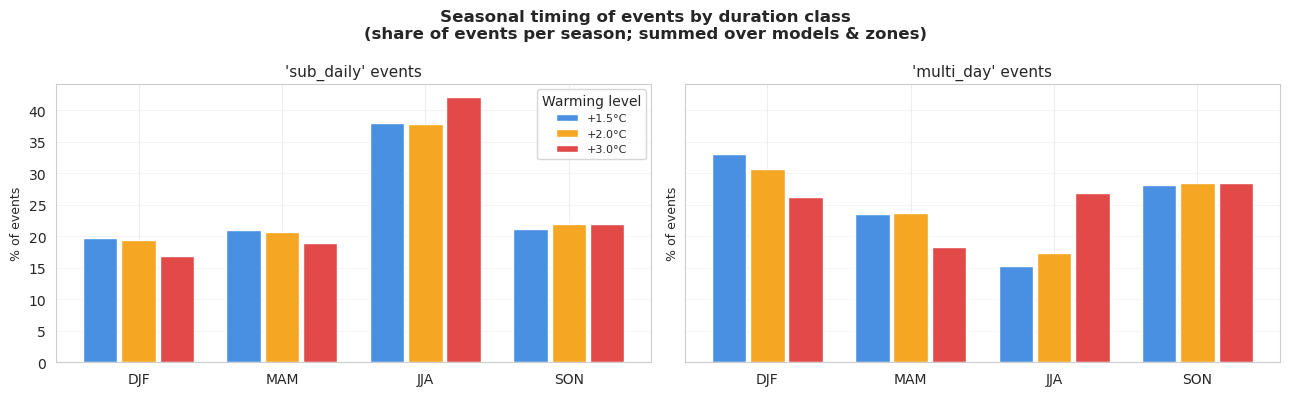

In [40]:
# Seasonal timing: distribution of events across seasons, per duration class
_pn = list(period_defs.keys()); _bw = 0.8 / len(_pn); _sx = np.arange(len(season_order))
fig, axes = plt.subplots(1, len(DURATION_CLASS_ORDER),
                         figsize=(6.5 * len(DURATION_CLASS_ORDER), 4), sharey=True)
if len(DURATION_CLASS_ORDER) == 1:
    axes = [axes]
for ax, dc in zip(axes, DURATION_CLASS_ORDER):
    sub = df_seasonal_dc[df_seasonal_dc["duration_class"] == dc]
    for pi, p in enumerate(_pn):
        cnt = sub[sub["period"] == p].groupby("season")["n_events"].sum().reindex(season_order, fill_value=0)
        share = cnt / cnt.sum() * 100 if cnt.sum() > 0 else cnt * 0
        ax.bar(_sx + (pi - len(_pn) / 2 + 0.5) * _bw, share.values, _bw * 0.9,
               color=period_colors[p], edgecolor="white", label=p)
    ax.set_title(f"'{dc}' events", fontsize=11)
    ax.set_xticks(_sx); ax.set_xticklabels(season_order)
    ax.set_ylabel("% of events", fontsize=9); ax.grid(axis="y", linewidth=0.4)
axes[0].legend(title="Warming level", fontsize=8)
fig.suptitle("Seasonal timing of events by duration class\n(share of events per season; summed over models & zones)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()